# 🏪 Previsão de Vendas da Rossmann (6 semanas por loja)

**Autor:** Rafael R. Silva · **Metodologia:** CRISP-DM · **Tipo de problema:** regressão com dados no tempo (prever a venda diária em euros)

> **Resumo:** com **1.017.209 registros de vendas diárias** de **1.115 lojas** da rede de farmácias **Rossmann** (Alemanha, jan/2013 a jul/2015), treinamos um modelo que prevê a **venda de cada loja em cada dia** das próximas 6 semanas. Somando os dias, o CFO recebe o **total de 6 semanas de cada loja**, com uma **faixa de erro** medida em semanas que o modelo nunca viu, para decidir quanto cada loja pode investir em reforma. No caminho, testamos 12 hipóteses sobre o que faz uma loja vender mais, sempre com médias, teste estatístico e tamanho do efeito.

---

### 📑 Sumário
- **FASE 01:** Entendimento do Negócio
- **FASE 02:** Preparação dos Dados (coleta, limpeza, vazamento, EDA com 12 hipóteses)
- **FASE 03:** Modelagem (validação cruzada no tempo, 8 modelos, ajuste fino, faixa de erro, teste anti-vazamento)
- **FASE 04:** Avaliação (teste, erro do total por loja, tradução do erro, variáveis mais importantes)
- **FASE 05:** Implantação (modelo salvo, ficha do modelo e previsão das 6 semanas seguintes)
- **Respostas**, **Insights**, **Próximos Passos** e **Interface com Streamlit**

> ℹ️ **Sobre esta versão (v2):** a versão original continua no repositório para mostrar a evolução. Principais correções:
> - a EDA original **somava** as vendas em vez de tirar a **média**, e por isso concluiu que as vendas caíam ao longo dos anos, que o domingo vendia menos e que o sortimento "extra" vendia pouco. Com médias, **as três conclusões se invertem**;
> - o **"modelo da média" usava as respostas do teste** (média de cada loja calculada nas próprias semanas avaliadas);
> - o XGBoost tinha um **parâmetro digitado errado** (`colsample_bytee`, ignorado em silêncio), e o modelo final usava hiperparâmetros que não estavam entre os testados;
> - os **cenários de pior e melhor caso** somavam ao total de 6 semanas o erro de **um único dia**, e por isso ficavam estreitos demais;
> - as escalas eram ajustadas na base toda antes da separação, e o arquivo de produção salvava a escala errada para o mês e o ano;
> - as vendas estão em **euros** (a versão original escrevia R$).

# FASE 01: ENTENDIMENTO DO NEGÓCIO

## 🏢 Contexto

A **Rossmann** é uma das maiores redes de drogarias da Europa, com mais de 3 mil lojas em 7 países. Neste cenário (baseado numa competição do Kaggle), o **CFO** quer reformar as lojas e precisa decidir **quanto cada uma pode investir**. A regra é reservar uma **parcela do faturamento das próximas 6 semanas**, e por isso pediu aos gerentes uma previsão de vendas de cada loja.

| Se a previsão fica... | O que acontece |
|---|---|
| **Alta demais** | A loja recebe uma verba de reforma que o caixa dela não sustenta |
| **Baixa demais** | A reforma é adiada ou fica menor do que a loja poderia pagar |

Hoje cada gerente faz a sua previsão do seu jeito, com critérios diferentes. Um modelo treinado com o histórico de **todas** as lojas dá uma previsão **objetiva, igual para todas e com margem de erro conhecida**.

## 🎯 Objetivo

> **Perguntas de negócio:**
> 1. **Quanto cada loja vai vender** nas próximas 6 semanas? Com que **margem de erro**?
> 2. **O que faz uma loja vender mais:** promoção, dia da semana, época do ano, tipo de loja, sortimento, concorrência?
> 3. Em quais **lojas e situações** a previsão é mais confiável?
> 4. Quanto a rede pode reservar para **reforma**, loja a loja?

**Stakeholders:** CFO (decisão do orçamento) e gerentes das lojas.

## 🧩 Formato da solução

| Item | Definição |
|---|---|
| **Granularidade** | 1 linha por **loja por dia** (a previsão de 6 semanas é a soma dos dias) |
| **Fonte** | Competição *Rossmann Store Sales* (Kaggle): vendas diárias de 1.115 lojas + cadastro das lojas |
| **Tipo de problema** | **Regressão com dados no tempo**: o alvo é a **venda do dia em euros** |
| **Métricas** | MAE e RMSE (em €), MAPE e MPE (em %), R² e o **erro do total de 6 semanas por loja** (a métrica do negócio) |
| **Entrega** | Notebook + README, modelo salvo com ficha e um **app Streamlit** com a previsão de cada loja e o orçamento de reforma da rede |

## 🗺️ Planejamento da solução (CRISP-DM)

| Fase | O que será feito |
|---|---|
| **01. Entendimento do negócio** | Definir as perguntas e o público |
| **02. Preparação dos dados** | Juntar vendas e cadastro, tratar os nulos com sentido de negócio, achar a lacuna das 180 lojas, retirar a variável com vazamento e testar 12 hipóteses |
| **03. Modelagem** | Separar no tempo (treino, validação e teste), comparar 8 modelos com validação cruzada no tempo, ajustar o melhor e medir a faixa de erro do total de 6 semanas |
| **04. Avaliação** | Medir o erro no teste (as mesmas 6 semanas da versão original) e traduzi-lo por loja e por tipo de loja |
| **05. Implantação** | Salvar o modelo com a ficha e prever as 6 semanas seguintes (app Streamlit) |

> 💡 Como os dados estão **ordenados no tempo**, a separação e a validação cruzada **respeitam a ordem das datas**: o modelo sempre treina no passado e é avaliado no futuro, como acontecerá no uso real. O **balanceamento** e o **limiar** não se aplicam a uma regressão; o motivo está explicado em cada etapa.

# FASE 02: PREPARAÇÃO DOS DADOS

## 1 - COLETA DOS DADOS

### 1.1. Bibliotecas

In [1]:
import sys
import time

import joblib
import numpy             as np
import pandas            as pd
import seaborn           as sns
import matplotlib.pyplot as plt

from sklearn.base            import clone
from sklearn.compose         import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble        import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection      import permutation_importance
from sklearn.linear_model    import LinearRegression, Lasso
from sklearn.model_selection import cross_validate, RandomizedSearchCV
from sklearn.pipeline        import Pipeline
from sklearn.preprocessing   import OneHotEncoder, StandardScaler

import xgboost               as xgb
import lightgbm              as lgb

import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')

#### Funções auxiliares

As funções reutilizáveis ficam na pasta **`src/`** do projeto (também usadas pelo app Streamlit e pelos testes):

| Arquivo | Funções | Para que serve |
|---|---|---|
| `src/config.py` | `SEMENTE`, `FEATURES`, `PROIBIDAS`, datas de corte | Constantes do projeto num só lugar |
| `src/dados.py` | `carregar_base`, `carregar_lojas`, `criar_variaveis` | Lê e junta vendas e cadastro, traduz e cria as variáveis de calendário, concorrência e Promo2 |
| `src/dados.py` | `filtrar_dias_com_venda`, `separar_periodos`, `carregar_futuro` | Dias com venda, separação no tempo e as 6 semanas a prever |
| `src/modelos.py` | `MediasDaLoja`, `MediaPorGrupo` | Médias de venda da loja aprendidas só no treino (dentro do `Pipeline`) e os modelos de referência |
| `src/validacao.py` | `dobras_temporais`, `periodos_das_dobras` | Validação cruzada que treina no passado e avalia nas 6 semanas seguintes |
| `src/estatistica.py` | `teste_mann_whitney`, `teste_kruskal`, `teste_spearman`, `teste_wilcoxon`, `regra_iqr` | Testes das hipóteses com tamanho do efeito e regra do IQR |
| `src/selecao.py` | `importancia_random_forest`, `selecao_features` | Seleção de variáveis por Random Forest e Informação Mútua |
| `src/avaliacao.py` | `ml_error`, `relatorio_validacao`, `plot_comparacao_modelos` | Métricas em euros e avaliação padronizada de cada algoritmo |
| `src/avaliacao.py` | `totais_por_loja`, `erro_total_6_semanas`, `faixa_relativa`, `cobertura_faixa`, `erro_por_grupo`, `salvar_ficha_modelo` | Erro do total de 6 semanas, faixa de erro, tradução do erro e ficha do modelo |
| `src/graficos.py` | `plot_barras_h`, `plot_boxplot_grupos`, `euros`, `pct` | Gráficos e formatação em português |

In [2]:
sys.path.append('..')  # permite importar a pasta src/ a partir de Notebooks/

from src.config import (ARQUIVO_VENDAS, ARQUIVO_LOJAS, ARQUIVO_FUTURO, SEMENTE, ALVO, FEATURES, CATEGORICAS, NUMERICAS,
                        MEDIAS_LOJA, PROIBIDAS, INICIO_VALIDACAO, INICIO_TESTE, DISTANCIA_SEM_CONCORRENTE, N_JOBS)
from src.dados import (carregar_base, carregar_lojas, criar_variaveis, filtrar_dias_com_venda, separar_periodos,
                       carregar_futuro)
from src.modelos import MediasDaLoja, MediaPorGrupo
from src.validacao import dobras_temporais, periodos_das_dobras
from src.estatistica import teste_mann_whitney, teste_kruskal, teste_spearman, teste_wilcoxon, regra_iqr
from src.selecao import importancia_random_forest, selecao_features
from src.avaliacao import (ml_error, relatorio_validacao, plot_comparacao_modelos, totais_por_loja, erro_total_6_semanas,
                           faixa_relativa, cobertura_faixa, erro_por_grupo, salvar_ficha_modelo)
from src.graficos import (plot_barras_h, plot_boxplot_grupos, salvar, titulo, euros, pct,
                          COR_PRINCIPAL, COR_DESTAQUE, COR_NEUTRA)

### 1.2. Salvar a base em CSV

As bases já vêm em CSV da competição do Kaggle e ficam intocadas na pasta **`Datasets/`**:

| Arquivo | Conteúdo |
|---|---|
| `train.csv` | Venda diária de cada loja, de 01/01/2013 a 31/07/2015 (é a base do modelo) |
| `store.csv` | Cadastro das 1.115 lojas: tipo, sortimento, concorrência e Promo2 |
| `test.csv` | As **6 semanas seguintes** (01/08 a 17/09/2015), **sem as vendas**: é o que o modelo final vai prever na Fase 05 |

In [3]:
for arquivo in [ARQUIVO_VENDAS, ARQUIVO_LOJAS, ARQUIVO_FUTURO]:
    print(f'{arquivo.name:10s} | {arquivo.stat().st_size / 1024 ** 2:5.1f} MB')

train.csv  |  37.3 MB
store.csv  |   0.0 MB
test.csv   |   1.4 MB


## 2 - LIMPEZA DOS DADOS

### 2.1. Leitura dos dados

In [4]:
vendas_original = pd.read_csv(ARQUIVO_VENDAS, dtype={'StateHoliday': str}, nrows=5)
lojas_original = pd.read_csv(ARQUIVO_LOJAS, nrows=5)
display(vendas_original)
display(lojas_original)

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270,9,2008,0,NaN,NaN,NaN
1,2,a,a,570,11,2007,1,13.000,"2,010.000","Jan,Apr,Jul,Oct"
2,3,a,a,14130,12,2006,1,14.000,"2,011.000","Jan,Apr,Jul,Oct"
3,4,c,c,620,9,2009,0,NaN,NaN,NaN
4,5,a,a,29910,4,2015,0,NaN,NaN,NaN


In [5]:
t0 = time.time()
base = carregar_base(ARQUIVO_VENDAS, ARQUIVO_LOJAS)   # vendas + cadastro, traduzidos e com tipos enxutos
lojas = carregar_lojas(ARQUIVO_LOJAS)
print(f'Base lida e juntada em {time.time() - t0:.0f}s | memória: {base.memory_usage(deep=True).sum() / 1024 ** 2:.0f} MB')
base.head()

Base lida e juntada em 10s | memória: 44 MB


,loja,dia_semana,data,vendas,clientes,aberta,promo,feriado,feriado_escolar,tipo_loja,sortimento,distancia_concorrente,concorrente_desde_mes,concorrente_desde_ano,promo2,promo2_desde_semana,promo2_desde_ano,promo2_meses
0,1,2,2013-01-01,0,0,0,0,público,1,c,básico,"1,270.000",9.000,"2,008.000",0,NaN,NaN,NaN
1,2,2,2013-01-01,0,0,0,0,público,1,a,básico,570.000,11.000,"2,007.000",1,13.000,"2,010.000","Jan,Apr,Jul,Oct"
2,3,2,2013-01-01,0,0,0,0,público,1,a,básico,"14,130.000",12.000,"2,006.000",1,14.000,"2,011.000","Jan,Apr,Jul,Oct"
3,4,2,2013-01-01,0,0,0,0,público,1,c,estendido,620.000,9.000,"2,009.000",0,NaN,NaN,NaN
4,5,2,2013-01-01,0,0,0,0,público,1,a,básico,"29,910.000",4.000,"2,015.000",0,NaN,NaN,NaN


#### 📖 Dicionário de dados (após a tradução)

| Coluna | Coluna original | Descrição |
|---|---|---|
| `loja` | `Store` | Número da loja (1 a 1.115) |
| `data`, `dia_semana` | `Date`, `DayOfWeek` | Data e dia da semana (1 = segunda, 7 = domingo) |
| `vendas` | `Sales` | 🎯 **Alvo**: venda do dia, em **euros** |
| `clientes` | `Customers` | Clientes no dia ⚠️ **vazamento** (ver seção 🛡️) |
| `aberta` | `Open` | 1 se a loja abriu no dia |
| `promo` | `Promo` | 1 se a loja estava em promoção no dia |
| `feriado` | `StateHoliday` | Feriado estadual: nenhum, público, Páscoa ou Natal |
| `feriado_escolar` | `SchoolHoliday` | 1 se as escolas estavam fechadas |
| `tipo_loja` | `StoreType` | Modelo da loja: a, b, c ou d (a base não explica a diferença) |
| `sortimento` | `Assortment` | Variedade de produtos: básico, extra ou estendido |
| `distancia_concorrente` | `CompetitionDistance` | Distância até o concorrente mais próximo, em metros |
| `concorrente_desde_mes`, `concorrente_desde_ano` | `CompetitionOpenSince...` | Quando o concorrente abriu |
| `promo2` | `Promo2` | 1 se a loja participa da **Promo2**, uma promoção contínua que reinicia em meses fixos |
| `promo2_desde_semana`, `promo2_desde_ano` | `Promo2Since...` | Quando a loja aderiu à Promo2 |
| `promo2_meses` | `PromoInterval` | Meses em que a Promo2 reinicia (ex.: "Jan,Apr,Jul,Oct") |

### 2.2. Colunas

In [6]:
print(base.columns.to_list())
base.dtypes.to_frame('tipo').T

['loja', 'dia_semana', 'data', 'vendas', 'clientes', 'aberta', 'promo', 'feriado', 'feriado_escolar', 'tipo_loja', 'sortimento', 'distancia_concorrente', 'concorrente_desde_mes', 'concorrente_desde_ano', 'promo2', 'promo2_desde_semana', 'promo2_desde_ano', 'promo2_meses']


,loja,dia_semana,data,vendas,clientes,aberta,promo,feriado,feriado_escolar,tipo_loja,sortimento,distancia_concorrente,concorrente_desde_mes,concorrente_desde_ano,promo2,promo2_desde_semana,promo2_desde_ano,promo2_meses
tipo,int16,int8,datetime64[us],int32,int16,int8,int8,category,int8,category,category,float32,float32,float32,int8,float32,float32,category


📌 **Nota**
- 🔎 São **18 colunas**: as 9 de vendas e as 10 do cadastro, juntas pela loja (a coluna `loja` aparece uma vez).
- 🔎 Os tipos foram **reduzidos** na leitura (`int8`, `int16`, `float32`, `category`): a base inteira ocupa só **44 MB** na memória. Isso importa numa máquina de 8 GB, que vai treinar 8 modelos com mais de 765 mil linhas.

### 2.3. Dimensões dos dados

In [7]:
print(f"Linhas (loja x dia): {len(base):,} | colunas: {base.shape[1]}".replace(',', '.'))
print(f"Lojas: {base['loja'].nunique():,} | período: {base['data'].min():%d/%m/%Y} a {base['data'].max():%d/%m/%Y} "
      f"({base['data'].nunique()} dias)".replace(',', '.'))
dias_por_loja = base.groupby('loja').size()
display(dias_por_loja.value_counts().rename_axis('dias com registro').to_frame('lojas'))

Linhas (loja x dia): 1.017.209 | colunas: 18


Lojas: 1.115 | período: 01/01/2013 a 31/07/2015 (942 dias)


,lojas
dias com registro,
942,934
758,180
941,1


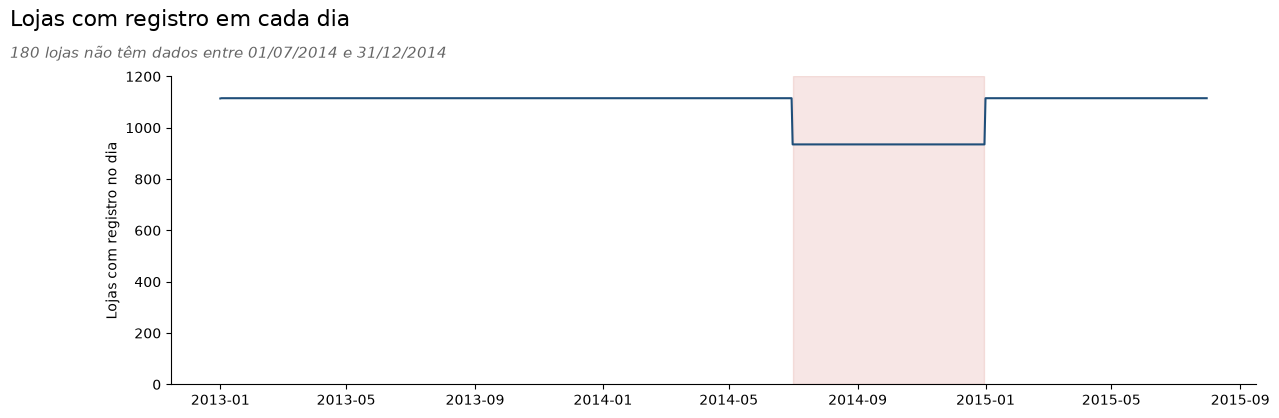

Lojas com a lacuna: 180 | dias da lacuna: 184


In [8]:
# Quantas lojas aparecem na base em cada dia?
lojas_por_dia = base.groupby('data')['loja'].nunique()
lojas_lacuna = dias_por_loja[dias_por_loja < 900].index
periodo_lacuna = lojas_por_dia[lojas_por_dia < 1000]
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(lojas_por_dia.index, lojas_por_dia.values, color=COR_PRINCIPAL)
ax.axvspan(periodo_lacuna.index.min(), periodo_lacuna.index.max(), color=COR_DESTAQUE, alpha=0.12)
ax.set(ylabel='Lojas com registro no dia', ylim=(0, 1200))
sns.despine()
titulo('Lojas com registro em cada dia', f'{len(lojas_lacuna)} lojas não têm dados entre '
       f'{periodo_lacuna.index.min():%d/%m/%Y} e {periodo_lacuna.index.max():%d/%m/%Y}')
salvar('Lojas por dia')
plt.show()
print(f'Lojas com a lacuna: {len(lojas_lacuna)} | dias da lacuna: {len(periodo_lacuna)}')

📌 **Nota: 180 lojas somem por 6 meses**
- 🔎 São **1.017.209 registros** (loja × dia) de **1.115 lojas**, de 01/01/2013 a 31/07/2015 (**942 dias**).
- 🔎 **934 lojas** têm todos os 942 dias, mas **180 lojas** têm só 758: elas **não têm nenhum registro** entre **01/07/2014 e 31/12/2014** (**184 dias**).
- ⚠️ A versão original não percebeu a lacuna. Ao **somar** as vendas por ano, 2014 perdia o 2º semestre de 180 lojas, e 2015 tem só 7 meses: daí a conclusão de que "as vendas caem ao longo dos anos" (H5).
- ✅ **Decisão:** comparar grupos sempre pela **venda média por dia de loja aberta**, e comparar anos só com as **lojas sem lacuna** e os **mesmos meses** (H5). Para o modelo, a lacuna não é problema: ele aprende com os dias que existem.

### 2.4. Valores nulos

In [9]:
nulos = base.isna().sum()
nulos_lojas = lojas.isna().sum()
pd.DataFrame({'nulos na base (loja x dia)': nulos[nulos > 0], 'lojas com nulo no cadastro': nulos_lojas[nulos_lojas > 0]})

,nulos na base (loja x dia),lojas com nulo no cadastro
distancia_concorrente,2642,3
concorrente_desde_mes,323348,354
concorrente_desde_ano,323348,354
promo2_desde_semana,508031,544
promo2_desde_ano,508031,544
promo2_meses,508031,544


In [10]:
# Os nulos têm sentido de negócio: quem não participa da Promo2 não tem data de adesão
print('Lojas sem data de adesão à Promo2, por participação:')
display(pd.crosstab(lojas['promo2'], lojas['promo2_desde_ano'].isna(), margins=True)
        .rename(columns={True: 'sem data', False: 'com data'}))
print(f"Lojas sem distância do concorrente: {lojas['distancia_concorrente'].isna().sum()} | "
      f"maior distância informada: {lojas['distancia_concorrente'].max():,.0f} m".replace(',', '.'))

Lojas sem data de adesão à Promo2, por participação:


promo2_desde_ano,com data,sem data,All
promo2,,,
0,0,544,544
1,571,0,571
All,571,544,1115


Lojas sem distância do concorrente: 3 | maior distância informada: 75.860 m


**Como cada nulo foi tratado** (em `criar_variaveis`, `src/dados.py`):

| Nulo | Significado | Tratamento |
|---|---|---|
| Distância do concorrente | Não há concorrente informado perto da loja | Vira **100 km** (mais longe que qualquer concorrente da base) e ganha o indicador `sem_concorrente` |
| Data de abertura do concorrente | A data não foi registrada | Criamos `meses_concorrente` (meses desde a abertura); sem data, vira 0 e o indicador `concorrente_data_desconhecida` fica 1 |
| Datas e meses da Promo2 | A loja **não participa** da Promo2 | Criamos `semanas_promo2` (semanas desde a adesão) e `promo2_mes_ativo` (mês de reinício da promoção); para quem não participa, ambos ficam 0 |

> ⚠️ A versão original preenchia a distância nula com a **média** (5,4 km), como se essas lojas tivessem um concorrente a uma distância comum, e as datas nulas com **0**, usadas cruas como se fossem o ano 0.

In [11]:
base = criar_variaveis(base)
criadas = ['sem_concorrente', 'meses_concorrente', 'concorrente_data_desconhecida', 'semanas_promo2', 'promo2_mes_ativo']
print('Nulos restantes nas colunas usadas pelo modelo:', int(base[FEATURES].isna().sum().sum()))
base[criadas].describe().T[['mean', 'min', 'max']]

Nulos restantes nas colunas usadas pelo modelo: 0


,mean,min,max
sem_concorrente,0.003,0.000,1.000
meses_concorrente,41.149,-31.000,"1,386.000"
concorrente_data_desconhecida,0.318,0.000,1.000
semanas_promo2,57.134,0.000,313.571
promo2_mes_ativo,0.149,0.000,1.000


📌 **Nota: os nulos têm significado**
- 🔎 As datas da Promo2 faltam em **544 lojas**, que são **exatamente** as 544 que **não participam** da Promo2: o nulo quer dizer "não se aplica", não "dado perdido".
- 🔎 A data de abertura do concorrente falta em **354 lojas**, e a distância, em só **3** (a maior distância informada é **75.860 m**).
- 🔎 Depois de `criar_variaveis`, as colunas do modelo ficam com **0 nulos**. `meses_concorrente` vai de **−31** (o concorrente ainda vai abrir) a **1.386** (uma data de abertura por volta de 1900, que na prática quer dizer "concorrente antigo").
- ✅ **Decisão:** tratar cada nulo pelo que ele significa (tabela acima) e marcar com indicadores (`sem_concorrente`, `concorrente_data_desconhecida`), em vez de preencher com a média.

### 2.5. Estatística descritiva

In [12]:
fechadas = base['aberta'] == 0
abertas_sem_venda = (base['aberta'] == 1) & (base['vendas'] == 0)
print(f"Dias de loja fechada: {fechadas.sum():,} ({fechadas.mean():.1%}) | venda máxima com a loja fechada: "
      f"{base.loc[fechadas, 'vendas'].max()}".replace(',', '.'))
print(f"Dias de loja aberta com venda zero: {abertas_sem_venda.sum()}")
print('Por que a loja fecha? (dias fechados por dia da semana e por feriado)')
display(pd.concat([base.loc[fechadas, 'dia_semana'].value_counts(normalize=True).sort_index().rename('% dos dias fechados'),
                   base.loc[fechadas, 'feriado'].value_counts(normalize=True).rename('% dos dias fechados')]).to_frame().T)

df = filtrar_dias_com_venda(base)   # o modelo aprende só com os dias em que a loja abriu e vendeu
print(f'Dias com venda (base do modelo): {len(df):,}'.replace(',', '.'))

Dias de loja fechada: 172.817 (17.0%) | venda máxima com a loja fechada: 0
Dias de loja aberta com venda zero: 54
Por que a loja fecha? (dias fechados por dia da semana e por feriado)


,1,2,3,4,5,6,7,nenhum,público,Páscoa,Natal
% dos dias fechados,0.041,0.010,0.022,0.065,0.042,0.004,0.817,0.826,0.113,0.038,0.023


Dias com venda (base do modelo): 844.338


In [13]:
numericas_eda = ['vendas', 'clientes', 'distancia_concorrente', 'meses_concorrente', 'semanas_promo2']
df[numericas_eda].describe(percentiles=[0.25, 0.5, 0.75, 0.99]).T

,count,mean,std,min,25%,50%,75%,99%,max
vendas,"844,338.000","6,955.959","3,103.816",46.000,"4,859.000","6,369.000","8,360.000","17,789.000","41,551.000"
clientes,"844,338.000",762.777,401.194,8.000,519.000,676.000,893.000,"2,415.000","7,388.000"
distancia_concorrente,"844,338.000","5,702.927","9,160.384",20.000,710.000,"2,330.000","6,910.000","40,540.000","100,000.000"
meses_concorrente,"844,338.000",41.069,65.857,-31.000,0.000,16.000,73.000,196.000,"1,386.000"
semanas_promo2,"844,338.000",56.870,82.652,0.000,0.000,0.000,108.429,285.000,313.571


In [14]:
categoricas_eda = ['tipo_loja', 'sortimento', 'feriado', 'promo', 'promo2', 'feriado_escolar']
for coluna in categoricas_eda:
    print(df[coluna].value_counts(normalize=True).round(3).to_dict())
print(chr(10) + 'Lojas por tipo e sortimento (cadastro):')
pd.crosstab(lojas['tipo_loja'], lojas['sortimento'], margins=True)

{'a': 0.541, 'd': 0.306, 'c': 0.134, 'b': 0.018}
{'básico': 0.527, 'estendido': 0.463, 'extra': 0.01}
{'nenhum': 0.999, 'público': 0.001, 'Páscoa': 0.0, 'Natal': 0.0}
{0: 0.554, 1: 0.446}
{0: 0.501, 1: 0.499}
{0: 0.806, 1: 0.194}

Lojas por tipo e sortimento (cadastro):


sortimento,básico,estendido,extra,All
tipo_loja,,,,
a,381,221,0,602
b,7,1,9,17
c,77,71,0,148
d,128,220,0,348
All,593,513,9,1115


📌 **Nota**
- 🔎 Em **172.817 dias** (**17,0%**) a loja estava **fechada**, sempre com venda zero. **81,7%** desses dias são **domingos**. Há ainda **54 dias** de loja aberta com venda zero (provável falha de registro).
- ✅ **Decisão:** o modelo aprende só com os **844.338 dias** em que a loja abriu e vendeu. Na previsão, os dias fechados recebem venda zero (o calendário de abertura é conhecido com antecedência).
- 🔎 A venda do dia vai de **€ 46** a **€ 41.551**, com mediana de **€ 6.369** e média de **€ 6.956**. São em média **763 clientes** por dia.
- 🔎 O sortimento **extra** só existe em **9 lojas**, todas do **tipo b** (que tem só **17 lojas**). Os grupos pequenos explicam por que as **somas** da versão original enganavam: um grupo com poucas lojas soma pouco, mesmo que cada loja venda muito.
- 🔎 Há promoção em **44,6%** dos dias com venda, e feriado escolar em **19,4%**.

### 2.6. Outliers

In [15]:
# Regra do IQR (abaixo de Q1 - 1,5·IQR ou acima de Q3 + 1,5·IQR) nos dias com venda
pd.DataFrame({coluna: regra_iqr(df[coluna]) for coluna in ['vendas', 'clientes', 'distancia_concorrente']}).T.round(3)

,limite inferior,limite superior,outliers,% outliers
vendas,-392.500,"13,611.500","30,769.000",0.036
clientes,-42.000,"1,454.000","40,853.000",0.048
distancia_concorrente,"-8,590.000","16,210.000","83,661.000",0.099


In [16]:
# Os maiores dias de venda: são erros ou dias reais?
colunas_vistas = ['loja', 'data', 'dia_semana', 'vendas', 'clientes', 'promo', 'feriado', 'tipo_loja']
display(df.nlargest(6, 'vendas')[colunas_vistas])
limite_iqr = regra_iqr(df['vendas'])['limite superior']
acima = df[df['vendas'] > limite_iqr]
print(f'Dias acima do limite do IQR ({euros(limite_iqr)}): {len(acima):,}'.replace(',', '.'))
print(f"  em promoção: {acima['promo'].mean():.0%} (base: {df['promo'].mean():.0%}) | em dezembro: {(acima['mes'] == 12).mean():.0%} "
      f"(base: {(df['mes'] == 12).mean():.0%}) | lojas tipo b: {(acima['tipo_loja'] == 'b').mean():.0%} (base: {(df['tipo_loja'] == 'b').mean():.0%})")
print(f"  lojas diferentes: {acima['loja'].nunique()}")

,loja,data,dia_semana,vendas,clientes,promo,feriado,tipo_loja
806109,909,2015-06-22,1,41551,1721,0,nenhum,a
735149,262,2015-04-03,5,38722,5132,1,Páscoa,b
759853,262,2015-05-01,5,38484,5458,1,público,b
771076,262,2015-05-14,4,38367,5192,0,público,b
489791,57,2014-06-16,1,38037,1970,1,nenhum,d
325271,817,2013-12-16,1,38025,4381,1,nenhum,a


Dias acima do limite do IQR (€ 13.612): 30.769
  em promoção: 72% (base: 45%) | em dezembro: 17% (base: 6%) | lojas tipo b: 12% (base: 2%)
  lojas diferentes: 638


📌 **Nota**
- 🔎 A regra do IQR marca **30.769 dias** (**3,6%**) com venda acima de **€ 13.612**.
- 🔎 Esses dias têm **promoção** em **72%** dos casos (contra **45%** na base), caem em **dezembro** em **17%** (contra **6%**) e vêm de lojas **tipo b** em **12%** (contra **2%**). São **638 lojas** diferentes: não é uma loja com erro, é a venda alta real das promoções, do Natal e das lojas grandes.
- 🔎 O maior dia da base é da **loja 909** (**€ 41.551** em 22/06/2015, sem promoção), justamente no período de teste. Ela volta a aparecer como a loja mais difícil de prever (Fase 04).
- ✅ **Decisão:** **manter** todos os outliers. Removê-los ensinaria o modelo a ignorar as promoções e o Natal, que são exatamente os dias que mais pesam no total de 6 semanas.

### 2.7. Balanceamento do alvo

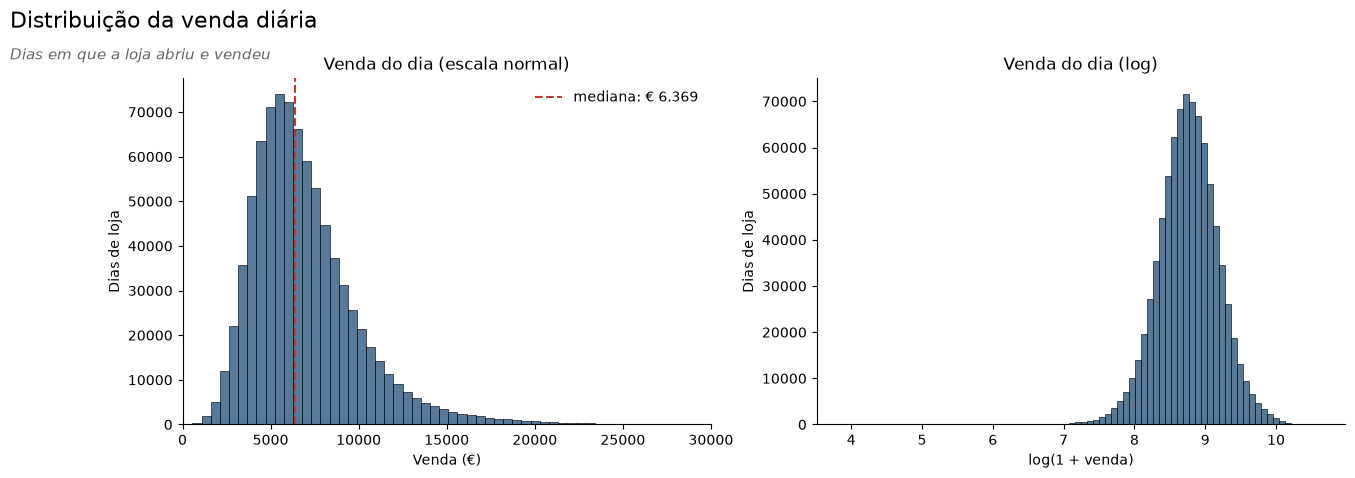

Assimetria: 1.59 (em log: -0.11) | média € 6.956 | mediana € 6.369


In [17]:
fig, axs = plt.subplots(1, 2, figsize=(15, 4.5))
sns.histplot(df[ALVO], bins=80, color=COR_PRINCIPAL, ax=axs[0])
axs[0].axvline(df[ALVO].median(), color=COR_DESTAQUE, ls='--', label=f'mediana: {euros(df[ALVO].median())}')
axs[0].set(title='Venda do dia (escala normal)', xlabel='Venda (€)', ylabel='Dias de loja', xlim=(0, 30000))
axs[0].legend(frameon=False)
sns.histplot(np.log1p(df[ALVO]), bins=80, color=COR_PRINCIPAL, ax=axs[1])
axs[1].set(title='Venda do dia (log)', xlabel='log(1 + venda)', ylabel='Dias de loja')
sns.despine()
titulo('Distribuição da venda diária', 'Dias em que a loja abriu e vendeu')
salvar('Distribuicao das vendas')
plt.show()
print(f"Assimetria: {df[ALVO].skew():.2f} (em log: {np.log1p(df[ALVO]).skew():.2f}) | média {euros(df[ALVO].mean())} | "
      f"mediana {euros(df[ALVO].median())}")

📌 **Nota**
- 🔎 A venda tem **cauda longa à direita** (assimetria de **1,59**): poucos dias muito altos puxam a média (**€ 6.956**) para cima da mediana (**€ 6.369**).
- 🔎 Em log, a distribuição fica quase simétrica (assimetria de **−0,11**).
- 🔎 Como é uma **regressão**, não há classes para balancear (item 4.2 da Fase 03).
- ✅ **Decisão:** treinar com o **log da venda** (item 3 da Fase 03), para que um erro de 10% pese o mesmo numa loja pequena e numa grande, e devolver a previsão em euros.

### 🛡️ Remoção de variáveis com vazamento (*data leakage*)

**Vazamento** acontece quando o modelo recebe uma informação que **contém a resposta** ou que só existe **depois** dela. O modelo parece ótimo no notebook e falha no uso real, porque essa informação não estará disponível na hora de prever.

Aqui a pergunta é: **o que o CFO sabe hoje sobre as próximas 6 semanas?** Ele sabe o calendário (dias, feriados), quais dias a loja abre, as promoções planejadas e o cadastro da loja. Ele **não** sabe quantos clientes vão entrar.

In [18]:
print(f"Correlação de Spearman entre clientes e vendas: {teste_spearman(df['clientes'], df[ALVO])['estatística']:.3f}")
print(f"Venda média por cliente: {euros(df[ALVO].sum() / df['clientes'].sum(), 2)}")
print("O arquivo das 6 semanas a prever (test.csv) tem a coluna de clientes?",
      'Customers' in pd.read_csv(ARQUIVO_FUTURO, nrows=1).columns)

Correlação de Spearman entre clientes e vendas: 0.832
Venda média por cliente: € 9,12
O arquivo das 6 semanas a prever (test.csv) tem a coluna de clientes? False


📌 **Nota: os clientes do dia são vazamento**
- 🔎 A correlação entre clientes e vendas é de **0,832**: a venda é praticamente **clientes × gasto médio** (**€ 9,12** por cliente).
- 🔎 Só que o número de clientes só é conhecido **depois que o dia acaba**. O próprio arquivo das 6 semanas a prever (`test.csv`) **não tem** essa coluna.
- ✅ **Decisão:** `clientes` fica **fora do modelo** (`PROIBIDAS` em `src/config.py`). Ela continua na EDA para explicar as vendas, e o item 9 da Fase 03 mostra o quanto ela inflaria o resultado.

## 3 - ANÁLISE EXPLORATÓRIA DOS DADOS (EDA)

### 3.1. Criação das Hipóteses

| # | Hipótese | Conclusão da versão original | Pergunta de negócio |
|---|---|---|---|
| **H1** | Lojas em **promoção** vendem mais | Verdadeira, +12% | 2 |
| **H2** | Lojas com **sortimento maior** vendem mais | Falsa ("vendem menos") | 2 |
| **H3** | Lojas com **concorrente mais perto** vendem menos | Falsa ("vendem mais") | 2 |
| **H4** | O **tipo de loja** muda a venda | Tipo "a" vende mais | 2 e 3 |
| **H5** | As lojas vendem **mais a cada ano** | Falsa ("vendem menos") | 2 |
| **H6** | As lojas vendem mais no **fim do ano** | Falsa ("vendem menos no 2º semestre") | 2 |
| **H7** | As lojas vendem mais **depois do dia 10** do mês | Verdadeira | 2 |
| **H8** | As lojas vendem **menos no fim de semana** | Verdadeira | 2 |
| **H9** | As lojas vendem **menos nos feriados escolares** | Verdadeira | 2 |
| **H10** | Lojas na **Promo2** (promoção contínua) vendem mais | Falsa | 2 |
| **H11** | A **abertura de um concorrente** reduz as vendas da loja | (não testada) | 2 |
| **H12** | Lojas **abertas em feriado** vendem mais | Falsa ("vendem menos no Natal") | 2 |

**Duas regras desta EDA:**
1. **Médias, não somas.** A soma das vendas de um grupo mistura **quanto cada loja vende** com **quantos dias o grupo tem**. Domingo tem poucas lojas abertas, o sortimento "extra" tem só 9 lojas e 2015 vai só até julho: as somas desses grupos são pequenas mesmo que cada loja venda muito. A versão original usava somas, e várias conclusões se invertem quando trocamos pela **venda média por dia de loja aberta**.
2. **Cada característica da loja é testada no nível da loja.** O sortimento, o tipo e a distância do concorrente são da **loja**, não do dia. Testar com 844 mil dias repetiria cada loja centenas de vezes e daria uma falsa precisão; por isso comparamos a **venda média de cada loja** (1.115 valores).

Cada hipótese tem um **teste estatístico** e uma medida de **tamanho do efeito**. Com centenas de milhares de dias, quase qualquer diferença vira "significativa" (p-valor minúsculo): **o que importa é o tamanho do efeito, não o p**.

In [19]:
# Venda média de cada loja (dias com venda) + cadastro: base dos testes no nível da loja
por_loja = (df.groupby('loja').agg(venda_media=(ALVO, 'mean'), clientes_medios=('clientes', 'mean'))
            .join(lojas.set_index('loja')))
por_loja['sem_concorrente'] = por_loja['distancia_concorrente'].isna()
por_loja.head()

,venda_media,clientes_medios,tipo_loja,sortimento,distancia_concorrente,concorrente_desde_mes,concorrente_desde_ano,promo2,promo2_desde_semana,promo2_desde_ano,promo2_meses,sem_concorrente
loja,,,,,,,,,,,,
1,"4,759.096",564.050,c,básico,"1,270.000",9.000,"2,008.000",0,NaN,NaN,NaN,False
2,"4,953.901",583.999,a,básico,570.000,11.000,"2,007.000",1,13.000,"2,010.000","Jan,Apr,Jul,Oct",False
3,"6,942.569",750.077,a,básico,"14,130.000",12.000,"2,006.000",1,14.000,"2,011.000","Jan,Apr,Jul,Oct",False
4,"9,638.402","1,321.753",c,estendido,620.000,9.000,"2,009.000",0,NaN,NaN,NaN,False
5,"4,676.275",537.340,a,básico,"29,910.000",4.000,"2,015.000",0,NaN,NaN,NaN,False


### 3.2. Análises individuais

#### H1: Lojas em promoção vendem mais

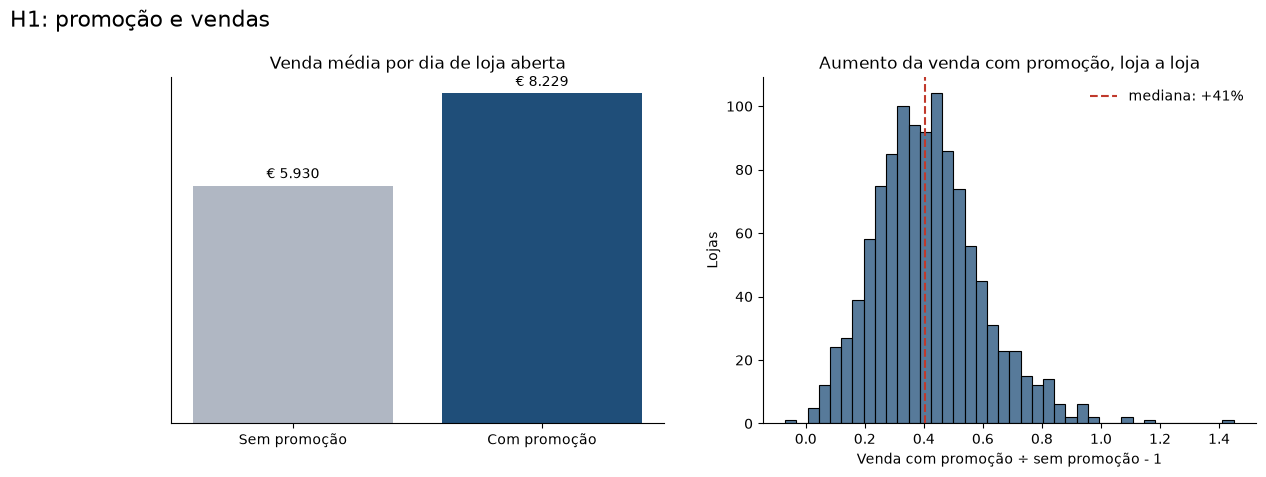

Venda média: sem promoção € 5.930 | com promoção € 8.229 (+38.8%)
Clientes médios: sem promoção 697 | com promoção 844 (+21.2%)
Lojas que vendem mais com promoção: 99.9%


{'teste': 'Wilcoxon pareado',
 'estatística': np.float64(6.0),
 'p-valor': np.float64(5.975845241511299e-184),
 'efeito': 'mediana da diferença',
 'tamanho do efeito': 2192.7837962037966}

In [20]:
venda_promo = df.groupby('promo')[ALVO].mean()
# Comparação justa: a MESMA loja, com e sem promoção
por_loja_promo = df.groupby(['loja', 'promo'])[ALVO].mean().unstack()
aumento_por_loja = por_loja_promo[1] / por_loja_promo[0] - 1
teste_h1 = teste_wilcoxon(por_loja_promo[0], por_loja_promo[1])
clientes_promo = df.groupby('promo')['clientes'].mean()

fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
axs[0].bar(['Sem promoção', 'Com promoção'], venda_promo.values, color=[COR_NEUTRA, COR_PRINCIPAL])
axs[0].bar_label(axs[0].containers[0], labels=[euros(v) for v in venda_promo.values], padding=3)
axs[0].set(title='Venda média por dia de loja aberta', yticks=[])
sns.histplot(aumento_por_loja, bins=40, color=COR_PRINCIPAL, ax=axs[1])
axs[1].axvline(aumento_por_loja.median(), color=COR_DESTAQUE, ls='--', label=f'mediana: {aumento_por_loja.median():+.0%}')
axs[1].set(title='Aumento da venda com promoção, loja a loja', xlabel='Venda com promoção ÷ sem promoção - 1', ylabel='Lojas')
axs[1].legend(frameon=False)
sns.despine()
titulo('H1: promoção e vendas')
salvar('H1 Promocao')
plt.show()
print(f'Venda média: sem promoção {euros(venda_promo[0])} | com promoção {euros(venda_promo[1])} ({venda_promo[1] / venda_promo[0] - 1:+.1%})')
print(f'Clientes médios: sem promoção {clientes_promo[0]:.0f} | com promoção {clientes_promo[1]:.0f} ({clientes_promo[1] / clientes_promo[0] - 1:+.1%})')
print(f'Lojas que vendem mais com promoção: {(aumento_por_loja > 0).mean():.1%}')
teste_h1

✅ **Verdadeira, e o efeito é forte:** com promoção, a venda média sobe de **€ 5.930** para **€ 8.229** (**+38,8%**). Os clientes sobem **+21,2%**: a promoção atrai mais gente **e** aumenta o gasto de cada um.
- Comparando **a mesma loja** com e sem promoção, **99,9%** das lojas vendem mais com promoção.

🧪 **Teste estatístico:** Wilcoxon pareado (cada loja comparada com ela mesma), p ≈ 0. A mediana da diferença é de **€ 2.193 por dia**. O que importa é o tamanho do efeito, não o p: aqui ele é grande.

⚠️ A versão original concluiu **+12%**, porque comparava **somas** e há mais dias sem promoção do que com. ✅ Na v2, com médias, o efeito é **três vezes maior**.

#### H2: Lojas com sortimento maior vendem mais

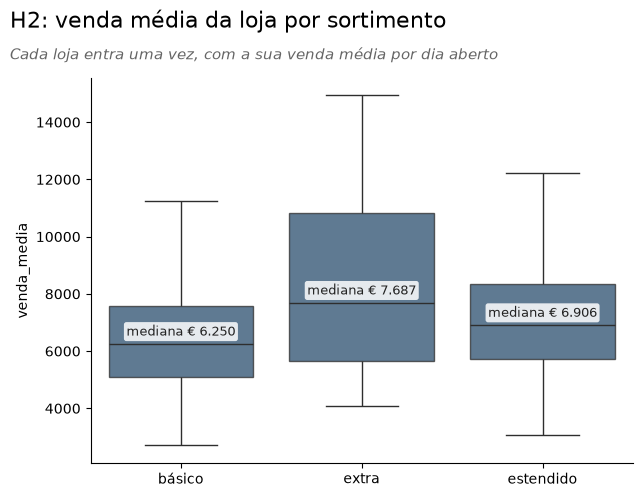

,lojas,venda_media,clientes_medios,soma das vendas (como na v1)
sortimento,,,,
básico,593,€ 6.597,741,€ 2.945.750.070
extra,9,€ 8.558,2046,€ 70.946.312
estendido,513,€ 7.296,748,€ 2.856.484.241


{'teste': 'Kruskal-Wallis',
 'estatística': np.float64(31.395228032689374),
 'p-valor': np.float64(1.5226947615389414e-07),
 'efeito': 'épsilon²',
 'tamanho do efeito': np.float64(0.02818243090905689)}

In [21]:
ordem_sortimento = ['básico', 'extra', 'estendido']
plot_boxplot_grupos(por_loja.reset_index(), 'sortimento', 'venda_media', 'H2: venda média da loja por sortimento',
                    'H2 Sortimento', subtitulo='Cada loja entra uma vez, com a sua venda média por dia aberto', ordem=ordem_sortimento)
resumo_h2 = por_loja.groupby('sortimento').agg(lojas=('venda_media', 'size'), venda_media=('venda_media', 'mean'),
                                               clientes_medios=('clientes_medios', 'mean')).loc[ordem_sortimento]
resumo_h2['soma das vendas (como na v1)'] = df.groupby('sortimento', observed=True)[ALVO].sum()
display(resumo_h2.style.format({'venda_media': euros, 'clientes_medios': '{:.0f}', 'soma das vendas (como na v1)': euros}))
teste_h2 = teste_kruskal(por_loja['venda_media'], por_loja['sortimento'])
teste_h2

⚠️ **Verdadeira em parte, com efeito pequeno:** a venda média por loja é **€ 6.597** no sortimento básico, **€ 7.296** no estendido e **€ 8.558** no extra. O extra vende mais, mas são só **9 lojas**, todas do tipo b, e elas têm **2.046 clientes** por dia, quase o triplo das outras.

🧪 **Teste estatístico:** Kruskal-Wallis com a venda média de cada loja, p < 0,001, **épsilon² = 0,028** (efeito pequeno: o sortimento explica menos de 3% das diferenças entre as lojas). O que importa é o tamanho do efeito, não o p.

⚠️ A versão original concluiu que o sortimento maior **vende menos**, porque a **soma** do extra (€ 71 milhões) é pequena perto das outras (€ 2,9 bilhões cada). ✅ Na v2, a conclusão se inverte: o extra é o que **mais** vende por loja, e a soma era pequena só porque há poucas lojas.

#### H3: Lojas com concorrente mais perto vendem menos

In [22]:
com_concorrente = por_loja[~por_loja['sem_concorrente']]
faixas_distancia = pd.cut(com_concorrente['distancia_concorrente'], [0, 500, 1000, 3000, 10000, 80000],
                          labels=['até 500 m', '0,5 a 1 km', '1 a 3 km', '3 a 10 km', 'mais de 10 km'])
resumo_h3 = com_concorrente.groupby(faixas_distancia, observed=True).agg(
    lojas=('venda_media', 'size'), venda_media=('venda_media', 'mean'), clientes_medios=('clientes_medios', 'mean'))
display(resumo_h3.style.format({'venda_media': euros, 'clientes_medios': '{:.0f}'}))
teste_h3 = teste_spearman(com_concorrente['distancia_concorrente'], com_concorrente['venda_media'])
teste_h3_tipo = pd.DataFrame({tipo: teste_spearman(grupo['distancia_concorrente'], grupo['venda_media'])
                              for tipo, grupo in com_concorrente.groupby('tipo_loja')}).T
print('Mesma correlação dentro de cada tipo de loja:')
display(teste_h3_tipo[['estatística', 'p-valor']])
teste_h3

,lojas,venda_media,clientes_medios
distancia_concorrente,,,
até 500 m,220,€ 7.583,960
"0,5 a 1 km",110,€ 6.643,816
1 a 3 km,296,€ 6.856,739
3 a 10 km,299,€ 6.723,659
mais de 10 km,187,€ 6.832,657


Mesma correlação dentro de cada tipo de loja:


,estatística,p-valor
a,-0.086,0.035
b,-0.319,0.213
c,-0.006,0.947
d,0.061,0.259


{'teste': 'Spearman',
 'estatística': np.float64(-0.028126736716942845),
 'p-valor': np.float64(0.34872597255574955),
 'efeito': 'rho',
 'tamanho do efeito': np.float64(-0.028126736716942845)}

❌ **Falsa:** a distância do concorrente quase não tem relação com a venda. As lojas com concorrente **a até 500 m** são as que **mais** vendem (**€ 7.583**), provavelmente porque ficam em centros movimentados, onde há várias farmácias.
- Dentro de cada tipo de loja, a correlação também fica perto de zero (a maior em módulo é **−0,32** no tipo b, com só 17 lojas e p = 0,21).

🧪 **Teste estatístico:** Spearman entre a distância e a venda média da loja, **rho = −0,03**, p = 0,35. Não há relação, e o efeito é desprezível.

✅ A versão original também rejeitou a hipótese ("concorrente perto vende mais"). Na v2, a conclusão é mais precisa: **a distância, sozinha, não muda a venda**. O que muda é a **chegada** de um concorrente novo (H11).

#### H4: O tipo de loja muda a venda

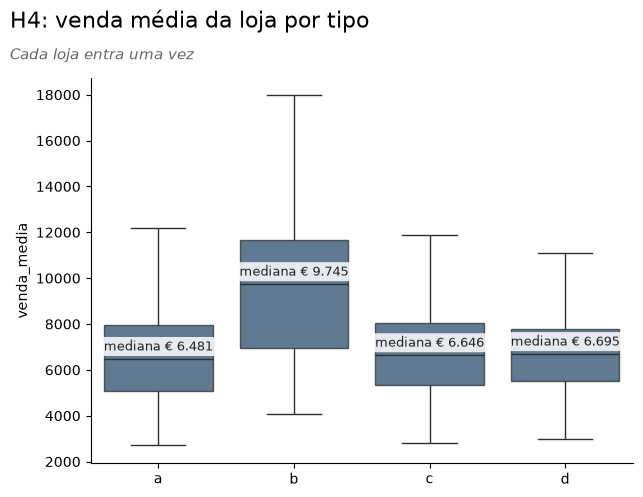

,lojas,venda_media,clientes_medios,venda por cliente,soma das vendas (como na v1)
tipo_loja,,,,,
a,602,€ 6.913,792,"€ 8,96",€ 3.165.334.859
b,17,€ 10.112,1999,"€ 5,17",€ 159.231.395
c,148,€ 6.918,812,"€ 8,74",€ 783.221.426
d,348,€ 6.824,604,"€ 11,43",€ 1.765.392.943


{'teste': 'Kruskal-Wallis',
 'estatística': np.float64(12.270025907379022),
 'p-valor': np.float64(0.006513150489316562),
 'efeito': 'épsilon²',
 'tamanho do efeito': np.float64(0.011014385913266627)}

In [23]:
plot_boxplot_grupos(por_loja.reset_index(), 'tipo_loja', 'venda_media', 'H4: venda média da loja por tipo', 'H4 Tipo de loja',
                    subtitulo='Cada loja entra uma vez', ordem=['a', 'b', 'c', 'd'])
resumo_h4 = por_loja.groupby('tipo_loja').agg(lojas=('venda_media', 'size'), venda_media=('venda_media', 'mean'),
                                              clientes_medios=('clientes_medios', 'mean'))
resumo_h4['venda por cliente'] = por_loja.groupby('tipo_loja').apply(lambda g: (g['venda_media'] / g['clientes_medios']).mean())
resumo_h4['soma das vendas (como na v1)'] = df.groupby('tipo_loja', observed=True)[ALVO].sum()
display(resumo_h4.style.format({'venda_media': euros, 'clientes_medios': '{:.0f}', 'venda por cliente': lambda v: euros(v, 2),
                                'soma das vendas (como na v1)': euros}))
teste_h4 = teste_kruskal(por_loja['venda_media'], por_loja['tipo_loja'])
teste_h4

⚠️ **Verdadeira só para o tipo b:** as lojas **tipo b** vendem **€ 10.112** por dia, contra cerca de **€ 6.800 a € 6.900** nos tipos a, c e d. Elas têm **1.999 clientes** por dia, mas cada cliente gasta só **€ 5,17** (contra **€ 11,43** no tipo d). O tipo b parece ser uma loja de **alto movimento e compra pequena**, como em estações e centros comerciais.

🧪 **Teste estatístico:** Kruskal-Wallis, p = 0,007, **épsilon² = 0,011** (efeito pequeno: são só 17 lojas tipo b). O que importa é o tamanho do efeito, não o p.

⚠️ A versão original concluiu que o **tipo a** vende mais porque tem a maior **soma** (€ 3,2 bilhões). Mas o tipo a tem **602 lojas**. ✅ Por loja, o tipo a vende o mesmo que c e d.

#### H5: As lojas vendem mais a cada ano

In [24]:
# A soma por ano (como na v1) mistura o crescimento com o número de dias e de lojas de cada ano
por_ano = df.groupby('ano').agg(soma=(ALVO, 'sum'), dias_de_loja=(ALVO, 'size'), venda_media=(ALVO, 'mean'))
por_ano['lojas'] = df.groupby('ano')['loja'].nunique()
por_ano['meses na base'] = df.groupby('ano')['mes'].nunique()
display(por_ano.style.format({'soma': euros, 'venda_media': euros, 'dias_de_loja': '{:,.0f}'}))

# Comparação justa: as mesmas lojas (sem a lacuna) e os mesmos meses (jan a jun), loja a loja
completas = df[~df['loja'].isin(lojas_lacuna) & (df['mes'] <= 6)]
media_loja_ano = completas.groupby(['loja', 'ano'])[ALVO].mean().unstack()
crescimento = media_loja_ano.pct_change(axis=1).median()
teste_h5_14 = teste_wilcoxon(media_loja_ano[2013], media_loja_ano[2014])
teste_h5_15 = teste_wilcoxon(media_loja_ano[2014], media_loja_ano[2015])
print(f'Lojas comparadas: {len(media_loja_ano)} | crescimento mediano por loja (jan-jun): '
      f'2014 vs 2013 {crescimento[2014]:+.1%} | 2015 vs 2014 {crescimento[2015]:+.1%}')
pd.DataFrame({'2014 vs 2013': teste_h5_14, '2015 vs 2014': teste_h5_15}).T

,soma,dias_de_loja,venda_media,lojas,meses na base
ano,,,,,
2013,€ 2.302.876.084,"337,924",€ 6.815,1115,12
2014,€ 2.180.804.896,"310,385",€ 7.026,1115,12
2015,€ 1.389.499.643,"196,029",€ 7.088,1115,7


Lojas comparadas: 935 | crescimento mediano por loja (jan-jun): 2014 vs 2013 +3.2% | 2015 vs 2014 +3.5%


,teste,estatística,p-valor,efeito,tamanho do efeito
2014 vs 2013,Wilcoxon pareado,"98,597.000",0.000,mediana da diferença,193.510
2015 vs 2014,Wilcoxon pareado,"75,936.000",0.000,mediana da diferença,219.476


✅ **Verdadeira:** a venda média por dia sobe todo ano: **€ 6.815** (2013), **€ 7.026** (2014) e **€ 7.088** (2015).
- Comparando **as mesmas 935 lojas** (sem a lacuna) nos **mesmos meses** (janeiro a junho), a venda mediana de cada loja cresce **+3,2%** de 2013 para 2014 e **+3,5%** de 2014 para 2015.

🧪 **Teste estatístico:** Wilcoxon pareado (cada loja com ela mesma), p ≈ 0 nas duas comparações. A mediana da diferença é de **€ 194** e **€ 219** por dia: um crescimento pequeno, mas consistente.

⚠️ A versão original concluiu que as vendas **caem**, porque a **soma** de 2015 (€ 1,4 bilhão) só tem 7 meses e a de 2014 perdeu o 2º semestre de 180 lojas. ✅ Na v2, com médias, a conclusão se inverte.

#### H6: As lojas vendem mais no fim do ano

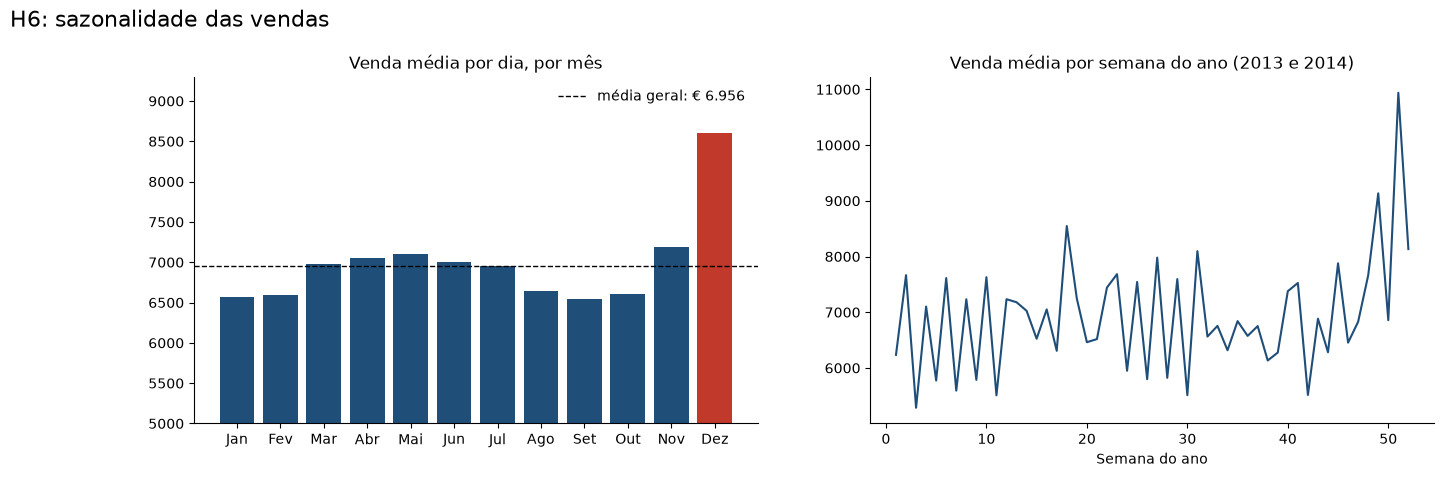

Dezembro: € 8.609 (+24% sobre a média) | 1º semestre € 6.879 | 2º semestre € 7.066


{'teste': 'Kruskal-Wallis',
 'estatística': np.float64(15719.646256474292),
 'p-valor': np.float64(0.0),
 'efeito': 'épsilon²',
 'tamanho do efeito': np.float64(0.018617739429249568)}

In [25]:
nomes_meses = ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']
venda_mes = df.groupby('mes')[ALVO].mean()
venda_semana_ano = df[df['ano'] < 2015].groupby('semana_ano')[ALVO].mean()
fig, axs = plt.subplots(1, 2, figsize=(16, 4.5))
axs[0].bar(nomes_meses, venda_mes.values, color=[COR_DESTAQUE if m == 12 else COR_PRINCIPAL for m in venda_mes.index])
axs[0].axhline(df[ALVO].mean(), color='black', ls='--', lw=1, label=f'média geral: {euros(df[ALVO].mean())}')
axs[0].set(title='Venda média por dia, por mês', ylim=(5000, venda_mes.max() * 1.08))
axs[0].legend(frameon=False)
axs[1].plot(venda_semana_ano.index, venda_semana_ano.values, color=COR_PRINCIPAL)
axs[1].set(title='Venda média por semana do ano (2013 e 2014)', xlabel='Semana do ano')
sns.despine()
titulo('H6: sazonalidade das vendas')
salvar('H6 Sazonalidade')
plt.show()
print(f'Dezembro: {euros(venda_mes[12])} ({venda_mes[12] / df[ALVO].mean() - 1:+.0%} sobre a média) | '
      f'1º semestre {euros(df.loc[df["mes"] <= 6, ALVO].mean())} | 2º semestre {euros(df.loc[df["mes"] > 6, ALVO].mean())}')
teste_h6 = teste_kruskal(df[ALVO], df['mes'])
teste_h6

✅ **Verdadeira:** **dezembro** é o melhor mês, com **€ 8.609** por dia (**+24%** sobre a média). O 2º semestre também vende um pouco mais que o 1º (**€ 7.066** contra **€ 6.879**).

🧪 **Teste estatístico:** Kruskal-Wallis entre os meses, p ≈ 0, **épsilon² = 0,019** (efeito pequeno no conjunto do ano: a diferença se concentra nas semanas antes do Natal, como mostra o gráfico da direita).

⚠️ A versão original concluiu que as lojas vendem **menos** no 2º semestre, porque a **soma** de julho a dezembro não tem 2015. ✅ Na v2, com médias, a conclusão se inverte.

#### H7: As lojas vendem mais depois do dia 10 do mês

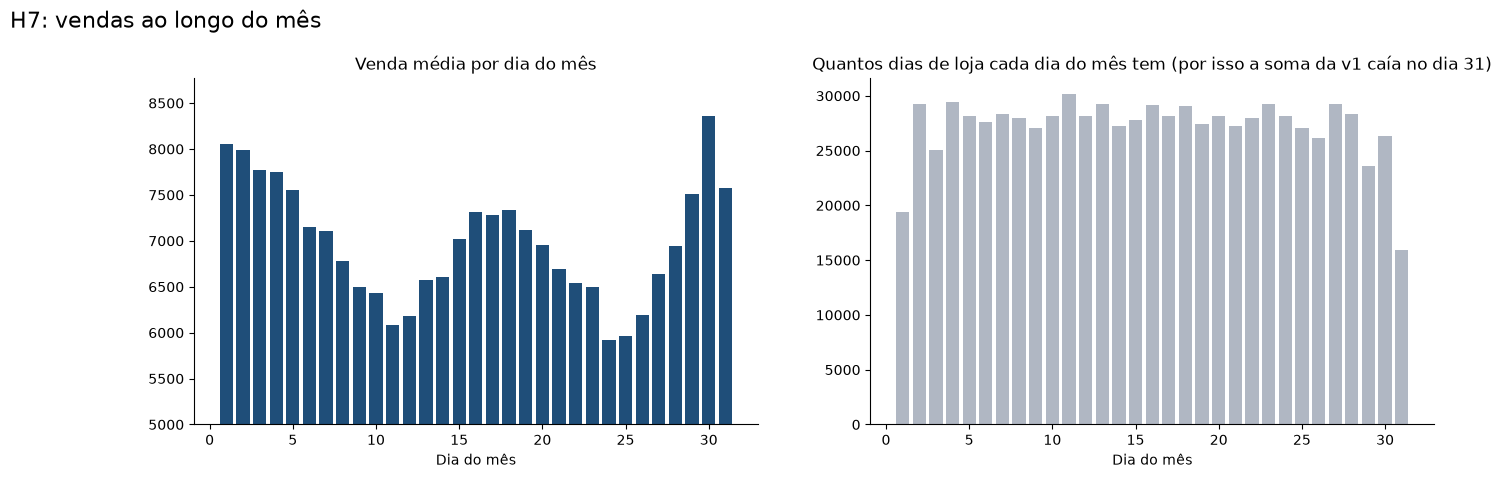

Até o dia 10: € 7.287 | depois do dia 10: € 6.800


{'teste': 'Mann-Whitney',
 'estatística': np.float64(68968300861.5),
 'p-valor': np.float64(0.0),
 'efeito': 'correlação de postos',
 'tamanho do efeito': np.float64(-0.11119741966717844)}

In [26]:
venda_dia = df.groupby('dia')[ALVO].mean()
dias_registrados = df.groupby('dia').size()
fig, axs = plt.subplots(1, 2, figsize=(16, 4.5))
axs[0].bar(venda_dia.index, venda_dia.values, color=COR_PRINCIPAL)
axs[0].set(title='Venda média por dia do mês', xlabel='Dia do mês', ylim=(5000, venda_dia.max() * 1.05))
axs[1].bar(dias_registrados.index, dias_registrados.values, color=COR_NEUTRA)
axs[1].set(title='Quantos dias de loja cada dia do mês tem (por isso a soma da v1 caía no dia 31)', xlabel='Dia do mês')
sns.despine()
titulo('H7: vendas ao longo do mês')
salvar('H7 Dia do mes')
plt.show()
teste_h7 = teste_mann_whitney(df.loc[df['dia'] > 10, ALVO], df.loc[df['dia'] <= 10, ALVO])
print(f"Até o dia 10: {euros(df.loc[df['dia'] <= 10, ALVO].mean())} | depois do dia 10: {euros(df.loc[df['dia'] > 10, ALVO].mean())}")
teste_h7

❌ **Falsa:** as lojas vendem **mais no começo** do mês: **€ 7.287** até o dia 10, contra **€ 6.800** depois. O gráfico mostra três picos, no começo (dias 1 e 2), no meio (dias 15 a 18) e no fim do mês (dia 30), e vales nos dias 11 e 24: o padrão parece acompanhar as datas de pagamento.

🧪 **Teste estatístico:** Mann-Whitney, p ≈ 0, **correlação de postos = −0,11** (efeito pequeno, a favor dos 10 primeiros dias). O que importa é o tamanho do efeito, não o p.

⚠️ A versão original concluiu "verdadeira", porque a **soma** depois do dia 10 junta **21 dias** contra 10. ✅ Na v2, comparando a média por dia, a conclusão se inverte.

#### H8: As lojas vendem menos no fim de semana

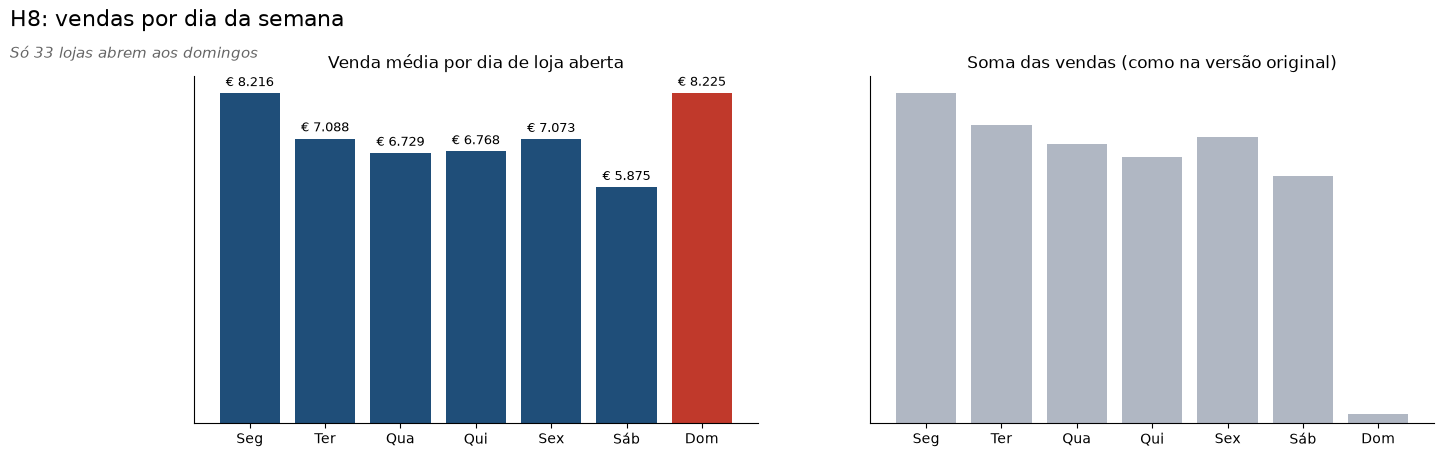

,venda_media,lojas_abertas,soma
Seg,€ 8.216,1115,€ 1.130.203.012
Ter,€ 7.088,1115,€ 1.020.411.930
Qua,€ 6.729,1115,€ 954.962.863
Qui,€ 6.768,1115,€ 911.177.709
Sex,€ 7.073,1115,€ 980.555.941
Sáb,€ 5.875,1115,€ 846.317.735
Dom,€ 8.225,33,€ 29.551.433


Nas 33 lojas que abrem aos domingos: domingo € 8.225 | segunda a sexta € 8.760
Sábado x segunda a sexta (todas as lojas): € 5.875 x € 7.173


,teste,estatística,p-valor,efeito,tamanho do efeito
domingo (lojas que abrem),Mann-Whitney,"33,146,564.000",0.000,correlação de postos,-0.150
sábado (todas),Mann-Whitney,"36,449,959,019.000",0.000,correlação de postos,-0.274


In [27]:
nomes_dias = ['Seg', 'Ter', 'Qua', 'Qui', 'Sex', 'Sáb', 'Dom']
resumo_h8 = df.groupby('dia_semana').agg(venda_media=(ALVO, 'mean'), lojas_abertas=('loja', 'nunique'), soma=(ALVO, 'sum'))
resumo_h8.index = nomes_dias
fig, axs = plt.subplots(1, 2, figsize=(16, 4.5))
axs[0].bar(nomes_dias, resumo_h8['venda_media'], color=[COR_DESTAQUE if d == 'Dom' else COR_PRINCIPAL for d in nomes_dias])
axs[0].bar_label(axs[0].containers[0], labels=[euros(v) for v in resumo_h8['venda_media']], padding=3, fontsize=9)
axs[0].set(title='Venda média por dia de loja aberta', yticks=[])
axs[1].bar(nomes_dias, resumo_h8['soma'], color=COR_NEUTRA)
axs[1].set(title='Soma das vendas (como na versão original)', yticks=[])
sns.despine()
titulo('H8: vendas por dia da semana', f"Só {resumo_h8.loc['Dom', 'lojas_abertas']} lojas abrem aos domingos")
salvar('H8 Dia da semana')
plt.show()
display(resumo_h8.style.format({'venda_media': euros, 'soma': euros}))
# Comparação justa: só as lojas que abrem aos domingos, domingo x outros dias
abrem_domingo = df.loc[df['dia_semana'] == 7, 'loja'].unique()
so_domingueiras = df[df['loja'].isin(abrem_domingo)]
teste_h8 = teste_mann_whitney(so_domingueiras.loc[so_domingueiras['dia_semana'] == 7, ALVO],
                              so_domingueiras.loc[so_domingueiras['dia_semana'] < 6, ALVO])
print(f"Nas {len(abrem_domingo)} lojas que abrem aos domingos: domingo {euros(so_domingueiras.loc[so_domingueiras['dia_semana'] == 7, ALVO].mean())} "
      f"| segunda a sexta {euros(so_domingueiras.loc[so_domingueiras['dia_semana'] < 6, ALVO].mean())}")
print(f"Sábado x segunda a sexta (todas as lojas): {euros(df.loc[df['dia_semana'] == 6, ALVO].mean())} x {euros(df.loc[df['dia_semana'] < 6, ALVO].mean())}")
teste_h8_sabado = teste_mann_whitney(df.loc[df['dia_semana'] == 6, ALVO], df.loc[df['dia_semana'] < 6, ALVO])
pd.DataFrame({'domingo (lojas que abrem)': teste_h8, 'sábado (todas)': teste_h8_sabado}).T

✅ **Verdadeira, mas por um motivo diferente do da versão original:**
- 🔎 **Sábado** é o dia mais fraco: **€ 5.875**, contra **€ 7.173** de segunda a sexta.
- 🔎 **Domingo** tem a **maior** média da semana (**€ 8.225**), mas só **33 lojas** abrem aos domingos, e elas são grandes. **Nessas mesmas lojas**, o domingo vende **menos** que os dias úteis (**€ 8.225** contra **€ 8.760**).
- 🔎 **Segunda** é o melhor dia útil (**€ 8.216**): ela recebe a demanda do domingo, quando quase todas as lojas fecham.

🧪 **Teste estatístico:** Mann-Whitney. Sábado × dias úteis: **correlação de postos = −0,27** (efeito pequeno a moderado). Domingo × dias úteis, só nas 33 lojas que abrem: **−0,15** (pequeno). O que importa é o tamanho do efeito, não o p.

⚠️ A versão original chegou à mesma conclusão olhando a **soma**, que no domingo é pequena só porque quase nenhuma loja abre. ✅ Na v2, a comparação justa (mesmas lojas) confirma o efeito, só que bem menor.

#### H9: As lojas vendem menos nos feriados escolares

In [28]:
# Mesma loja e mesmo dia da semana, com e sem feriado escolar (o feriado escolar se concentra em julho e agosto)
uteis = df[df['dia_semana'] < 6]
venda_escolar = uteis.groupby('feriado_escolar')[ALVO].mean()
por_loja_escolar = uteis.groupby(['loja', 'feriado_escolar'])[ALVO].mean().unstack().dropna()
teste_h9 = teste_wilcoxon(por_loja_escolar[0], por_loja_escolar[1])
print(f'Segunda a sexta: sem feriado escolar {euros(venda_escolar[0])} | com feriado escolar {euros(venda_escolar[1])} '
      f'({venda_escolar[1] / venda_escolar[0] - 1:+.1%})')
print(f'Lojas que vendem mais no feriado escolar: {(por_loja_escolar[1] > por_loja_escolar[0]).mean():.1%}')
print('% de dias com feriado escolar, por mês:')
print((df.groupby('mes')['feriado_escolar'].mean() * 100).round(0).set_axis(nomes_meses).to_dict())
teste_h9

Segunda a sexta: sem feriado escolar € 7.159 | com feriado escolar € 7.220 (+0.8%)
Lojas que vendem mais no feriado escolar: 53.1%
% de dias com feriado escolar, por mês:
{'Jan': 12.0, 'Fev': 9.0, 'Mar': 9.0, 'Abr': 24.0, 'Mai': 8.0, 'Jun': 7.0, 'Jul': 44.0, 'Ago': 63.0, 'Set': 8.0, 'Out': 33.0, 'Nov': 0.0, 'Dez': 23.0}


{'teste': 'Wilcoxon pareado',
 'estatística': np.float64(280294.0),
 'p-valor': np.float64(0.004197487941929511),
 'efeito': 'mediana da diferença',
 'tamanho do efeito': 21.62566542077184}

❌ **Falsa:** comparando a **mesma loja** de segunda a sexta, a venda com feriado escolar é praticamente igual (**€ 7.220** contra **€ 7.159**, **+0,8%**). Só **53,1%** das lojas vendem mais no feriado escolar, quase metade.
- O feriado escolar se concentra em **julho (44% dos dias)** e **agosto (63%)**, e por isso a comparação precisa ser feita dentro da mesma loja.

🧪 **Teste estatístico:** Wilcoxon pareado, p = 0,004, mas a mediana da diferença é de só **€ 22 por dia**. É um caso clássico: "significativo" e **desprezível**. O que importa é o tamanho do efeito, não o p.

⚠️ A versão original concluiu que as lojas vendem **menos** nos feriados escolares, olhando a **soma** (há muito menos dias com feriado escolar). ✅ Na v2, o efeito é nulo na prática.

### 3.3. Análises combinadas

#### H10: Lojas na Promo2 (promoção contínua) vendem mais

In [29]:
resumo_h10 = por_loja.groupby('promo2').agg(lojas=('venda_media', 'size'), venda_media=('venda_media', 'mean'),
                                            clientes_medios=('clientes_medios', 'mean'))
resumo_h10.index = ['Não participa', 'Participa']
display(resumo_h10.style.format({'venda_media': euros, 'clientes_medios': '{:.0f}'}))
teste_h10 = teste_mann_whitney(por_loja.loc[por_loja['promo2'] == 1, 'venda_media'], por_loja.loc[por_loja['promo2'] == 0, 'venda_media'])
# Dentro das lojas que participam: o mês de reinício da Promo2 vende mais que os outros?
participantes = df[df['semanas_promo2'] > 0]
por_loja_mes_ativo = participantes.groupby(['loja', 'promo2_mes_ativo'])[ALVO].mean().unstack().dropna()
teste_h10_mes = teste_wilcoxon(por_loja_mes_ativo[0], por_loja_mes_ativo[1])
print(f'Nas lojas que participam: mês de reinício {euros(por_loja_mes_ativo[1].mean())} | outros meses {euros(por_loja_mes_ativo[0].mean())}')
pd.DataFrame({'participa x não participa (lojas)': teste_h10, 'mês de reinício x outros (mesma loja)': teste_h10_mes}).T

,lojas,venda_media,clientes_medios
Não participa,544,€ 7.338,837
Participa,571,€ 6.551,676


Nas lojas que participam: mês de reinício € 6.522 | outros meses € 6.645


,teste,estatística,p-valor,efeito,tamanho do efeito
participa x não participa (lojas),Mann-Whitney,"129,047.000",0.000,correlação de postos,-0.169
mês de reinício x outros (mesma loja),Wilcoxon pareado,"37,877.000",0.000,mediana da diferença,-150.163


❌ **Falsa:** as lojas **na Promo2** vendem **menos** (**€ 6.551** contra **€ 7.338**) e têm menos clientes (**676** contra **837**).
- Dentro das lojas que participam, o **mês de reinício** da promoção também não vende mais: **€ 6.522** contra **€ 6.645** nos outros meses.

🧪 **Teste estatístico:** Mann-Whitney entre as lojas, **correlação de postos = −0,17** (efeito pequeno). Wilcoxon pareado no mês de reinício, mediana da diferença de **−€ 150**. O que importa é o tamanho do efeito, não o p.

💡 Isso **não prova** que a Promo2 atrapalha: é provável que a rede tenha colocado na Promo2 justamente as lojas que vendiam menos. Uma comparação de causa exigiria saber a venda **antes e depois** da adesão.

✅ A versão original também rejeitou a hipótese.

#### H11: A abertura de um concorrente reduz as vendas da loja

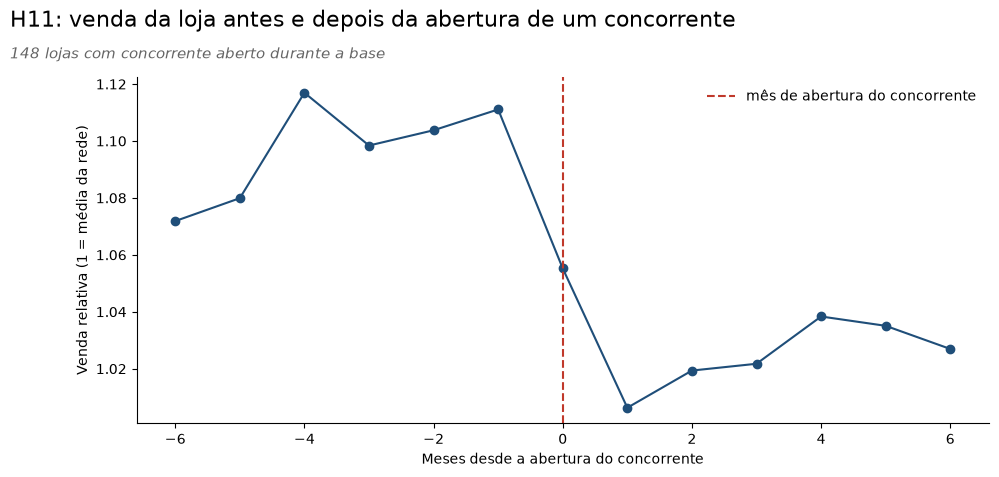

Lojas analisadas: 148 | variação mediana da venda relativa: -5.9% | lojas que perderam venda: 83%


{'teste': 'Wilcoxon pareado',
 'estatística': np.float64(1312.0),
 'p-valor': np.float64(8.849060242218702e-16),
 'efeito': 'mediana da diferença',
 'tamanho do efeito': -0.05812960250237387}

In [30]:
# Lojas cujo concorrente abriu DURANTE a base: venda relativa (loja ÷ média da rede no mesmo dia),
# 3 meses antes x 3 meses depois do mês de abertura. A divisão pela média da rede tira o efeito da época do ano.
df_rel = df[['loja', 'data', 'ano', 'mes', ALVO]].copy()
df_rel['venda_relativa'] = df_rel[ALVO] / df_rel.groupby('data')[ALVO].transform('mean')
df_rel['mes_indice'] = df_rel['ano'] * 12 + df_rel['mes']
abertura = lojas.set_index('loja').eval('concorrente_desde_ano * 12 + concorrente_desde_mes')
abriu_na_base = abertura[(abertura >= 2013 * 12 + 4) & (abertura <= 2015 * 12 + 4)]
df_rel = df_rel[df_rel['loja'].isin(abriu_na_base.index)]
df_rel['meses_desde_abertura'] = df_rel['mes_indice'] - df_rel['loja'].map(abriu_na_base)
antes = df_rel[df_rel['meses_desde_abertura'].between(-3, -1)].groupby('loja')['venda_relativa'].mean()
depois = df_rel[df_rel['meses_desde_abertura'].between(1, 3)].groupby('loja')['venda_relativa'].mean()
pares = pd.concat([antes.rename('antes'), depois.rename('depois')], axis=1).dropna()
variacao = pares['depois'] / pares['antes'] - 1
teste_h11 = teste_wilcoxon(pares['antes'], pares['depois'])

trajetoria = df_rel[df_rel['meses_desde_abertura'].between(-6, 6)].groupby('meses_desde_abertura')['venda_relativa'].mean()
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(trajetoria.index, trajetoria.values, marker='o', color=COR_PRINCIPAL)
ax.axvline(0, color=COR_DESTAQUE, ls='--', label='mês de abertura do concorrente')
ax.set(xlabel='Meses desde a abertura do concorrente', ylabel='Venda relativa (1 = média da rede)')
ax.legend(frameon=False)
sns.despine()
titulo('H11: venda da loja antes e depois da abertura de um concorrente', f'{len(pares)} lojas com concorrente aberto durante a base')
salvar('H11 Abertura de concorrente')
plt.show()
print(f'Lojas analisadas: {len(pares)} | variação mediana da venda relativa: {variacao.median():+.1%} | '
      f'lojas que perderam venda: {(variacao < 0).mean():.0%}')
teste_h11

✅ **Verdadeira:** nas **148 lojas** em que um concorrente abriu durante a base, a venda relativa (venda da loja ÷ média da rede no mesmo dia) cai **5,9%** (mediana) nos 3 meses depois da abertura, comparada aos 3 meses antes. **83%** das lojas perderam venda.

🧪 **Teste estatístico:** Wilcoxon pareado (cada loja antes × depois), p < 0,001. A mediana da diferença é de **−0,058** na venda relativa: um efeito moderado e sustentado (o gráfico mostra que a venda não volta ao nível anterior em 6 meses).

⚠️ A versão original **não testou** esta hipótese. ✅ Na v2, ela explica a H3: a distância parada não diz nada, mas a **chegada** de um concorrente custa cerca de **6% da venda**.

#### H12: Lojas abertas em feriado vendem mais

In [31]:
resumo_h12 = df.groupby('feriado', observed=True).agg(dias_de_loja=(ALVO, 'size'), lojas=('loja', 'nunique'), venda_media=(ALVO, 'mean'))
display(resumo_h12.style.format({'venda_media': euros}))
# Mesma loja: dia de feriado x dias normais
em_feriado = df[df['feriado'] != 'nenhum']
lojas_feriado = em_feriado['loja'].unique()
normais = df[(df['feriado'] == 'nenhum') & df['loja'].isin(lojas_feriado)].groupby('loja')[ALVO].mean()
feriado_loja = em_feriado.groupby('loja')[ALVO].mean()
teste_h12 = teste_wilcoxon(normais.loc[feriado_loja.index], feriado_loja)
print(f'Lojas que abriram em algum feriado: {len(lojas_feriado)} | em feriado {euros(feriado_loja.mean())} x dias normais '
      f'{euros(normais.loc[feriado_loja.index].mean())} (mesmas lojas)')
print(f"Dias de feriado com a loja aberta: {(base.loc[base['feriado'] != 'nenhum', 'aberta'] == 1).mean():.1%}")
teste_h12

,dias_de_loja,lojas,venda_media
feriado,,,
Natal,71,20,€ 9.744
Páscoa,145,32,€ 9.888
nenhum,843428,1115,€ 6.954
público,694,156,€ 8.487


Lojas que abriram em algum feriado: 156 | em feriado € 7.049 x dias normais € 7.207 (mesmas lojas)
Dias de feriado com a loja aberta: 2.9%


{'teste': 'Wilcoxon pareado',
 'estatística': np.float64(5571.0),
 'p-valor': np.float64(0.3287185675254958),
 'efeito': 'mediana da diferença',
 'tamanho do efeito': 529.5714285714284}

❌ **Falsa:** as médias brutas dos feriados são altas (**€ 9.888** na Páscoa, **€ 9.744** no Natal, **€ 8.487** nos feriados públicos), mas só abrem em feriado **156 lojas** grandes, em **2,9%** dos dias de feriado.
- Comparando **essas mesmas lojas**, o feriado vende **€ 7.049**, contra **€ 7.207** nos dias normais.

🧪 **Teste estatístico:** Wilcoxon pareado, **p = 0,33**. A média e a mediana da diferença apontam para lados opostos (mediana de **+€ 530**): não há diferença confiável.

⚠️ A versão original concluiu que as lojas vendem **menos no Natal**, olhando a **soma**: quase nenhuma loja abre no Natal. ✅ Na v2, a média alta dos feriados é efeito de **quais lojas** abrem, não do feriado.

### 3.4. Resumo das Hipóteses

| # | Hipótese | Conclusão da v1 | Conclusão da v2 | Teste | Tamanho do efeito |
|---|---|---|---|---|---|
| H1 | Promoção vende mais | Verdadeira, +12% | ✅ Verdadeira, **+38,8%** | Wilcoxon pareado | **€ 2.193/dia** (grande) |
| H2 | Sortimento maior vende mais | Falsa | ⚠️ Em parte: o **extra** vende mais (9 lojas) | Kruskal-Wallis | ε² = 0,028 (pequeno) |
| H3 | Concorrente perto vende menos | Falsa | ❌ Falsa: sem relação | Spearman | rho = −0,03 (nulo) |
| H4 | O tipo de loja muda a venda | Tipo a vende mais | ⚠️ Só o **tipo b** vende mais | Kruskal-Wallis | ε² = 0,011 (pequeno) |
| H5 | Vende mais a cada ano | Falsa (cai) | ✅ Verdadeira, **+3%** ao ano | Wilcoxon pareado | € 194 e € 219/dia (pequeno) |
| H6 | Vende mais no fim do ano | Falsa | ✅ Verdadeira: dezembro **+24%** | Kruskal-Wallis | ε² = 0,019 (pequeno) |
| H7 | Vende mais depois do dia 10 | Verdadeira | ❌ Falsa: vende mais **antes** | Mann-Whitney | r = −0,11 (pequeno) |
| H8 | Vende menos no fim de semana | Verdadeira | ✅ Verdadeira (sábado; domingo nas mesmas lojas) | Mann-Whitney | r = −0,27 e −0,15 |
| H9 | Vende menos no feriado escolar | Verdadeira | ❌ Falsa: **+0,8%** | Wilcoxon pareado | € 22/dia (desprezível) |
| H10 | Promo2 vende mais | Falsa | ❌ Falsa: vende **menos** | Mann-Whitney | r = −0,17 (pequeno) |
| H11 | Concorrente novo reduz a venda | (não testada) | ✅ Verdadeira, **−5,9%** | Wilcoxon pareado | −0,058 na venda relativa (moderado) |
| H12 | Feriado vende mais | Falsa (Natal vende menos) | ❌ Falsa: sem diferença nas mesmas lojas | Wilcoxon pareado | p = 0,33 |

📌 **Nota**
- 🔎 Das 11 hipóteses que a versão original testou, **6 mudaram de conclusão** (H2, H4, H5, H6, H7 e H9) e **2 mudaram de tamanho** (H1 e H8). Quase sempre o motivo é o mesmo: a **soma** mistura quanto cada loja vende com **quantos dias e lojas** o grupo tem.
- 🔎 Os efeitos que importam para prever são a **promoção** (H1), o **dia da semana** (H8), o **Natal** (H6) e a **chegada de um concorrente** (H11). As características fixas da loja (sortimento, tipo, distância) têm efeito pequeno: o que diferencia as lojas é o **tamanho** de cada uma, que o modelo recebe pelas **médias da loja**.

## 4 - FEATURE ENGINEERING — (engenharia de atributos)

| Variável | Como foi criada | Por quê |
|---|---|---|
| `ano`, `mes`, `dia`, `semana_ano` | a partir da data | Sazonalidade do ano (H6), do mês (H7) e a tendência (H5) |
| `sem_concorrente`, `distancia_concorrente` | distância nula vira 100 km + indicador | Separa "longe" de "não informado" (item 2.4) |
| `meses_concorrente`, `concorrente_data_desconhecida` | meses desde a abertura do concorrente | O efeito de um concorrente novo (H11) |
| `semanas_promo2`, `promo2_mes_ativo` | semanas desde a adesão e mês de reinício | A Promo2 é contínua e reinicia em meses fixos (H10) |
| `media_loja`, `media_loja_dia_semana`, `media_loja_promo` | venda média da loja: no geral, por dia da semana e com/sem promoção | O que mais diferencia as lojas é o **tamanho** de cada uma (H2 a H4). O número da loja não tem ordem; a média dela, sim |
| `feriado`, `tipo_loja`, `sortimento` | one-hot dentro do `Pipeline` | Modelos só trabalham com números |

> ⚠️ **As médias da loja usam as vendas**, então só podem ser calculadas com o **período de treino**. Elas ficam dentro do `Pipeline` (transformador `MediasDaLoja`, `src/modelos.py`), que é reajustado em cada dobra da validação cruzada. Assim, nenhuma venda da validação ou do teste entra nas médias.

> 💡 A versão original transformava o dia, o mês e a semana em **seno e cosseno**. Isso ajuda modelos lineares, mas as árvores (que venceram aqui e na v1) separam os meses diretamente; mantivemos os números simples, que são mais fáceis de explicar.

In [32]:
df[FEATURES + [ALVO]].head()

,loja,feriado,tipo_loja,sortimento,dia_semana,promo,feriado_escolar,distancia_concorrente,sem_concorrente,meses_concorrente,concorrente_data_desconhecida,promo2,semanas_promo2,promo2_mes_ativo,ano,mes,dia,semana_ano,vendas
0,85,público,b,básico,2,0,1,"1,870.000",0,15.000,0,0,0.000,0,2013,1,1,1,4220
1,259,público,b,extra,2,0,1,210.000,0,0.000,1,0,0.000,0,2013,1,1,1,6851
2,262,público,b,básico,2,0,1,"1,180.000",0,-4.000,0,0,0.000,0,2013,1,1,1,17267
3,274,público,b,extra,2,0,1,"3,640.000",0,0.000,1,1,0.000,0,2013,1,1,1,3102
4,335,público,b,básico,2,0,1,90.000,0,0.000,1,1,0.000,0,2013,1,1,1,2401


## 5 - EXPLORANDO AS CORRELAÇÕES

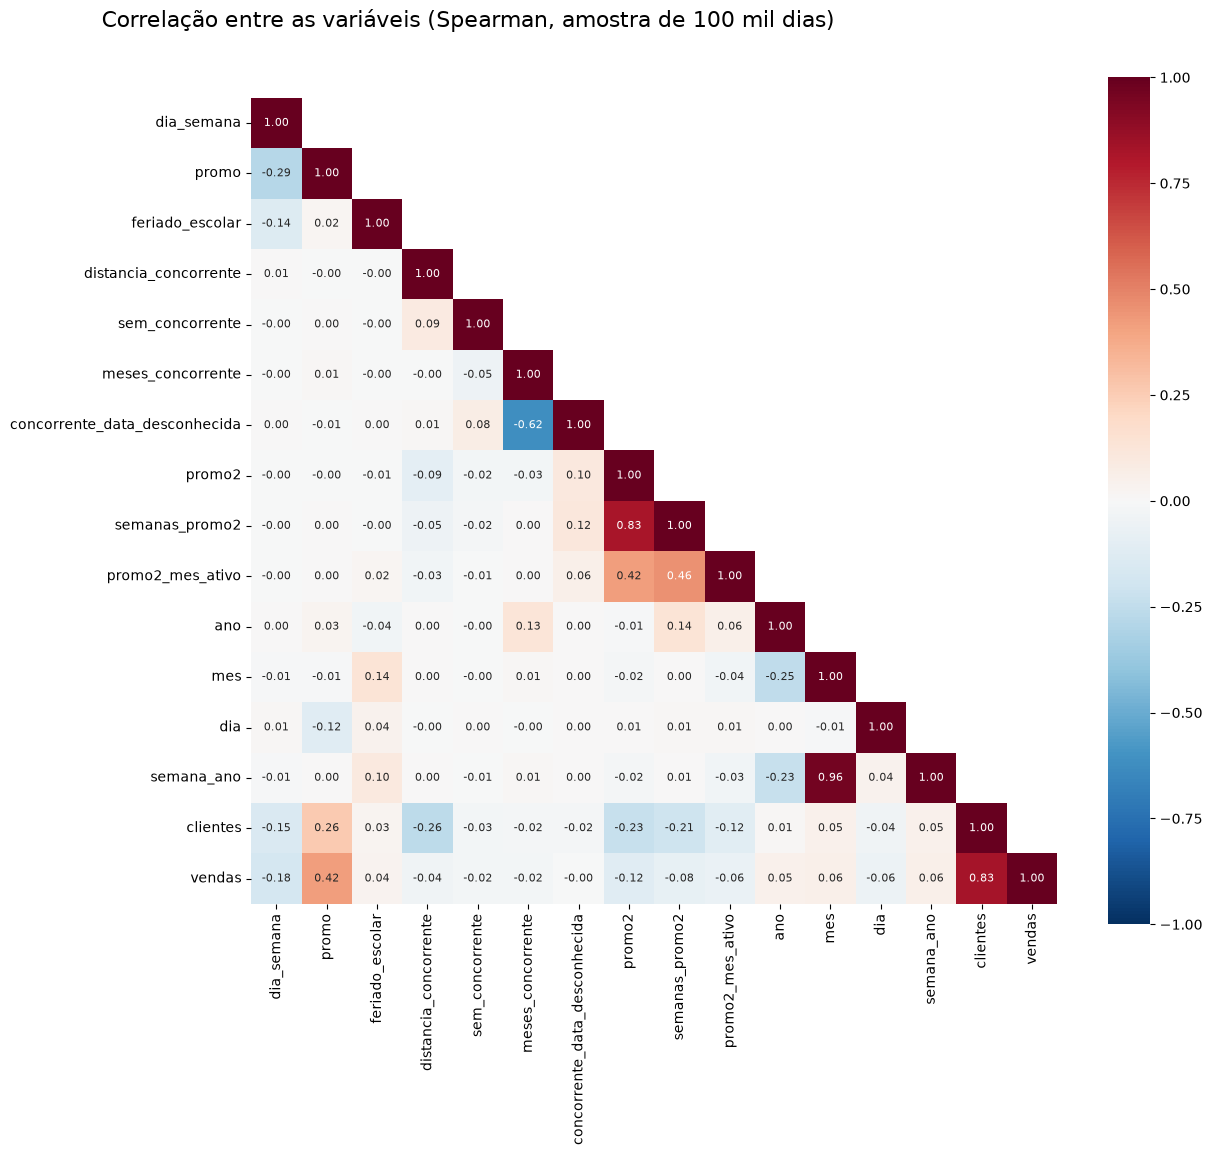

,clientes,promo,semana_ano,mes,ano,feriado_escolar,concorrente_data_desconhecida,meses_concorrente,sem_concorrente,distancia_concorrente,dia,promo2_mes_ativo,semanas_promo2,promo2,dia_semana
correlação com a venda,0.830,0.420,0.060,0.060,0.050,0.040,-0.000,-0.020,-0.020,-0.040,-0.060,-0.060,-0.080,-0.120,-0.180


In [33]:
amostra_corr = df.sample(100_000, random_state=SEMENTE)
colunas_corr = [coluna for coluna in NUMERICAS if amostra_corr[coluna].nunique() > 1] + ['clientes', ALVO]
correlacao = amostra_corr[colunas_corr].corr(method='spearman')
plt.figure(figsize=(13, 11))
sns.heatmap(correlacao, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, square=True, annot_kws={'size': 8},
            mask=np.triu(np.ones_like(correlacao, dtype=bool), k=1))
titulo('Correlação entre as variáveis (Spearman, amostra de 100 mil dias)')
salvar('Correlacao entre variaveis')
plt.show()
correlacao[ALVO].drop(ALVO).sort_values(ascending=False).round(2).to_frame('correlação com a venda').T

📌 **Nota**
- 🔎 A variável mais ligada à venda é **clientes** (**0,83**), que é vazamento e fica fora do modelo.
- 🔎 Entre as variáveis permitidas, a **promoção** se destaca (**0,42**), seguida do **dia da semana** (**−0,18**: a venda cai ao longo da semana) e da **Promo2** (**−0,12**). As outras ficam abaixo de 0,1 em módulo.
- 🔎 Correlações baixas não significam que a variável é inútil: a semana do ano só importa em dezembro, e a loja (a variável mais importante) nem aparece aqui, porque o número da loja não tem ordem.
- ✅ **Decisão:** manter todas as variáveis permitidas e deixar a seleção para o item 4.3, que mede a relevância com o modelo.

# FASE 03: MODELAGEM DOS DADOS

**Pergunta 1:** *quanto cada loja vai vender nas próximas 6 semanas?*

O modelo recebe só o que se sabe **antes** do dia: a loja, o calendário, se a loja estará em promoção, o feriado e o cadastro da loja (tipo, sortimento, concorrência e Promo2).

## 1 - Leitura dos dados

In [34]:
print(f'Dias com venda: {len(df):,} | variáveis de entrada: {len(FEATURES)}'.replace(',', '.'))
print(FEATURES)

Dias com venda: 844.338 | variáveis de entrada: 18
['loja', 'feriado', 'tipo_loja', 'sortimento', 'dia_semana', 'promo', 'feriado_escolar', 'distancia_concorrente', 'sem_concorrente', 'meses_concorrente', 'concorrente_data_desconhecida', 'promo2', 'semanas_promo2', 'promo2_mes_ativo', 'ano', 'mes', 'dia', 'semana_ano']


## 2 - Valores nulos

In [35]:
df[FEATURES].isna().sum().to_frame('nulos').T

,loja,feriado,tipo_loja,sortimento,dia_semana,promo,feriado_escolar,distancia_concorrente,sem_concorrente,meses_concorrente,concorrente_data_desconhecida,promo2,semanas_promo2,promo2_mes_ativo,ano,mes,dia,semana_ano
nulos,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


📌 **Nota**
- 🔎 As **18 variáveis de entrada** têm **0 nulos**: o tratamento com sentido de negócio foi feito na Fase 02 (item 2.4), em `criar_variaveis`.

## 3 - Transformação

| Etapa | Transformação | Motivo |
|---|---|---|
| `MediasDaLoja` | troca o número da loja pelas **vendas médias** dela (geral, por dia da semana e com/sem promoção), calculadas **no treino** | O número da loja não tem ordem; a média tem |
| Categóricas | **One-hot** (uma coluna 0/1 por categoria) | Modelos só trabalham com números |
| Numéricas | **Padronização** (média 0, desvio 1), só nos modelos lineares | A Regressão Linear e o Lasso comparam pesos entre variáveis de escalas diferentes. As árvores não precisam |
| Alvo | **log(1 + venda)** no treino; a previsão volta para euros | A venda tem cauda longa (item 2.7). Em log, um erro de 10% pesa igual numa loja pequena e numa grande. Na validação cruzada do protótipo, o log teve MAPE um pouco menor que o alvo em euros, com o mesmo erro do total por loja |

Tudo fica **dentro de um `Pipeline`**, reajustado só com os dados de treino em cada dobra da validação cruzada. As métricas são sempre calculadas **em euros**.

In [36]:
def montar_modelo(estimador, linear=False):
    # Pipeline completo: médias da loja (aprendidas no treino) + one-hot (+ padronização nos lineares) + modelo,
    # treinado com o log da venda e devolvendo a previsão em euros
    if linear:
        preparo = ColumnTransformer([('categorias', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CATEGORICAS),
                                     ('numericas', StandardScaler(), NUMERICAS + MEDIAS_LOJA)], verbose_feature_names_out=False)
    else:
        preparo = ColumnTransformer([('categorias', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CATEGORICAS)],
                                    remainder='passthrough', verbose_feature_names_out=False)
    pipeline = Pipeline([('medias', MediasDaLoja()), ('preparo', preparo), ('modelo', estimador)])
    return TransformedTargetRegressor(regressor=pipeline, func=np.log1p, inverse_func=np.expm1)

## 4 - Pré-Processamento

### 4.1. Separação do conjunto de dados

Com dados no tempo, a separação **não pode ser aleatória**: se o treino tivesse dias de julho de 2015, o modelo "conheceria o futuro" do teste. A separação segue o calendário, como numa preparação para uma prova:

| Conjunto | Período | Para que serve | Comparação |
|---|---|---|---|
| **Treino** | 01/01/2013 a 07/05/2015 | o modelo **aprende** os padrões | estudar a matéria |
| **Validação** | 08/05 a 18/06/2015 (6 semanas) | **comparar** algoritmos e ajustar configurações | fazer simulados |
| **Teste** | 19/06 a 31/07/2015 (as 6 últimas semanas) | **avaliação final**, usada uma única vez no fim | a prova de verdade |

O teste são **as mesmas semanas** usadas pela versão original, o que permite comparar os resultados. A proporção 60/20/20 do padrão vira "tudo antes / 6 semanas / 6 semanas", porque o que importa aqui é imitar o uso real: prever as **6 semanas seguintes**.

In [37]:
treino, validacao, teste = separar_periodos(df, INICIO_VALIDACAO, INICIO_TESTE)
treino_val = pd.concat([treino, validacao])
X_treino, y_treino = treino[FEATURES], treino[ALVO]
X_validacao, y_validacao = validacao[FEATURES], validacao[ALVO]
X_teste, y_teste = teste[FEATURES], teste[ALVO]
X_treino_val, y_treino_val = treino_val[FEATURES], treino_val[ALVO]

partes = {'Dias com venda': df, 'Treino': treino, 'Validação': validacao, 'Teste': teste}
pd.DataFrame({'Linhas': {nome: len(p) for nome, p in partes.items()},
              'Shape de X': {nome: p[FEATURES].shape for nome, p in partes.items()},
              '% da base': {nome: len(p) / len(df) for nome, p in partes.items()},
              'De': {nome: p['data'].min().date() for nome, p in partes.items()},
              'Até': {nome: p['data'].max().date() for nome, p in partes.items()},
              'Lojas': {nome: p['loja'].nunique() for nome, p in partes.items()},
              'Venda média': {nome: p[ALVO].mean() for nome, p in partes.items()}}
             ).style.format({'% da base': '{:.1%}', 'Venda média': euros})

,Linhas,Shape de X,% da base,De,Até,Lojas,Venda média
Dias com venda,844338,"(844338, 18)",100.0%,2013-01-01,2015-07-31,1115,€ 6.956
Treino,765470,"(765470, 18)",90.7%,2013-01-01,2015-05-07,1115,€ 6.938
Validação,37472,"(37472, 18)",4.4%,2015-05-08,2015-06-18,1115,€ 7.286
Teste,41396,"(41396, 18)",4.9%,2015-06-19,2015-07-31,1115,€ 6.995


#### Validação cruzada no tempo

Uma validação de 6 semanas é **uma** amostra do futuro, e pode ter sido fácil ou difícil por acaso. Para decidir o modelo, usamos a **validação cruzada no tempo**: em treino + validação, separamos **5 janelas de 6 semanas**, da mais antiga para a mais recente. Em cada uma, o modelo treina com **tudo o que vem antes** e é avaliado na janela. O resultado é a **média ± desvio** das 5 janelas.

In [38]:
dobras = dobras_temporais(treino_val['data'], n_dobras=5, semanas=6)
periodos_das_dobras(treino_val['data'], dobras)

,treino até,avaliação de,avaliação até,linhas de treino,linhas de avaliação
dobra,,,,,
1,2014-11-20,2014-11-21,2015-01-01,617304,31023
2,2015-01-01,2015-01-02,2015-02-12,648327,39923
3,2015-02-12,2015-02-13,2015-03-26,688250,40175
4,2015-03-26,2015-03-27,2015-05-07,728425,37045
5,2015-05-07,2015-05-08,2015-06-18,765470,37472


📌 **Nota**
- 🔎 O treino tem **765.470 dias** (**90,7%**), a validação **37.472** (**4,4%**) e o teste **41.396** (**4,9%**). As **1.115 lojas** aparecem nos três.
- 🔎 A venda média da validação (**€ 7.286**) é maior que a do treino (**€ 6.938**) e a do teste (**€ 6.995**). Maio e junho tiveram vendas mais altas, e isso aparece mais adiante na faixa de erro (item 8.2).
- 🔎 Na validação cruzada, a **1ª janela** (21/11/2014 a 01/01/2015) inclui o **Natal** e tem menos linhas (**31.023**), porque as 180 lojas da lacuna ainda não voltaram. A **5ª janela** é a própria validação.
- ✅ **Decisão:** o algoritmo é escolhido pela **média das 5 janelas**, não por uma única validação de 6 semanas.

### 4.2. Balancear

🚫 **Não se aplica.** O alvo é um **valor contínuo** (regressão), não uma classe: não há uma classe rara para reforçar com SMOTE ou pesos. A cauda longa das vendas altas (item 2.7) é tratada pelo **log do alvo** (item 3) e pela leitura do **MAPE** (erro relativo) ao lado do MAE em euros.

### 4.3. Seleção de Variáveis

Nem toda variável ajuda o modelo da mesma forma. Esta etapa mede a relevância de cada uma usando dois métodos diferentes, que olham o problema por ângulos distintos:

| Método | Como funciona | Em palavras simples |
|---|---|---|
| **Random Forest** | treina várias árvores de decisão e mede o quanto cada variável ajuda a reduzir o erro da previsão | "quais perguntas o modelo mais usou para decidir" |
| **Informação Mútua** | mede o quanto conhecer a variável reduz a incerteza sobre o alvo | "quanto essa variável, sozinha, conta sobre a venda" |

Como o alvo é um **valor contínuo**, usamos as versões de **regressão**: `RandomForestRegressor` e `mutual_info_regression`.

> Um cuidado técnico: os dois métodos só aceitam números. Por isso usamos a **matriz transformada** (médias da loja + one-hot, item 3), com o pré-processador ajustado **só no treino**. Como os dois métodos são lentos com 765 mil linhas, usam **amostras** do treino (100 mil linhas no Random Forest e 30 mil na Informação Mútua). Não há balanceamento a reaplicar (item 4.2).

> ⚠️ A versão original usava o Boruta e depois acrescentava variáveis à mão, sem medir se elas ajudavam.

treino transformado .... (765470, 28)


media_loja_promo                0.750
media_loja_dia_semana           0.110
dia                             0.032
semana_ano                      0.028
dia_semana                      0.026
media_loja                      0.010
promo                           0.009
mes                             0.007
distancia_concorrente           0.006
meses_concorrente               0.005
ano                             0.005
semanas_promo2                  0.004
feriado_escolar                 0.002
tipo_loja_a                     0.001
sortimento_básico               0.001
sortimento_estendido            0.001
tipo_loja_d                     0.001
promo2                          0.001
promo2_mes_ativo                0.001
concorrente_data_desconhecida   0.001


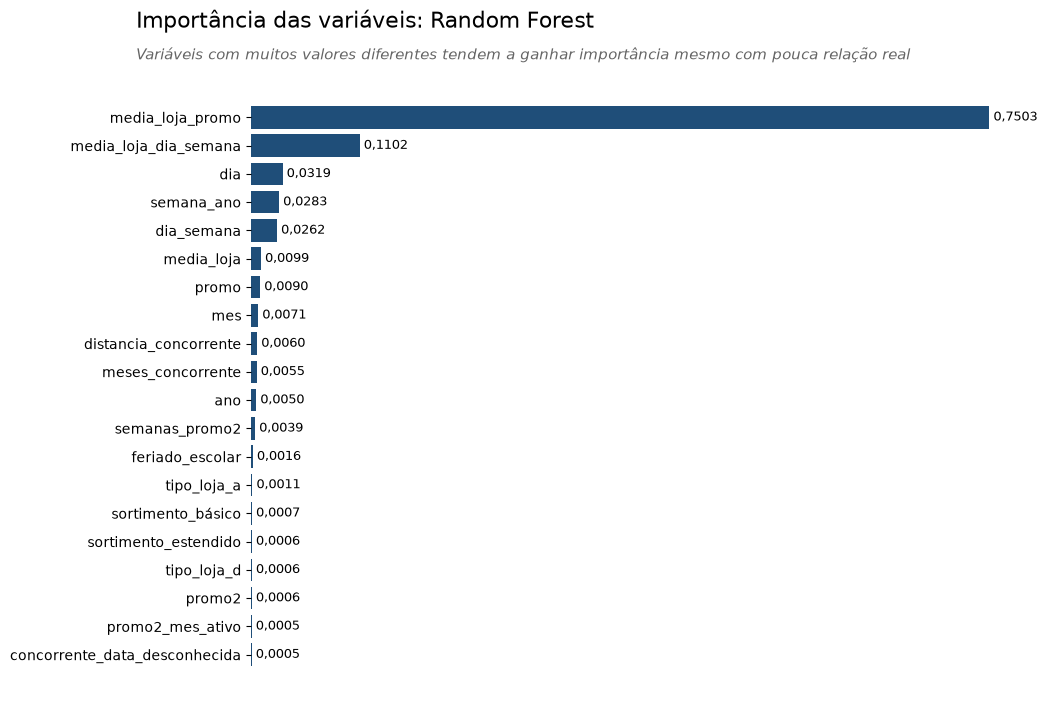

In [39]:
# Transformando o treino em números (médias da loja e one-hot ajustados só no treino)
preparo_sel = clone(montar_modelo(None).regressor).set_params(modelo='passthrough')
X_treino_t = pd.DataFrame(preparo_sel.fit_transform(X_treino, np.log1p(y_treino)), index=X_treino.index,
                          columns=preparo_sel.get_feature_names_out())
y_treino_log = np.log1p(y_treino)
print(f'treino transformado .... {X_treino_t.shape}')

# Random Forest - classificação das melhores variáveis (amostra de 100 mil linhas)
amostra_rf = X_treino_t.sample(100_000, random_state=SEMENTE).index
importances = importancia_random_forest(X_treino_t.loc[amostra_rf], y_treino_log.loc[amostra_rf], tipo='regressao',
                                        semente=SEMENTE, n_estimators=50, min_samples_leaf=5)
print(importances.head(20).round(4).to_string())

plot_barras_h(importances.head(20), 'Importância das variáveis: Random Forest', 'Importancia RF (selecao)',
              subtitulo='Variáveis com muitos valores diferentes tendem a ganhar importância mesmo com pouca relação real',
              formato=lambda v: f'{v:.4f}'.replace('.', ','))

🎯 RANKING DE FEATURES POR MUTUAL INFORMATION (28 colunas):
                          feature  score
0                media_loja_promo  0.773
1           media_loja_dia_semana  0.640
2                      media_loja  0.443
3                           promo  0.098
4                      semana_ano  0.069
5           distancia_concorrente  0.066
6                      dia_semana  0.040
7                             dia  0.037
8                             mes  0.016
9                  semanas_promo2  0.015
10              meses_concorrente  0.013
11                    tipo_loja_a  0.010
12                    tipo_loja_d  0.009
13                    tipo_loja_b  0.007
14                            ano  0.007
15                         promo2  0.006
16               promo2_mes_ativo  0.003
17              sortimento_básico  0.003
18  concorrente_data_desconhecida  0.002
19               sortimento_extra  0.002
20           sortimento_estendido  0.002
21                sem_concorrente  0.00

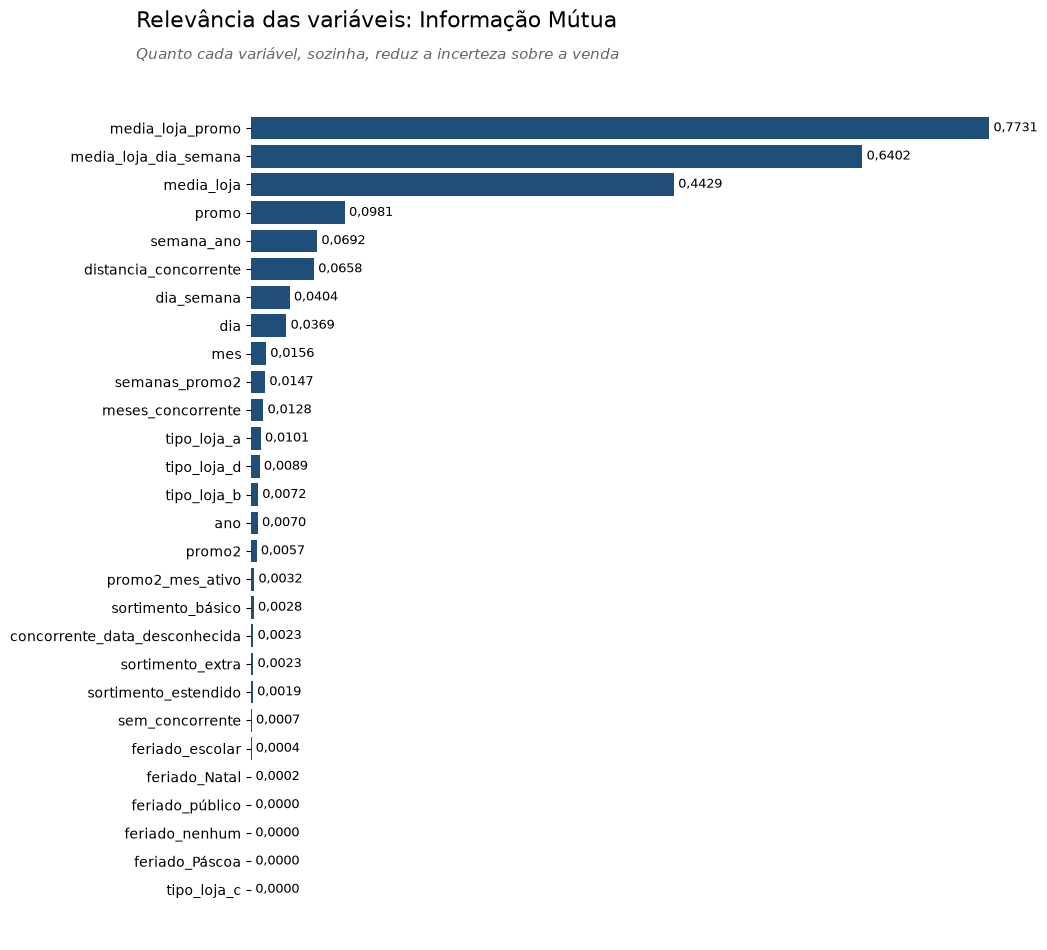

In [40]:
# Informação Mútua - ranking de todas as colunas e seleção das 10 melhores (amostra de 30 mil linhas)
amostra_mi = X_treino_t.sample(30_000, random_state=SEMENTE).index
df_scores, selector = selecao_features(X_treino_t.loc[amostra_mi], y_treino_log.loc[amostra_mi], k=10, tipo='regressao',
                                       semente=SEMENTE)

print(f'🎯 RANKING DE FEATURES POR MUTUAL INFORMATION ({X_treino_t.shape[1]} colunas):')
print('=' * 50)
print(df_scores.round(4).to_string())
print(f"\ncolunas com informação mútua igual a zero: {(df_scores['score'] == 0).sum()} de {len(df_scores)}")

print('\n🏆 TOP 10 FEATURES SELECIONADAS:')
print('=' * 50)
top_10_features = df_scores.head(10)['feature'].tolist()
for i, (feature, score) in enumerate(df_scores.head(10).itertuples(index=False), 1):
    print(f'{i}. {feature}: {score:.6f}')

X_treino_selecionado = selector.transform(X_treino_t.loc[amostra_mi])
print(f'\n📊 Shape original: {X_treino_t.loc[amostra_mi].shape}')
print(f'📊 Shape após seleção: {X_treino_selecionado.shape}')
print(f'📊 Features selecionadas: {top_10_features}')

plot_barras_h(df_scores.set_index('feature')['score'], 'Relevância das variáveis: Informação Mútua',
              'Informacao mutua (selecao)', subtitulo='Quanto cada variável, sozinha, reduz a incerteza sobre a venda',
              formato=lambda v: f'{v:.4f}'.replace('.', ','))

In [41]:
# Comparação dos dois rankings
comparacao_selecao = pd.DataFrame({
    'posição RF': importances.rank(ascending=False).astype(int),
    'posição Informação Mútua': df_scores.set_index('feature')['score'].rank(ascending=False, method='first').astype(int),
}).sort_values('posição RF')
comparacao_selecao

,posição RF,posição Informação Mútua
media_loja_promo,1,1
media_loja_dia_semana,2,2
dia,3,8
semana_ano,4,5
dia_semana,5,7
media_loja,6,3
promo,7,4
mes,8,9
distancia_concorrente,9,6
meses_concorrente,10,11


📌 **Nota**
- 🔎 Os dois métodos concordam no topo: as **médias da loja** são as variáveis mais relevantes. A média com/sem promoção (`media_loja_promo`) tem **0,750** da importância do Random Forest, e as três médias são as 3 primeiras na Informação Mútua (**0,773**, **0,640** e **0,443**).
- 🔎 Depois vêm a **promoção**, o **dia da semana**, o **dia do mês** e a **semana do ano**, como a EDA indicava (H1, H6, H7 e H8).
- 🔎 Só **4 de 28** colunas têm Informação Mútua exatamente **zero**, e o fim dos dois rankings é ocupado pelas colunas de **feriado**, pelo feriado escolar e pelo tipo de loja c. Os feriados são raros (0,1% dos dias com venda).
- ✅ **Decisão:** manter as **18 variáveis**. As árvores ignoram sozinhas as que não ajudam, e a confirmação abaixo mostra que retirar variáveis piora o modelo.

#### Confirmação: o modelo melhora com as médias da loja e com as variáveis criadas?

Os dois métodos acima olham cada coluna isoladamente. Como confirmação, comparamos o mesmo modelo rápido (LightGBM com 300 árvores) com **3 conjuntos de variáveis**, treinando no treino e medindo na validação.

In [42]:
lgbm_rapido = lambda: lgb.LGBMRegressor(n_estimators=300, learning_rate=0.1, num_leaves=63, random_state=SEMENTE,
                                        n_jobs=N_JOBS, verbose=-1)
criadas_modelo = ['sem_concorrente', 'meses_concorrente', 'concorrente_data_desconhecida', 'semanas_promo2', 'promo2_mes_ativo']

# 1) Número da loja como número, sem as médias (como na versão original)
sem_medias = TransformedTargetRegressor(Pipeline([
    ('preparo', ColumnTransformer([('categorias', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CATEGORICAS)],
                                  remainder='passthrough')),
    ('modelo', lgbm_rapido())]), func=np.log1p, inverse_func=np.expm1)
conjuntos = {
    'Número da loja, sem médias': (sem_medias, FEATURES),
    'Médias da loja, sem as variáveis criadas': (montar_modelo(lgbm_rapido()), [f for f in FEATURES if f not in criadas_modelo]),
    'Médias da loja + variáveis criadas (todas)': (montar_modelo(lgbm_rapido()), FEATURES),
}
confirmacao = {}
for nome, (modelo, colunas) in conjuntos.items():
    t0 = time.time()
    modelo.fit(X_treino[colunas], y_treino)
    previsto = modelo.predict(X_validacao[colunas])
    confirmacao[nome] = ml_error(nome, y_validacao, previsto).iloc[0].to_dict() | {
        'Erro do total por loja': erro_total_6_semanas(X_validacao['loja'], y_validacao, previsto), 'tempo (s)': time.time() - t0}
pd.DataFrame(confirmacao).T.round(3)

,MAE (€),MAPE,RMSE (€),R²,MPE,Erro do total por loja,tempo (s)
"Número da loja, sem médias",897.442,0.125,"1,262.153",0.829,-0.016,0.070,38.911
"Médias da loja, sem as variáveis criadas",720.665,0.101,"1,013.036",0.890,-0.023,0.056,40.853
Médias da loja + variáveis criadas (todas),692.227,0.097,970.854,0.899,-0.020,0.048,42.047


📌 **Nota**

| Conjunto de variáveis | MAPE | Erro do total por loja |
|---|---|---|
| Número da loja, sem médias (como na v1) | 12,5% | 7,0% |
| Médias da loja, sem as variáveis criadas | 10,1% | 5,6% |
| **Médias da loja + variáveis criadas** | **9,7%** | **4,8%** |

- 🔎 Trocar o número da loja pelas **médias da loja** baixa o erro do total de **7,0%** para **5,6%**.
- 🔎 As variáveis criadas na Fase 02 (concorrência e Promo2) baixam mais um pouco, para **4,8%**.
- ✅ **Decisão:** usar o conjunto completo em todos os modelos.

## 5 - Treinamento dos Algoritmos de Machine Learning

**Treinar** um algoritmo é mostrar a ele exemplos (os dias do treino, com a venda real) para que ele aprenda os padrões. Depois, pedimos que ele **preveja** as 6 semanas da **validação**, que nunca viu, e comparamos com a resposta verdadeira (o **gabarito**).

**Como vamos medir o desempenho** (função `ml_error`, `src/avaliacao.py`):

| Métrica | Pergunta que ela responde |
|---|---|
| **MAE** | Em média, quantos **euros** a previsão de um dia erra? |
| **MAPE** | Em média, quanto o erro de um dia representa **em relação à venda real**? |
| **RMSE** | Como o MAE, mas **pune mais os erros grandes** |
| **R²** | Quanto das diferenças de venda entre os dias e as lojas o modelo **explica** (0 = nada, 1 = tudo) |
| **MPE** | O modelo tende a **superestimar** (positivo) ou **subestimar** (negativo)? |
| **Erro do total por loja** | Somando as 6 semanas, quanto o **total previsto de uma loja** erra o total real, em média? É o número que o CFO usa |

**Réguas de comparação:**
- **Média da loja (referência):** prevê sempre a venda média de cada loja no treino. Todo algoritmo útil precisa superá-la.
- **Média da loja × dia da semana × promoção:** é o que uma boa **planilha** faria. Superá-la mostra que o modelo vale o esforço.

Cada algoritmo é avaliado pela função `relatorio_validacao`, que mostra sempre as mesmas peças: amostra gabarito × previsão, métricas, **MAE no treino × validação** (para detectar **sobreajuste**, quando o modelo "decora" o treino) e os gráficos de previsto × real e de distribuição do erro.

### Média da loja (referência)

O modelo de **referência** prevê, para cada dia, a **venda média da loja** no treino. Ele não sabe nada de promoção, dia da semana ou época do ano: serve de piso de comparação.

Média da loja treinado em 0.1s

AMOSTRA: GABARITO x PREVISÃO DA MÁQUINA (venda do dia em €)


,Loja,Gabarito,Previsão da máquina,Erro (€)
20796,540,"10,920.000","5,466.000","-5,454.000"
25008,976,"9,788.000","6,971.000","-2,817.000"
22176,805,"6,195.000","6,136.000",-59.000
14914,265,"5,412.000","4,909.000",-503.000
1067,1069,"6,098.000","6,304.000",206.000
13898,429,"5,267.000","5,308.000",41.000


MÉTRICAS DE VALIDAÇÃO: Média da loja (referência)
MAE (€)                1,337.554
MAPE                       0.199
RMSE (€)               1,816.773
R²                         0.645
MPE                        0.012
Erro do total por loja     0.069

MAE no treino: € 1.462 | na validação: € 1.338 | diferença: -124 €


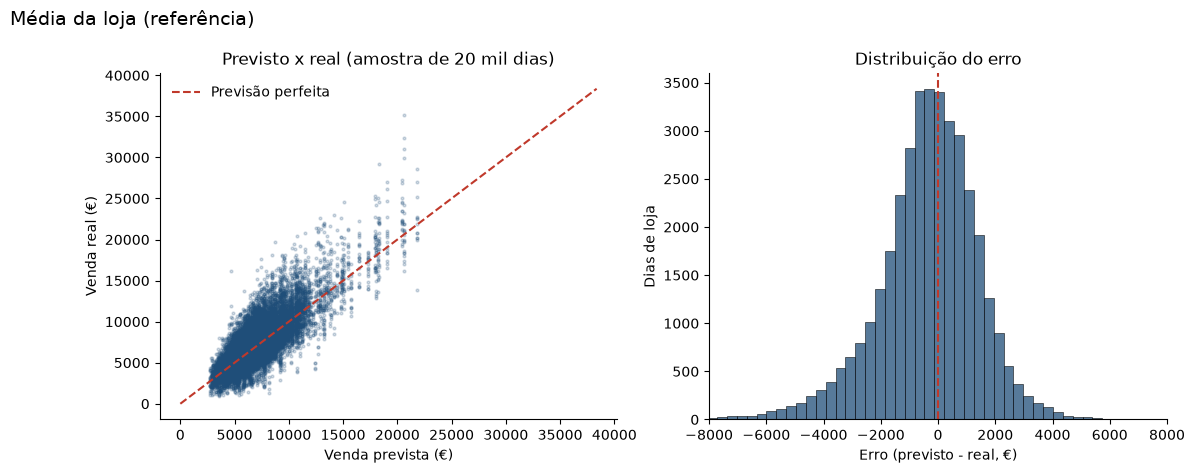

In [43]:
model_media = MediaPorGrupo(grupos=('loja',))

t0 = time.time()
model_media.fit(X_treino, y_treino)
print(f'Média da loja treinado em {time.time() - t0:.1f}s' + chr(10))

# Avaliação na VALIDAÇÃO (6 semanas que o modelo não viu)
metricas_media, previsto_media = relatorio_validacao('Média da loja (referência)', model_media, X_treino, y_treino,
                                                     X_validacao, y_validacao, 'Validacao media da loja')

In [44]:
# Como a versão original calculava o "modelo da média": média de cada loja calculada NAS PRÓPRIAS semanas avaliadas
media_com_gabarito = y_validacao.groupby(X_validacao['loja']).transform('mean')
pd.concat([metricas_media.drop(columns='MAE treino (€)'),
           ml_error('Média da loja da v1 (usa o gabarito)', y_validacao, media_com_gabarito).assign(
               **{'Erro do total por loja': erro_total_6_semanas(X_validacao['loja'], y_validacao, media_com_gabarito)})]).round(3)

,MAE (€),MAPE,RMSE (€),R²,MPE,Erro do total por loja
Média da loja (referência),"1,337.554",0.199,"1,816.773",0.645,0.012,0.069
Média da loja da v1 (usa o gabarito),"1,256.126",0.195,"1,688.302",0.693,0.060,0.000


📌 **Nota**
- 🔎 Prevendo sempre a média de cada loja, o erro do dia é de **€ 1.338** (MAPE de **19,9%**), e o erro do total de 6 semanas por loja é de **6,9%**.
- 🔎 O total erra bem menos que o dia: somando 36 dias, os erros para cima e para baixo se compensam. É por isso que o erro do total é a métrica do negócio.
- ⚠️ A versão original calculava a média de cada loja **nas próprias semanas avaliadas** (tabela acima). Com isso, o erro do total é **0,0%** por construção: a média do período × o número de dias **é** o total real. A régua "colava" a resposta.
- ✅ **Decisão:** a referência da v2 usa só a média do **treino**. Todo modelo precisa ficar abaixo de **6,9%** no total.

### Média da loja × dia da semana × promoção (planilha)

Prevê a venda média da loja **naquele dia da semana**, **com ou sem promoção**, no treino. É uma regra simples que um analista faria numa planilha.

Planilha treinada em 0.2s

AMOSTRA: GABARITO x PREVISÃO DA MÁQUINA (venda do dia em €)


,Loja,Gabarito,Previsão da máquina,Erro (€)
20796,540,"10,920.000","8,450.000","-2,470.000"
25008,976,"9,788.000","7,975.000","-1,813.000"
22176,805,"6,195.000","7,005.000",810.000
14914,265,"5,412.000","4,053.000","-1,359.000"
1067,1069,"6,098.000","6,160.000",62.000
13898,429,"5,267.000","5,143.000",-124.000


MÉTRICAS DE VALIDAÇÃO: Planilha (loja x dia x promoção)


MAE (€)                  787.283
MAPE                       0.109
RMSE (€)               1,103.948
R²                         0.869
MPE                       -0.043
Erro do total por loja     0.072

MAE no treino: € 801 | na validação: € 787 | diferença: -14 €


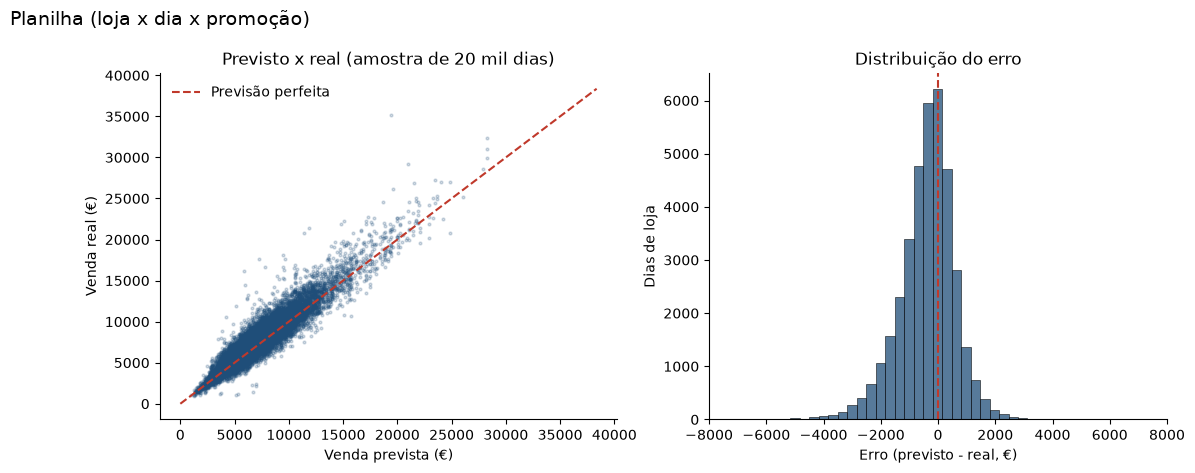

In [45]:
model_planilha = MediaPorGrupo(grupos=('loja', 'dia_semana', 'promo'))

t0 = time.time()
model_planilha.fit(X_treino, y_treino)
print(f'Planilha treinada em {time.time() - t0:.1f}s' + chr(10))

metricas_planilha, previsto_planilha = relatorio_validacao('Planilha (loja x dia x promoção)', model_planilha, X_treino, y_treino,
                                                           X_validacao, y_validacao)

📌 **Nota**
- 🔎 A planilha (média da loja por dia da semana e promoção) baixa o erro do dia para **€ 787** (MAPE de **10,9%**): só promoção e dia da semana já explicam boa parte da venda.
- 🔎 Mas o erro do **total** fica em **7,2%**, pior que o da média simples (**6,9%**). A planilha **subestima** a validação (MPE de **−4,3%**), porque usa a média de 2013 a 2015 e as vendas crescem ano a ano (H5).
- 🔎 Treino (**€ 801**) e validação (**€ 787**) quase iguais: sem sobreajuste.
- ✅ **Decisão:** o modelo precisa superar a planilha **também no total**. A tendência de crescimento é uma das coisas que ele precisa aprender.

### Regressão Linear

A **Regressão Linear** soma o efeito de cada variável com um **peso** (uma reta em várias dimensões). É o modelo mais simples e **fácil de explicar**. Como o alvo está em log, cada peso vira um **percentual** de aumento ou queda da venda.

Regressão Linear treinado em 6.1s



AMOSTRA: GABARITO x PREVISÃO DA MÁQUINA (venda do dia em €)


,Loja,Gabarito,Previsão da máquina,Erro (€)
20796,540,"10,920.000","7,361.000","-3,559.000"
25008,976,"9,788.000","9,255.000",-533.000
22176,805,"6,195.000","6,976.000",781.000
14914,265,"5,412.000","4,197.000","-1,215.000"
1067,1069,"6,098.000","7,534.000","1,436.000"
13898,429,"5,267.000","4,865.000",-402.000


MÉTRICAS DE VALIDAÇÃO: Regressão Linear
MAE (€)                  861.740
MAPE                       0.119
RMSE (€)               1,188.542
R²                         0.848
MPE                       -0.014
Erro do total por loja     0.060

MAE no treino: € 885 | na validação: € 862 | diferença: -23 €


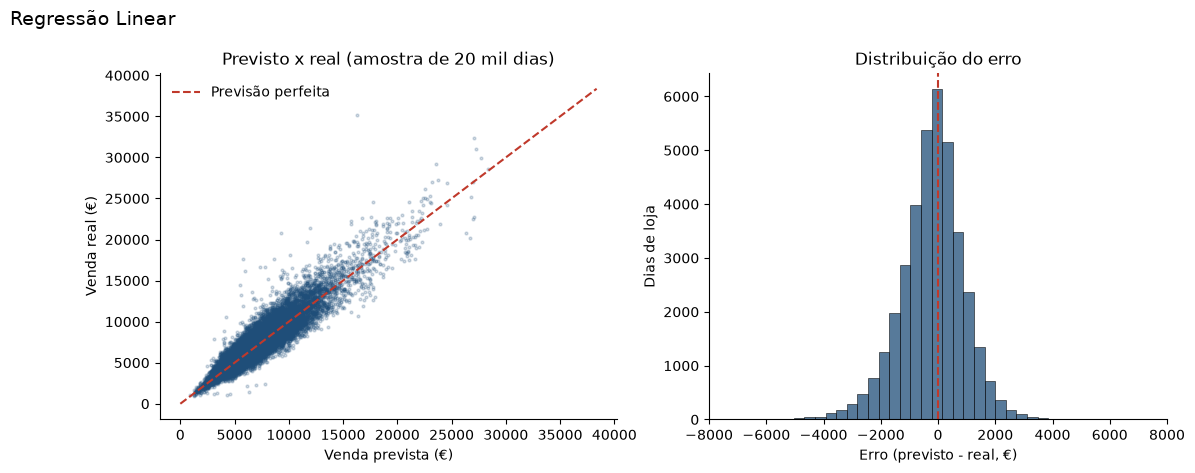

In [46]:
model_lr = montar_modelo(LinearRegression(), linear=True)

t0 = time.time()
model_lr.fit(X_treino, y_treino)
print(f'Regressão Linear treinado em {time.time() - t0:.1f}s' + chr(10))

# Avaliação na VALIDAÇÃO (6 semanas que o modelo não viu)
metricas_lr, previsto_lr = relatorio_validacao('Regressão Linear', model_lr, X_treino, y_treino, X_validacao, y_validacao)

📌 **Nota**
- 🔎 Erro do dia de **€ 862** (MAPE de **11,9%**) e erro do total de **6,0%**: melhor que as duas réguas no total, mas pior que a planilha no dia.
- 🔎 Treino (**€ 885**) e validação (**€ 862**) parecidos: sem sobreajuste. O modelo é simples demais para combinações como "promoção em dezembro numa loja grande".

### Lasso

O **Lasso** é uma regressão linear **regularizada**: ele "encolhe" os pesos e pode zerar os de variáveis pouco úteis, o que evita exagerar padrões do treino.

Lasso treinado em 14.9s

AMOSTRA: GABARITO x PREVISÃO DA MÁQUINA (venda do dia em €)


,Loja,Gabarito,Previsão da máquina,Erro (€)
20796,540,"10,920.000","7,291.000","-3,629.000"
25008,976,"9,788.000","9,112.000",-676.000
22176,805,"6,195.000","6,952.000",757.000
14914,265,"5,412.000","4,231.000","-1,181.000"
1067,1069,"6,098.000","7,409.000","1,311.000"
13898,429,"5,267.000","4,815.000",-452.000


MÉTRICAS DE VALIDAÇÃO: Lasso
MAE (€)                  863.626
MAPE                       0.119
RMSE (€)               1,189.347
R²                         0.848
MPE                       -0.017
Erro do total por loja     0.061

MAE no treino: € 887 | na validação: € 864 | diferença: -23 €


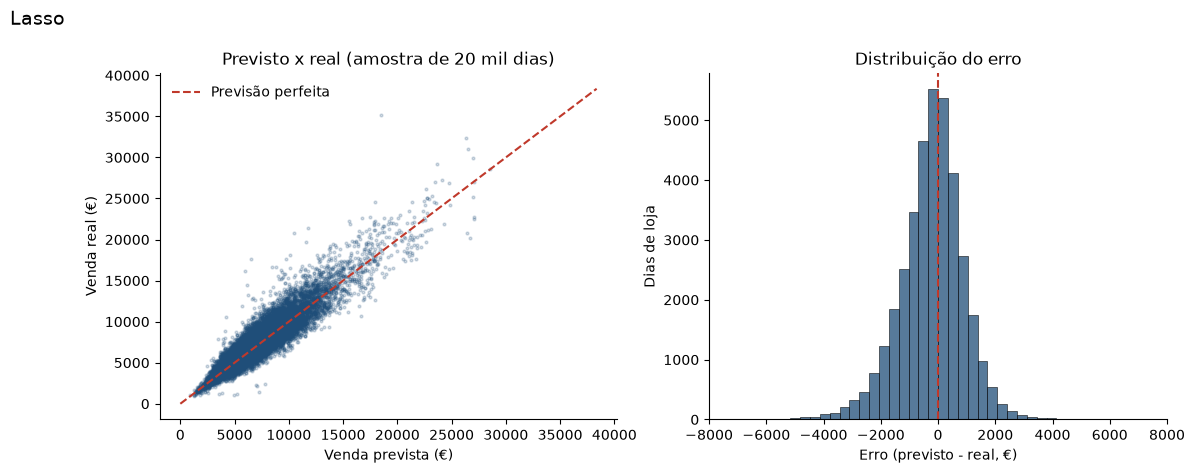

In [47]:
model_lasso = montar_modelo(Lasso(alpha=0.001, random_state=SEMENTE), linear=True)

t0 = time.time()
model_lasso.fit(X_treino, y_treino)
print(f'Lasso treinado em {time.time() - t0:.1f}s' + chr(10))

# Avaliação na VALIDAÇÃO (6 semanas que o modelo não viu)
metricas_lasso, previsto_lasso = relatorio_validacao('Lasso', model_lasso, X_treino, y_treino, X_validacao, y_validacao)

📌 **Nota**
- 🔎 Praticamente igual à Regressão Linear (**€ 864**, MAPE de **11,9%**, total de **6,1%**). Com 765 mil dias e só 28 colunas, não há excesso de variáveis para a regularização cortar.

### Random Forest

O **Random Forest** treina **várias árvores de decisão independentes**, cada uma com uma parte dos dados, e tira a **média** das previsões, como pedir a opinião de vários especialistas.

> 💻 Para caber na memória da máquina (8 GB), cada árvore usa **25% dos dias** sorteados (`max_samples`) e folhas com pelo menos 5 dias. A versão original usava 100 árvores sem limite.

Random Forest treinado em 97.9s



AMOSTRA: GABARITO x PREVISÃO DA MÁQUINA (venda do dia em €)


,Loja,Gabarito,Previsão da máquina,Erro (€)
20796,540,"10,920.000","8,585.000","-2,335.000"
25008,976,"9,788.000","8,072.000","-1,716.000"
22176,805,"6,195.000","7,334.000","1,139.000"
14914,265,"5,412.000","4,092.000","-1,320.000"
1067,1069,"6,098.000","6,333.000",235.000
13898,429,"5,267.000","5,086.000",-181.000


MÉTRICAS DE VALIDAÇÃO: Random Forest
MAE (€)                  711.584
MAPE                       0.098
RMSE (€)               1,019.556
R²                         0.888
MPE                       -0.039
Erro do total por loja     0.062

MAE no treino: € 484 | na validação: € 712 | diferença: +227 €


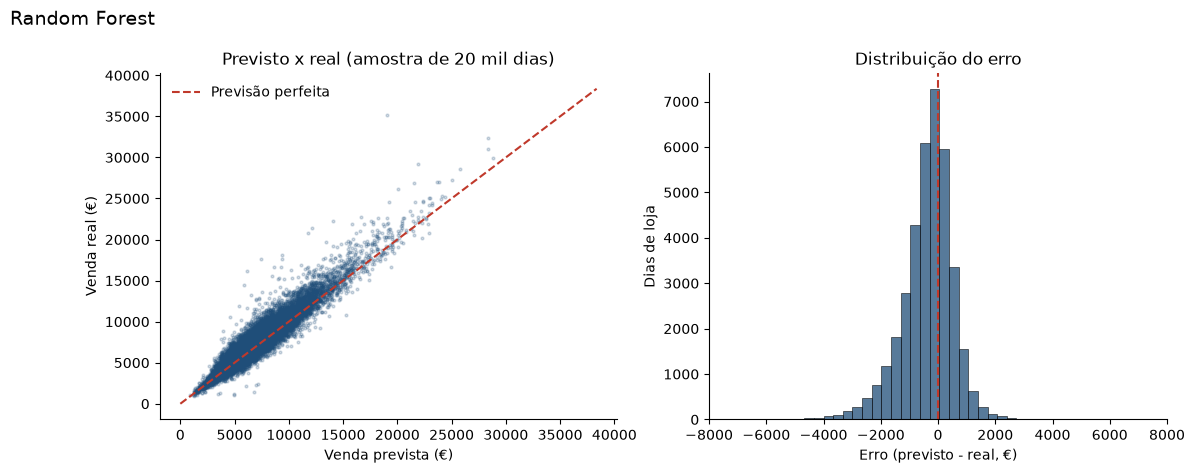

In [48]:
model_rf = montar_modelo(RandomForestRegressor(n_estimators=60, max_samples=0.25, min_samples_leaf=5, max_features=0.5, random_state=SEMENTE, n_jobs=N_JOBS))

t0 = time.time()
model_rf.fit(X_treino, y_treino)
print(f'Random Forest treinado em {time.time() - t0:.1f}s' + chr(10))

# Avaliação na VALIDAÇÃO (6 semanas que o modelo não viu)
metricas_rf, previsto_rf = relatorio_validacao('Random Forest', model_rf, X_treino, y_treino, X_validacao, y_validacao)

📌 **Nota**
- 🔎 O Random Forest baixa o erro do dia para **€ 712** (MAPE de **9,8%**), mas o erro do total fica em **6,2%**, quase igual ao da Regressão Linear. Ele **subestima** a validação (MPE de **−3,9%**): a média das árvores não acompanha a tendência de alta.
- 🔎 Treino **€ 484** × validação **€ 712** (diferença de **+€ 227**): há algum sobreajuste.

### XGBoost

O **XGBoost** constrói **árvores em sequência**: cada nova árvore olha para os erros das anteriores e tenta corrigi-los.

> ⚠️ Na versão original, o parâmetro `colsample_bytee` estava **digitado errado** (o certo é `colsample_bytree`) e era ignorado em silêncio. Com taxa de aprendizado de 0,01 e só 100 árvores, o primeiro XGBoost errava **95%** da venda (MAPE de 0,95): ele mal tinha começado a aprender.

XGBoost treinado em 77.8s



AMOSTRA: GABARITO x PREVISÃO DA MÁQUINA (venda do dia em €)


,Loja,Gabarito,Previsão da máquina,Erro (€)
20796,540,"10,920.000","10,154.000",-766.000
25008,976,"9,788.000","8,426.000","-1,362.000"
22176,805,"6,195.000","7,180.000",985.000
14914,265,"5,412.000","4,194.000","-1,218.000"
1067,1069,"6,098.000","6,435.000",337.000
13898,429,"5,267.000","5,035.000",-232.000


MÉTRICAS DE VALIDAÇÃO: XGBoost
MAE (€)                687.970
MAPE                     0.097
RMSE (€)               961.418
R²                       0.901
MPE                     -0.016
Erro do total por loja   0.044

MAE no treino: € 452 | na validação: € 688 | diferença: +235 €


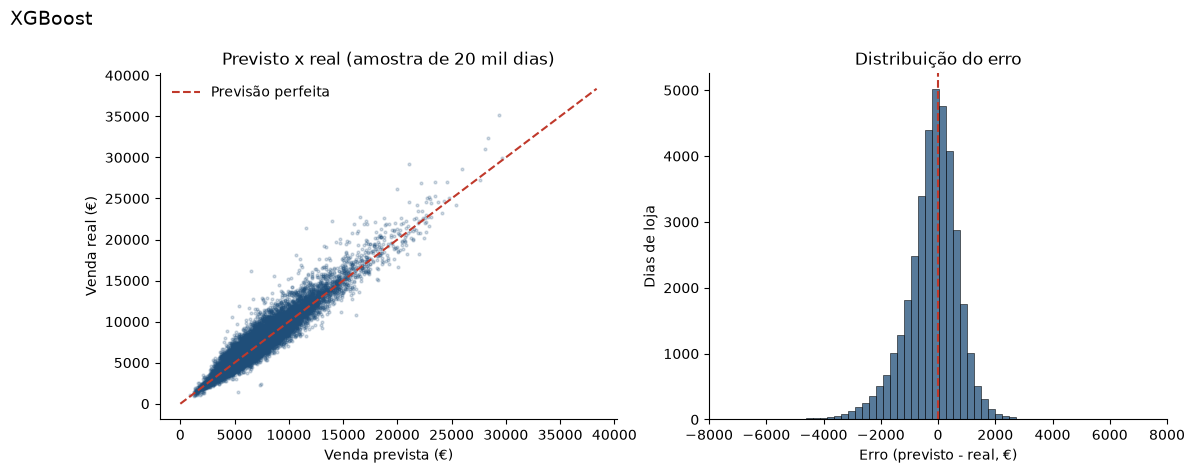

In [49]:
model_xgb = montar_modelo(xgb.XGBRegressor(n_estimators=300, learning_rate=0.1, max_depth=8, subsample=0.8, colsample_bytree=0.8, tree_method="hist", random_state=SEMENTE, n_jobs=N_JOBS))

t0 = time.time()
model_xgb.fit(X_treino, y_treino)
print(f'XGBoost treinado em {time.time() - t0:.1f}s' + chr(10))

# Avaliação na VALIDAÇÃO (6 semanas que o modelo não viu)
metricas_xgb, previsto_xgb = relatorio_validacao('XGBoost', model_xgb, X_treino, y_treino, X_validacao, y_validacao)

📌 **Nota**
- 🔎 O XGBoost tem o menor erro do dia (**€ 688**, MAPE de **9,7%**) e o menor erro do total (**4,4%**), com R² de **0,901**.
- 🔎 Treino **€ 452** × validação **€ 688** (**+€ 235**): diferença parecida com a dos outros modelos de árvores, sem sinal de que ele "decorou" o treino.

### LightGBM

O **LightGBM** segue a mesma ideia do XGBoost, mas cresce cada árvore pelo galho mais promissor, o que o deixa **mais rápido**.

LightGBM treinado em 23.2s



AMOSTRA: GABARITO x PREVISÃO DA MÁQUINA (venda do dia em €)


,Loja,Gabarito,Previsão da máquina,Erro (€)
20796,540,"10,920.000","9,540.000","-1,380.000"
25008,976,"9,788.000","8,398.000","-1,390.000"
22176,805,"6,195.000","7,655.000","1,460.000"
14914,265,"5,412.000","4,164.000","-1,248.000"
1067,1069,"6,098.000","6,662.000",564.000
13898,429,"5,267.000","5,205.000",-62.000


MÉTRICAS DE VALIDAÇÃO: LightGBM
MAE (€)                692.227
MAPE                     0.097
RMSE (€)               970.854
R²                       0.899
MPE                     -0.020
Erro do total por loja   0.048

MAE no treino: € 499 | na validação: € 692 | diferença: +193 €


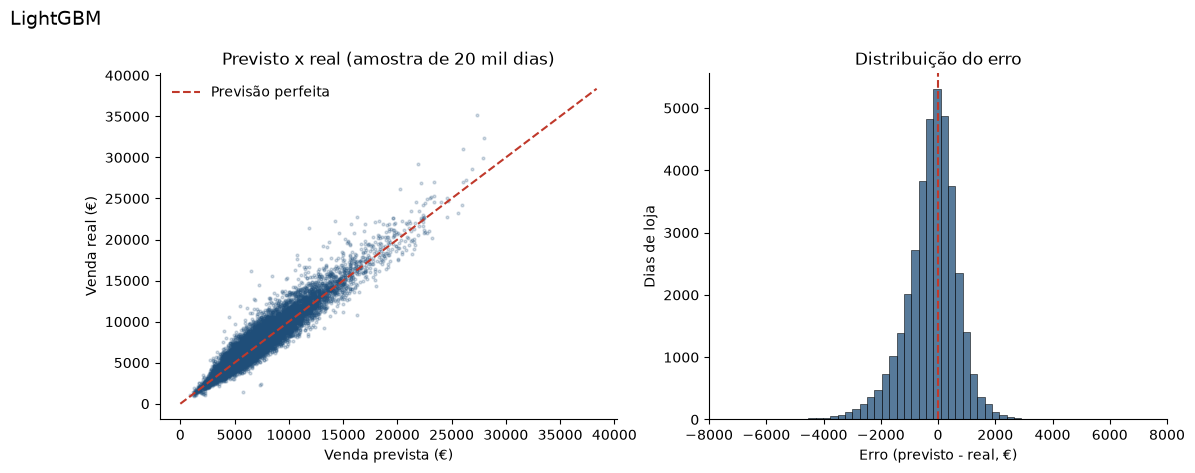

In [50]:
model_lgbm = montar_modelo(lgb.LGBMRegressor(n_estimators=300, learning_rate=0.1, num_leaves=63, random_state=SEMENTE, n_jobs=N_JOBS, verbose=-1))

t0 = time.time()
model_lgbm.fit(X_treino, y_treino)
print(f'LightGBM treinado em {time.time() - t0:.1f}s' + chr(10))

# Avaliação na VALIDAÇÃO (6 semanas que o modelo não viu)
metricas_lgbm, previsto_lgbm = relatorio_validacao('LightGBM', model_lgbm, X_treino, y_treino, X_validacao, y_validacao)

📌 **Nota**
- 🔎 Quase empatado com o XGBoost: **€ 692**, MAPE de **9,7%** e erro do total de **4,8%**, em **24 s** de treino (o XGBoost levou **68 s**).
- 🔎 Treino **€ 499** × validação **€ 692** (**+€ 193**): o menor sobreajuste entre os modelos de árvores.

### HistGradientBoosting

O **HistGradientBoosting** (do scikit-learn) também constrói árvores em sequência, agrupando os valores em faixas para ganhar velocidade.

HistGradientBoosting treinado em 72.8s



AMOSTRA: GABARITO x PREVISÃO DA MÁQUINA (venda do dia em €)


,Loja,Gabarito,Previsão da máquina,Erro (€)
20796,540,"10,920.000","9,700.000","-1,220.000"
25008,976,"9,788.000","8,412.000","-1,376.000"
22176,805,"6,195.000","7,393.000","1,198.000"
14914,265,"5,412.000","4,121.000","-1,291.000"
1067,1069,"6,098.000","6,628.000",530.000
13898,429,"5,267.000","4,923.000",-344.000


MÉTRICAS DE VALIDAÇÃO: HistGradientBoosting
MAE (€)                705.796
MAPE                     0.098
RMSE (€)               992.645
R²                       0.894
MPE                     -0.022
Erro do total por loja   0.050

MAE no treino: € 498 | na validação: € 706 | diferença: +207 €


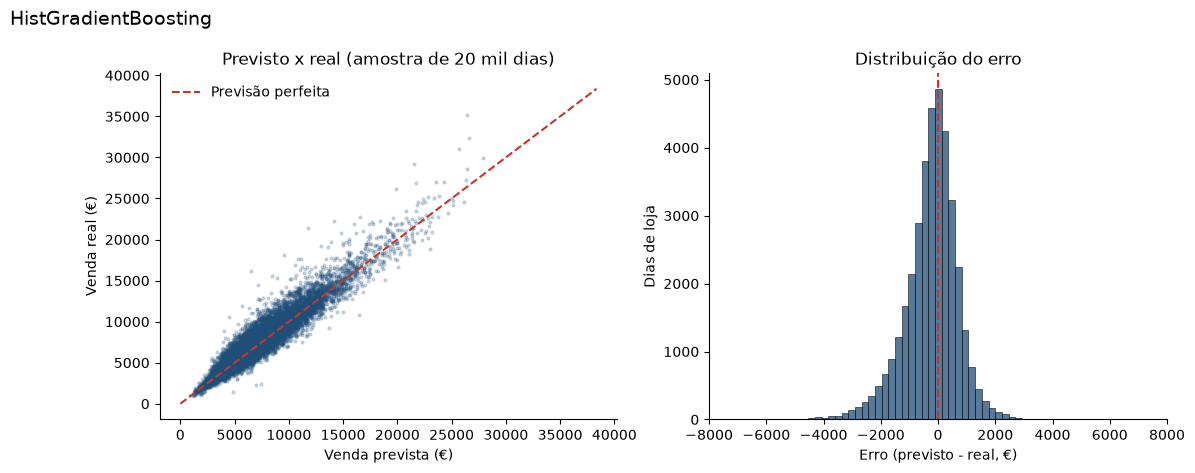

In [51]:
model_hgb = montar_modelo(HistGradientBoostingRegressor(max_iter=300, learning_rate=0.1, max_leaf_nodes=63, random_state=SEMENTE))

t0 = time.time()
model_hgb.fit(X_treino, y_treino)
print(f'HistGradientBoosting treinado em {time.time() - t0:.1f}s' + chr(10))

# Avaliação na VALIDAÇÃO (6 semanas que o modelo não viu)
metricas_hgb, previsto_hgb = relatorio_validacao('HistGradientBoosting', model_hgb, X_treino, y_treino, X_validacao, y_validacao)

📌 **Nota**
- 🔎 Também perto dos outros dois: **€ 706**, MAPE de **9,8%** e erro do total de **5,0%**. Treino **€ 498** × validação **€ 706** (**+€ 207**).
- 🔎 Os três modelos de árvores em sequência (XGBoost, LightGBM e HGB) ficam a menos de **0,1 ponto** de MAPE entre si nesta validação. A validação cruzada decide.

### Validação cruzada

Agora a comparação é repetida nas **5 janelas de 6 semanas** (item 4.1), sempre treinando no passado. O resultado é a **média ± desvio**. É ela que decide o algoritmo do ajuste fino.

> 💻 São 8 modelos × 5 janelas: a célula leva cerca de **20 minutos**.

In [52]:
modelos = {'Média da loja (referência)': model_media, 'Planilha (loja x dia x promoção)': model_planilha,
           'Regressão Linear': model_lr, 'Lasso': model_lasso, 'Random Forest': model_rf, 'XGBoost': model_xgb,
           'LightGBM': model_lgbm, 'HistGradientBoosting': model_hgb}

resultados_cv, mape_cv, total_cv, detalhe_cv = {}, {}, {}, []
t0 = time.time()
for nome, modelo in modelos.items():
    por_dobra = []
    for i, (indices_treino, indices_avaliacao) in enumerate(dobras, 1):
        ajustado = clone(modelo).fit(X_treino_val.iloc[indices_treino], y_treino_val.iloc[indices_treino])
        real = y_treino_val.iloc[indices_avaliacao]
        previsto = ajustado.predict(X_treino_val.iloc[indices_avaliacao])
        metricas = ml_error(nome, real, previsto)
        metricas['Erro do total por loja'] = erro_total_6_semanas(X_treino_val['loja'].iloc[indices_avaliacao], real, previsto)
        por_dobra.append(metricas.assign(dobra=i))
    por_dobra = pd.concat(por_dobra)
    detalhe_cv.append(por_dobra)
    mape_cv[nome], total_cv[nome] = por_dobra['MAPE'].mean(), por_dobra['Erro do total por loja'].mean()
    resultados_cv[nome] = {'MAE CV (€)': f"{por_dobra['MAE (€)'].mean():,.0f} ± {por_dobra['MAE (€)'].std():,.0f}".replace(',', '.'),
                           'MAPE CV': f"{mape_cv[nome]:.1%} ± {por_dobra['MAPE'].std():.1%}",
                           'Erro do total por loja CV': f"{total_cv[nome]:.1%} ± {por_dobra['Erro do total por loja'].std():.1%}",
                           'R² CV': f"{por_dobra['R²'].mean():.3f} ± {por_dobra['R²'].std():.3f}"}
    print(f'{nome}: {time.time() - t0:.0f}s acumulados')
tabela_cv = pd.DataFrame(resultados_cv).T
detalhe_cv = pd.concat(detalhe_cv)
tabela_cv

Média da loja (referência): 1s acumulados


Planilha (loja x dia x promoção): 3s acumulados


Regressão Linear: 26s acumulados


Lasso: 93s acumulados


Random Forest: 458s acumulados


XGBoost: 760s acumulados


LightGBM: 869s acumulados


HistGradientBoosting: 1154s acumulados


,MAE CV (€),MAPE CV,Erro do total por loja CV,R² CV
Média da loja (referência),1.589 ± 445,22.9% ± 2.9%,9.4% ± 5.5%,0.567 ± 0.121
Planilha (loja x dia x promoção),991 ± 501,13.1% ± 4.6%,9.2% ± 5.3%,0.797 ± 0.142
Regressão Linear,1.028 ± 376,13.7% ± 3.1%,8.4% ± 4.2%,0.789 ± 0.104
Lasso,1.033 ± 383,13.7% ± 3.2%,8.5% ± 4.4%,0.787 ± 0.106
Random Forest,792 ± 204,10.8% ± 1.7%,6.1% ± 0.6%,0.866 ± 0.037
XGBoost,766 ± 165,10.6% ± 1.3%,4.8% ± 0.9%,0.880 ± 0.025
LightGBM,771 ± 171,10.7% ± 1.4%,5.0% ± 0.6%,0.880 ± 0.025
HistGradientBoosting,765 ± 163,10.6% ± 1.3%,5.0% ± 0.6%,0.881 ± 0.022


In [53]:
# MAPE de cada modelo em cada janela: a ordem dos modelos se mantém?
mape_por_dobra = detalhe_cv.reset_index().pivot(index='index', columns='dobra', values='MAPE').loc[list(modelos)]
mape_por_dobra.style.format('{:.1%}').highlight_min(color='#C8E6C9', axis=0)

dobra,1,2,3,4,5
index,,,,,
Média da loja (referência),27.5%,21.8%,21.5%,23.8%,19.9%
Planilha (loja x dia x promoção),21.1%,11.3%,9.9%,12.5%,10.9%
Regressão Linear,19.1%,12.0%,11.6%,13.7%,11.9%
Lasso,19.3%,12.0%,11.6%,13.7%,11.9%
Random Forest,13.6%,11.0%,9.1%,10.7%,9.8%
XGBoost,11.9%,10.6%,8.9%,11.9%,9.7%
LightGBM,12.3%,10.5%,9.0%,12.1%,9.7%
HistGradientBoosting,12.2%,10.4%,9.1%,11.5%,9.8%


📌 **Nota**
- 🔎 Nas 5 janelas, os três modelos de árvores em sequência ficam **empatados**: MAPE de **10,6% ± 1,3%** (XGBoost e HGB) e **10,7% ± 1,4%** (LightGBM). No erro do total, o **XGBoost** fica um pouco à frente: **4,8% ± 0,9%**, contra **5,0% ± 0,6%** dos outros dois.
- 🔎 As réguas oscilam muito mais: o erro do total da planilha é **9,2% ± 5,3%**. Na 1ª janela (Natal), o MAPE da planilha chega a **21,1%**, contra **11,9%** do XGBoost: as médias não sabem que dezembro é diferente.
- 🔎 O Random Forest fica atrás no total (**6,1% ± 0,6%**), e a Regressão Linear e o Lasso, em **8,4%** e **8,5%**.
- ✅ **Decisão:** o **XGBoost** segue para o ajuste fino, por ter o menor MAPE médio nas 5 janelas. A diferença para o LightGBM e o HGB é menor que o desvio: qualquer um dos três seria uma escolha defensável.

## 6 - Comparação do desempenho dos modelos

Agora os algoritmos são colocados lado a lado, com as mesmas métricas, na mesma **validação**, junto com a média ± desvio da validação cruzada.

,MAE (€),MAPE,RMSE (€),R²,MPE,Erro do total por loja,MAE treino (€),MAE CV (€),MAPE CV,Erro do total por loja CV,R² CV
XGBoost,€ 688,9.7%,€ 961,0.901,-1.6%,4.4%,€ 452,766 ± 165,10.6% ± 1.3%,4.8% ± 0.9%,0.880 ± 0.025
LightGBM,€ 692,9.7%,€ 971,0.899,-2.0%,4.8%,€ 499,771 ± 171,10.7% ± 1.4%,5.0% ± 0.6%,0.880 ± 0.025
Random Forest,€ 712,9.8%,€ 1.020,0.888,-3.9%,6.2%,€ 484,792 ± 204,10.8% ± 1.7%,6.1% ± 0.6%,0.866 ± 0.037
HistGradientBoosting,€ 706,9.8%,€ 993,0.894,-2.2%,5.0%,€ 498,765 ± 163,10.6% ± 1.3%,5.0% ± 0.6%,0.881 ± 0.022
Planilha (loja x dia x promoção),€ 787,10.9%,€ 1.104,0.869,-4.3%,7.2%,€ 801,991 ± 501,13.1% ± 4.6%,9.2% ± 5.3%,0.797 ± 0.142
Regressão Linear,€ 862,11.9%,€ 1.189,0.848,-1.4%,6.0%,€ 885,1.028 ± 376,13.7% ± 3.1%,8.4% ± 4.2%,0.789 ± 0.104
Lasso,€ 864,11.9%,€ 1.189,0.848,-1.7%,6.1%,€ 887,1.033 ± 383,13.7% ± 3.2%,8.5% ± 4.4%,0.787 ± 0.106
Média da loja (referência),€ 1.338,19.9%,€ 1.817,0.645,+1.2%,6.9%,€ 1.462,1.589 ± 445,22.9% ± 2.9%,9.4% ± 5.5%,0.567 ± 0.121


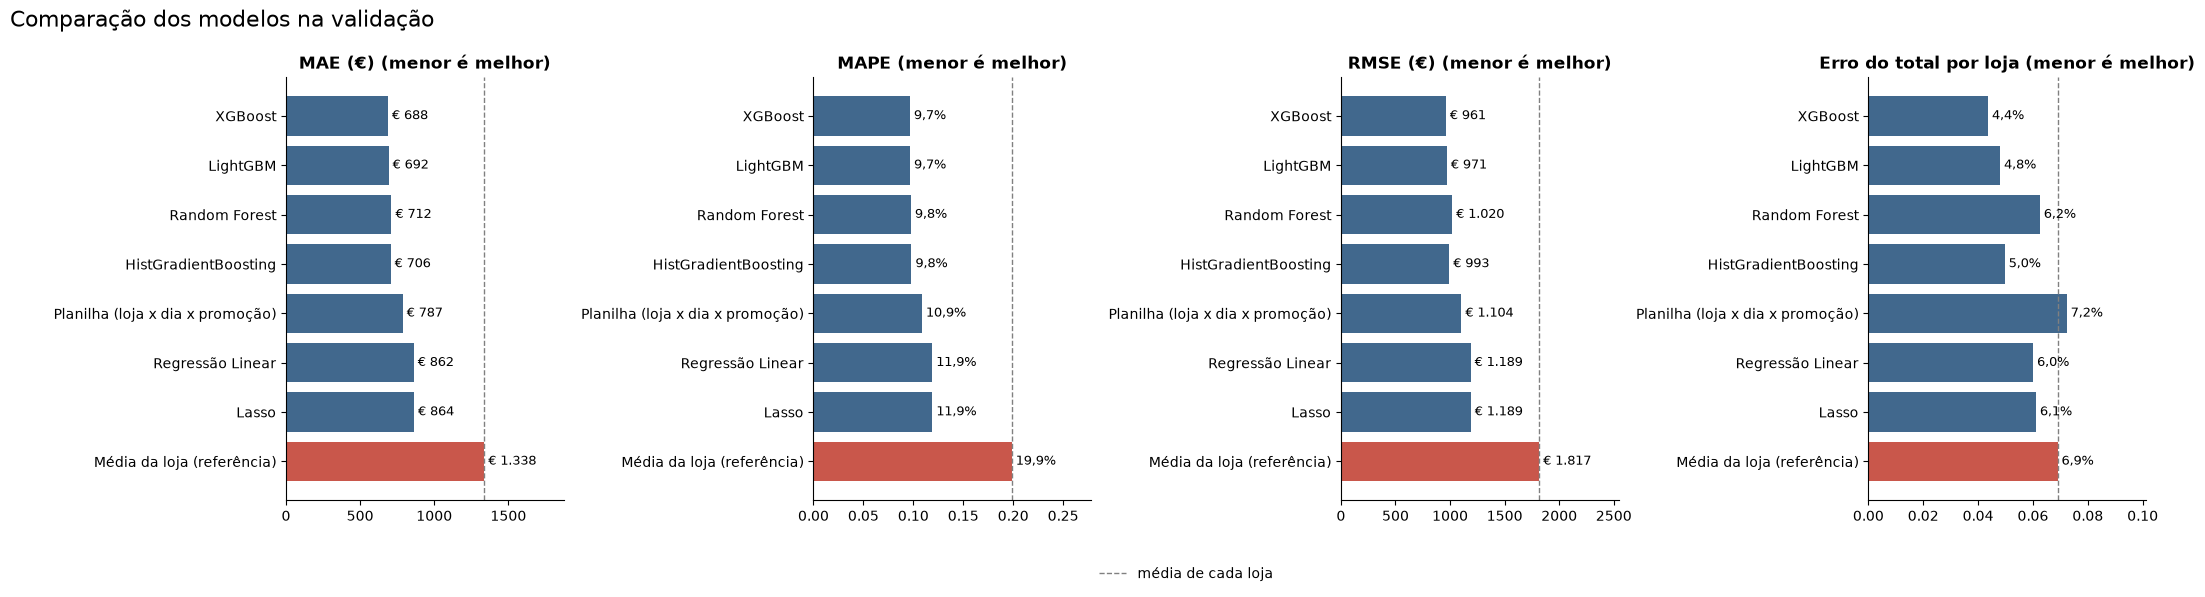

💾 Resultados salvos em: reports/comparacao_modelos.csv
Melhor MAPE na validação cruzada (decide o ajuste fino): XGBoost


,MAE,MAPE,RMSE,R²,Erro do total,MAPE CV,Erro do total CV,score geral (posição média)
XGBoost,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
LightGBM,2.000,2.000,2.000,2.000,2.000,3.000,2.000,2.143
HistGradientBoosting,3.000,4.000,3.000,3.000,3.000,2.000,3.000,3.000
Random Forest,4.000,3.000,4.000,4.000,6.000,4.000,4.000,4.143
Regressão Linear,6.000,6.000,6.000,6.000,4.000,6.000,5.000,5.571
Planilha (loja x dia x promoção),5.000,5.000,5.000,5.000,8.000,5.000,7.000,5.714
Lasso,7.000,7.000,7.000,7.000,5.000,7.000,6.000,6.571
Média da loja (referência),8.000,8.000,8.000,8.000,7.000,8.000,8.000,7.857


In [54]:
comparacao = pd.concat([metricas_media, metricas_planilha, metricas_lr, metricas_lasso, metricas_rf, metricas_xgb,
                        metricas_lgbm, metricas_hgb])
comparacao = comparacao.join(tabela_cv).sort_values('MAPE')
comparacao.to_csv('../reports/comparacao_modelos.csv')

display(comparacao.style.format({'MAE (€)': euros, 'MAPE': '{:.1%}', 'RMSE (€)': euros, 'R²': '{:.3f}', 'MPE': '{:+.1%}',
                                 'Erro do total por loja': '{:.1%}', 'MAE treino (€)': euros})
        .highlight_min(subset=['MAE (€)', 'MAPE', 'RMSE (€)', 'Erro do total por loja'], color='#C8E6C9')
        .highlight_max(subset=['R²'], color='#C8E6C9'))

plot_comparacao_modelos(comparacao, 'Comparacao dos modelos')
print('💾 Resultados salvos em: reports/comparacao_modelos.csv')

# Score geral: posição média nas métricas da validação + MAPE e erro do total da validação cruzada (1 = melhor)
ranking = pd.DataFrame({'MAE': comparacao['MAE (€)'].rank(), 'MAPE': comparacao['MAPE'].rank(),
                        'RMSE': comparacao['RMSE (€)'].rank(), 'R²': comparacao['R²'].rank(ascending=False),
                        'Erro do total': comparacao['Erro do total por loja'].rank(),
                        'MAPE CV': pd.Series(mape_cv).rank(), 'Erro do total CV': pd.Series(total_cv).rank()})
ranking['score geral (posição média)'] = ranking.mean(axis=1)
referencias = ['Média da loja (referência)', 'Planilha (loja x dia x promoção)']
melhor_modelo = pd.Series(mape_cv).drop(referencias).idxmin()
print(f'Melhor MAPE na validação cruzada (decide o ajuste fino): {melhor_modelo}')
ranking.sort_values('score geral (posição média)')

📌 **Nota**
- 🔎 O **XGBoost** fica em **1º lugar em todas as 7 posições** do score geral: MAE, MAPE, RMSE, R² e erro do total na validação, e MAPE e erro do total na validação cruzada.
- 🔎 Contra a referência (média da loja), ele corta o erro do dia pela metade (**€ 688** contra **€ 1.338**) e o erro do total de **6,9%** para **4,4%**.
- 🔎 Todos os modelos de árvores têm **MPE negativo** na validação (de **−1,6%** a **−3,9%**): maio e junho de 2015 venderam acima do esperado.
- ✅ **Decisão:** ajustar os hiperparâmetros do XGBoost (item 7). A tabela completa está em `reports/comparacao_modelos.csv`.

## 7 - AJUSTE FINO DE HIPERPARÂMETROS

### 7.1. Random Search

Testamos **8 combinações** de hiperparâmetros do algoritmo com **menor MAPE na validação cruzada** (item 5), avaliando cada uma nas **3 janelas mais recentes** da validação cruzada no tempo (dentro do treino, sem tocar na validação). A escolha é pela de **menor MAPE**, medido em euros. O pré-processamento e as médias da loja ficam dentro do `Pipeline` e são reajustados em cada janela.

> 💻 São 8 combinações × 3 janelas com até 800 árvores: a célula leva cerca de **20 minutos**. Com mais memória e tempo, valeria testar mais combinações (próximos passos).

busca concluída em 2015s
Melhores hiperparâmetros: {'subsample': 1.0, 'n_estimators': 500, 'min_child_weight': 1, 'max_depth': 10, 'learning_rate': 0.05, 'colsample_bytree': 0.7}


,rank_test_score,MAPE,desvio,subsample,n_estimators,min_child_weight,max_depth,learning_rate,colsample_bytree
4,1,9.88%,0.97%,1.000000,500,1,10,0.050000,0.700000
5,2,10.39%,1.16%,1.000000,500,1,8,0.100000,0.850000
7,3,10.44%,1.07%,1.000000,300,1,8,0.050000,0.850000
2,4,10.50%,1.21%,0.800000,500,10,12,0.100000,0.850000
3,5,10.57%,1.40%,1.000000,300,50,12,0.050000,1.000000


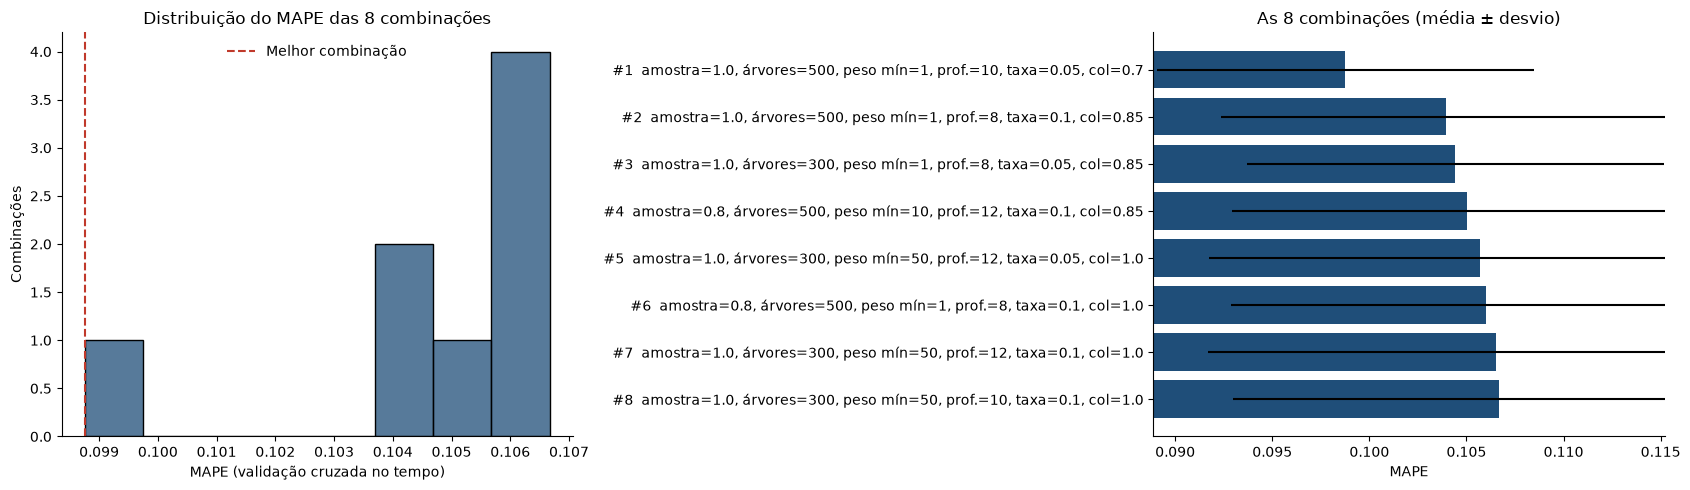

In [55]:
dobras_busca = dobras_temporais(treino['data'], n_dobras=3, semanas=6)
prefixo = 'regressor__modelo__'
espacos_busca = {
    'LightGBM': {'n_estimators': [400, 600, 800], 'learning_rate': [0.05, 0.1], 'num_leaves': [63, 127, 255],
                 'min_child_samples': [20, 50, 100], 'subsample': [0.8, 1.0], 'subsample_freq': [1],
                 'colsample_bytree': [0.7, 0.85, 1.0]},
    'XGBoost': {'n_estimators': [300, 500], 'learning_rate': [0.05, 0.1], 'max_depth': [8, 10, 12],
                'subsample': [0.8, 1.0], 'colsample_bytree': [0.7, 0.85, 1.0], 'min_child_weight': [1, 10, 50]},
    'HistGradientBoosting': {'learning_rate': [0.05, 0.1], 'max_iter': [400, 600, 800], 'max_leaf_nodes': [63, 127, 255],
                             'min_samples_leaf': [20, 50, 100], 'l2_regularization': [0, 1, 10]},
    'Random Forest': {'n_estimators': [60, 100], 'max_samples': [0.25, 0.4], 'min_samples_leaf': [2, 5, 10],
                      'max_features': [0.5, 0.7]},
}
busca = RandomizedSearchCV(clone(modelos[melhor_modelo]), {prefixo + k: v for k, v in espacos_busca[melhor_modelo].items()},
                           n_iter=8, cv=dobras_busca, scoring='neg_mean_absolute_percentage_error', random_state=SEMENTE,
                           n_jobs=1, refit=False)
t0 = time.time()
busca.fit(X_treino, y_treino)
print(f'busca concluída em {time.time() - t0:.0f}s')

resultados_busca = pd.DataFrame(busca.cv_results_)
resultados_busca['MAPE'] = -resultados_busca['mean_test_score']
resultados_busca['desvio'] = resultados_busca['std_test_score']
parametros = [coluna for coluna in resultados_busca.columns if coluna.startswith('param_')]
top5 = resultados_busca.sort_values('rank_test_score')[['rank_test_score', 'MAPE', 'desvio'] + parametros].head(5)
top5.columns = [coluna.replace('param_' + prefixo, '') for coluna in top5.columns]
melhores_parametros = {k.replace(prefixo, ''): v for k, v in busca.best_params_.items()}
print('Melhores hiperparâmetros:', melhores_parametros)
display(top5.style.format({'MAPE': '{:.2%}', 'desvio': '{:.2%}'}))

fig, axs = plt.subplots(1, 2, figsize=(17, 5))
sns.histplot(resultados_busca['MAPE'], bins=8, color=COR_PRINCIPAL, ax=axs[0])
axs[0].axvline(resultados_busca['MAPE'].min(), color=COR_DESTAQUE, ls='--', label='Melhor combinação')
axs[0].set(title='Distribuição do MAPE das 8 combinações', xlabel='MAPE (validação cruzada no tempo)', ylabel='Combinações')
axs[0].legend(frameon=False)
abreviacoes = {'learning_rate': 'taxa', 'n_estimators': 'árvores', 'max_iter': 'árvores', 'num_leaves': 'folhas',
               'max_leaf_nodes': 'folhas', 'min_child_samples': 'mín/folha', 'min_samples_leaf': 'mín/folha',
               'colsample_bytree': 'col', 'subsample': 'amostra', 'subsample_freq': 'freq', 'max_depth': 'prof.',
               'min_child_weight': 'peso mín', 'l2_regularization': 'l2', 'max_samples': 'amostra', 'max_features': 'col'}
ordenado = resultados_busca.sort_values('rank_test_score')
rotulos = [f"#{r['rank_test_score']}  " + ', '.join(f"{abreviacoes.get(p.replace('param_' + prefixo, ''), p)}={r[p]}"
                                               for p in parametros if 'freq' not in p) for _, r in ordenado.iterrows()]
axs[1].barh(rotulos[::-1], ordenado['MAPE'][::-1], xerr=ordenado['desvio'][::-1], color=COR_PRINCIPAL)
axs[1].set(title='As 8 combinações (média ± desvio)', xlabel='MAPE', xlim=(ordenado['MAPE'].min() * 0.9, ordenado['MAPE'].max() * 1.08))
sns.despine()
plt.tight_layout()
salvar('Random Search')
plt.show()

📌 **Nota**
- 🔎 A melhor combinação usa **500 árvores**, profundidade **10**, taxa de aprendizado **0,05** e **70%** das colunas por árvore, com MAPE de **9,88% ± 0,97%** nas 3 janelas da busca. A 2ª colocada fica em **10,39%**.
- 🔎 As melhores combinações têm árvores **mais profundas** e **mais numerosas** que o XGBoost padrão (300 árvores, profundidade 8).
- 🔎 A busca levou **1.961 s** (~33 min) com 8 combinações: com mais tempo e memória, valeria testar mais (próximos passos).
- ✅ **Decisão:** levar a melhor combinação para a validação (7.2).

### 7.2. Modelo ajustado

XGBoost ajustado treinado em 114s



AMOSTRA: GABARITO x PREVISÃO DA MÁQUINA (venda do dia em €)


,Loja,Gabarito,Previsão da máquina,Erro (€)
20796,540,"10,920.000","9,693.000","-1,227.000"
25008,976,"9,788.000","8,444.000","-1,344.000"
22176,805,"6,195.000","6,978.000",783.000
14914,265,"5,412.000","4,038.000","-1,374.000"
1067,1069,"6,098.000","6,264.000",166.000
13898,429,"5,267.000","5,075.000",-192.000


MÉTRICAS DE VALIDAÇÃO: XGBoost ajustado
MAE (€)                673.893
MAPE                     0.095
RMSE (€)               940.468
R²                       0.905
MPE                     -0.015
Erro do total por loja   0.039

MAE no treino: € 397 | na validação: € 674 | diferença: +277 €


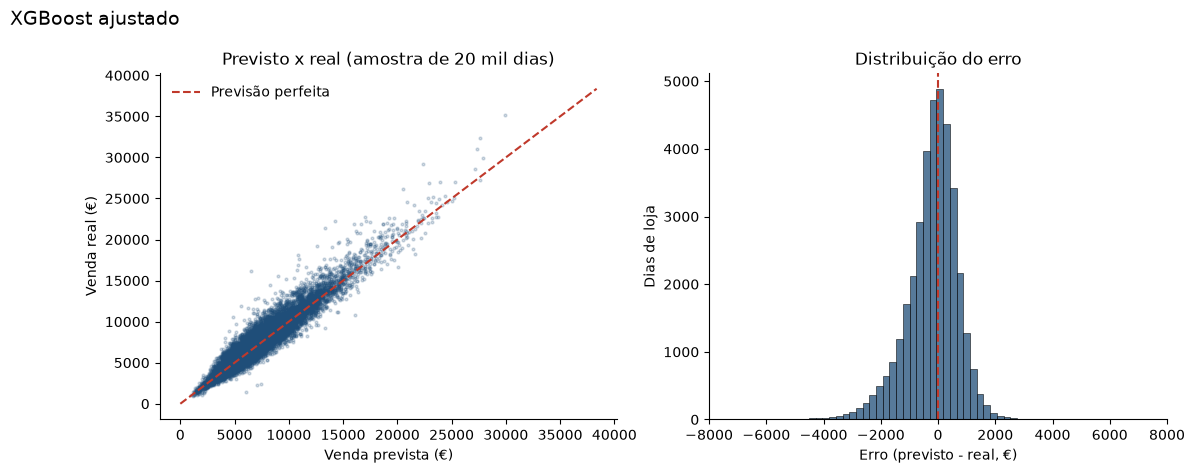

,MAE (€),MAPE,RMSE (€),R²,MPE,Erro do total por loja,MAE treino (€)
XGBoost,687.970,0.097,961.418,0.901,-0.016,0.044,452.471
XGBoost ajustado,673.893,0.095,940.468,0.905,-0.015,0.039,397.120


In [56]:
# O melhor conjunto, treinado no treino e avaliado na VALIDAÇÃO, comparado com a versão padrão
modelo_ajustado = clone(modelos[melhor_modelo]).set_params(**busca.best_params_)
t0 = time.time()
modelo_ajustado.fit(X_treino, y_treino)
print(f'{melhor_modelo} ajustado treinado em {time.time() - t0:.0f}s' + chr(10))
metricas_ajustado, previsto_ajustado = relatorio_validacao(f'{melhor_modelo} ajustado', modelo_ajustado,
                                                           X_treino, y_treino, X_validacao, y_validacao)
pd.concat([comparacao.loc[[melhor_modelo], metricas_ajustado.columns], metricas_ajustado]).round(3)

📌 **Nota**

| Na validação | XGBoost padrão | XGBoost ajustado |
|---|---|---|
| MAE | € 688 | **€ 674** |
| MAPE | 9,7% | **9,5%** |
| Erro do total por loja | 4,4% | **3,9%** |
| R² | 0,901 | **0,905** |

- 🔎 O ajuste melhora todas as métricas na validação, que **não participou** da busca. O ganho no total é o mais relevante: de **4,4%** para **3,9%**.
- 🔎 A distância entre treino e validação cresce (**€ 397** × **€ 674**), como esperado de árvores mais profundas, mas o erro na validação **cai**: o modelo aprendeu mais, sem decorar.
- ✅ **Decisão:** o XGBoost ajustado é o modelo final.

### 7.3. Modelo final

O modelo final é uma **cópia "zerada"** (`clone`) do modelo ajustado, com os mesmos hiperparâmetros, treinada em **treino + validação** (até 18/06/2015). Ele é avaliado no **teste** (19/06 a 31/07/2015) pela primeira e única vez.

In [57]:
modelo_final = clone(modelo_ajustado)
t0 = time.time()
modelo_final.fit(X_treino_val, y_treino_val)
print(f'Modelo final treinado em {time.time() - t0:.0f}s')

previsto_teste = modelo_final.predict(X_teste)
validacao_x_teste = pd.concat([ml_error('Validação (modelo ajustado)', y_validacao, previsto_ajustado),
                               ml_error('Teste (modelo final)', y_teste, previsto_teste)])
validacao_x_teste['Erro do total por loja'] = [erro_total_6_semanas(X_validacao['loja'], y_validacao, previsto_ajustado),
                                               erro_total_6_semanas(X_teste['loja'], y_teste, previsto_teste)]
validacao_x_teste.round(3)

Modelo final treinado em 115s


,MAE (€),MAPE,RMSE (€),R²,MPE,Erro do total por loja
Validação (modelo ajustado),673.893,0.095,940.468,0.905,-0.015,0.039
Teste (modelo final),613.542,0.092,903.628,0.912,0.023,0.037


📌 **Nota**
- 🔎 No **teste** (19/06 a 31/07/2015, aberto agora pela primeira vez), o modelo final erra **€ 614** por dia (MAPE de **9,2%**, R² de **0,912**), e o **total de 6 semanas** de cada loja erra **3,7%** em média.
- 🔎 O resultado no teste é **igual ou melhor** que na validação (**9,5%** e **3,9%**): o modelo final treinou com 6 semanas a mais, e não há sinal de que a escolha tenha sido "viciada" na validação.
- 🔎 O sinal do erro **inverte**: o MPE vai de **−1,5%** na validação para **+2,3%** no teste. No teste, o modelo **superestima** um pouco a venda.

## 8 - Otimização de limiar e calibração

### 8.1. Limiar de decisão

🚫 **Não se aplica.** O limiar serve para transformar uma **probabilidade** em uma **classe** (ex.: "fraude" ou "não fraude"). Aqui o modelo já devolve a própria **venda em euros**. No lugar do limiar, medimos **o quanto o total de 6 semanas pode errar**.

### 8.2. Faixa de erro do total de 6 semanas

O CFO não decide com a venda de um dia, e sim com o **total de 6 semanas de cada loja**. A faixa precisa ser medida nesse total.

> ⚠️ A versão original fazia "total previsto ± MAE", mas o MAE era o erro de **um dia**. Somar o erro de um dia ao total de 36 dias deixava a faixa estreita demais. Por exemplo, a loja 286 aparecia com "erro de 4%", quando o seu erro médio diário (MAPE) era de **44%**.

Medimos a faixa nas **5 janelas da validação cruzada** (item 4.1), e não só na validação. Em cada janela, o modelo ajustado treina com tudo o que vem antes e prevê as 6 semanas seguintes; para cada loja, comparamos o total real com o total previsto. São cerca de **5 × 1.115 totais**, de períodos diferentes (inclusive o Natal). Uma única janela pode pegar o modelo errando sempre para o mesmo lado e produzir uma faixa torta.

A faixa é **relativa**, entre o **10º e o 90º percentil** da razão real ÷ previsto, e cobre **80%** dos totais. Todas as janelas terminam antes do teste.

> 💻 São 4 treinos a mais do modelo ajustado (a última janela é a própria validação, já prevista no item 7.2): cerca de 7 minutos.

In [58]:
# Totais de 6 semanas por loja em cada janela: o modelo ajustado treina no passado da janela e prevê a janela
t0 = time.time()
totais_janelas = []
for i, (indices_treino, indices_avaliacao) in enumerate(dobras, 1):
    if X_treino_val.index[indices_avaliacao].equals(X_validacao.index):   # a última janela é a validação (item 7.2)
        previsto_janela = previsto_ajustado
    else:
        previsto_janela = (clone(modelo_ajustado).fit(X_treino_val.iloc[indices_treino], y_treino_val.iloc[indices_treino])
                           .predict(X_treino_val.iloc[indices_avaliacao]))
    totais_janelas.append(totais_por_loja(X_treino_val['loja'].iloc[indices_avaliacao], y_treino_val.iloc[indices_avaliacao],
                                          previsto_janela).assign(janela=i))
totais_janelas = pd.concat(totais_janelas)
print(f'5 janelas avaliadas em {time.time() - t0:.0f}s | totais de loja: {len(totais_janelas):,}'.replace(',', '.'))

# O viés muda de uma janela para outra: é por isso que uma janela só não basta
razao_janelas = totais_janelas['real'] / totais_janelas['previsto']
display(pd.DataFrame({'lojas': totais_janelas.groupby('janela').size(),
                      'real ÷ previsto (mediana)': razao_janelas.groupby(totais_janelas['janela']).median(),
                      'erro médio do total': totais_janelas['erro relativo'].abs().groupby(totais_janelas['janela']).mean()}
                     ).style.format({'real ÷ previsto (mediana)': '{:.1%}', 'erro médio do total': '{:.1%}'}))

totais_validacao = totais_janelas[totais_janelas['janela'] == len(dobras)]
faixa_validacao = faixa_relativa(totais_validacao['real'], totais_validacao['previsto'], cobertura=0.80)
faixa = faixa_relativa(totais_janelas['real'], totais_janelas['previsto'], cobertura=0.80)
print(f'Faixa medida só na validação (uma janela): {faixa_validacao[0]:.1%} a {faixa_validacao[1]:.1%} do previsto')
print(f'Faixa medida nas 5 janelas (a usada daqui em diante): {faixa[0]:.1%} a {faixa[1]:.1%} do previsto')
print(f'Exemplo: total previsto de € 250.000 -> faixa de {euros(250_000 * faixa[0])} a {euros(250_000 * faixa[1])}')

# Para comparar: a faixa da versão original (total ± erro médio de um dia da loja)
mae_dia_loja = (pd.DataFrame({'loja': X_validacao['loja'].to_numpy(), 'erro': np.abs(previsto_ajustado - y_validacao.to_numpy())})
                .groupby('loja')['erro'].mean())
dentro_v1 = ((totais_validacao['real'] >= totais_validacao['previsto'] - mae_dia_loja) &
             (totais_validacao['real'] <= totais_validacao['previsto'] + mae_dia_loja))
print(f'Faixa da v1 (total ± erro de um dia): largura média de ±{(mae_dia_loja / totais_validacao["previsto"]).mean():.1%}, '
      f'cobre {dentro_v1.mean():.1%} das lojas na validação')

5 janelas avaliadas em 392s | totais de loja: 5.396


,lojas,real ÷ previsto (mediana),erro médio do total
janela,,,
1,936,103.3%,4.6%
2,1115,97.4%,5.3%
3,1115,104.4%,5.0%
4,1115,101.9%,3.3%
5,1115,102.9%,3.9%


Faixa medida só na validação (uma janela): 97.7% a 108.1% do previsto
Faixa medida nas 5 janelas (a usada daqui em diante): 95.4% a 108.4% do previsto
Exemplo: total previsto de € 250.000 -> faixa de € 238.403 a € 271.072
Faixa da v1 (total ± erro de um dia): largura média de ±0.3%, cobre 5.1% das lojas na validação


### 8.3. Faixa de erro aplicada no teste

In [59]:
totais_teste = totais_por_loja(X_teste['loja'], y_teste, previsto_teste)
cobertura_teste = cobertura_faixa(totais_teste['real'], totais_teste['previsto'], faixa)
print(f'Lojas do teste com o total real dentro da faixa: {cobertura_teste:.1%} (esperado: 80%)')
print(f'Para comparar, a faixa medida só na validação cobriria {cobertura_faixa(totais_teste["real"], totais_teste["previsto"], faixa_validacao):.1%}')
acima_faixa = (totais_teste['real'] > totais_teste['previsto'] * faixa[1]).mean()
abaixo_faixa = (totais_teste['real'] < totais_teste['previsto'] * faixa[0]).mean()
print(f'  acima da faixa: {acima_faixa:.1%} | abaixo da faixa: {abaixo_faixa:.1%}')

tamanho_loja = pd.qcut(totais_teste['previsto'], 4, labels=['1º quartil (menores)', '2º quartil', '3º quartil', '4º quartil (maiores)'])
dentro = ((totais_teste['real'] >= totais_teste['previsto'] * faixa[0]) & (totais_teste['real'] <= totais_teste['previsto'] * faixa[1]))
pd.DataFrame({'lojas': dentro.groupby(tamanho_loja, observed=True).size(),
              'dentro da faixa': dentro.groupby(tamanho_loja, observed=True).mean(),
              'erro médio do total': totais_teste['erro relativo'].abs().groupby(tamanho_loja, observed=True).mean()}
             ).style.format({'dentro da faixa': '{:.1%}', 'erro médio do total': '{:.1%}'})

Lojas do teste com o total real dentro da faixa: 78.9% (esperado: 80%)
Para comparar, a faixa medida só na validação cobriria 60.4%
  acima da faixa: 2.6% | abaixo da faixa: 18.5%


,lojas,dentro da faixa,erro médio do total
previsto,,,
1º quartil (menores),279,71.3%,4.1%
2º quartil,279,81.0%,3.5%
3º quartil,278,79.9%,3.6%
4º quartil (maiores),279,83.5%,3.4%


📌 **Nota: medir a faixa em vários períodos cumpriu o prometido**
- 🔎 O viés do modelo **muda de janela para janela**: a mediana de real ÷ previsto vai de **97,4%** (2ª janela, o modelo superestima) a **104,4%** (3ª janela, o modelo subestima). A validação (5ª janela) ficou em **102,9%**.
- 🔎 Medida **só na validação**, a faixa seria de **97,7% a 108,1%**, puxada para cima porque ali o modelo subestimava. Medida nas **5 janelas** (**5.396** totais de loja), ela fica em **95,4% a 108,4%**: um pouco mais larga e com espaço para os dois lados.
- 🔎 No teste, a faixa das 5 janelas cobriu **78,9%** das lojas, perto dos **80%** prometidos. A faixa de uma janela só teria coberto **60,4%**. Fora da faixa, **18,5%** venderam menos que o mínimo provável e **2,6%** mais que o máximo: o viés do teste (item 7.3) ainda aparece, mas bem menor.
- 🔎 A cobertura vai de **71,3%** nas lojas menores a **83,5%** nas maiores. Nas lojas pequenas, o total oscila mais.
- 🔎 A faixa da versão original (total ± erro de **um** dia) tem largura média de **±0,3%** e cobre só **5,1%** das lojas.
- ✅ **Decisão:** usar a faixa das 5 janelas no app e na ficha. Ela foi escolhida **antes** de abrir o teste, pelo argumento de que uma janela só pode pegar o modelo errando sempre para o mesmo lado. O teste só confirmou.

### 8.4. Calibração

Um modelo **calibrado** acerta na média em todas as faixas: quando prevê € 10 mil num dia, a venda real desses dias deve ficar perto de € 10 mil. Separamos os dias do teste em 10 grupos pela previsão e comparamos a média prevista com a real.

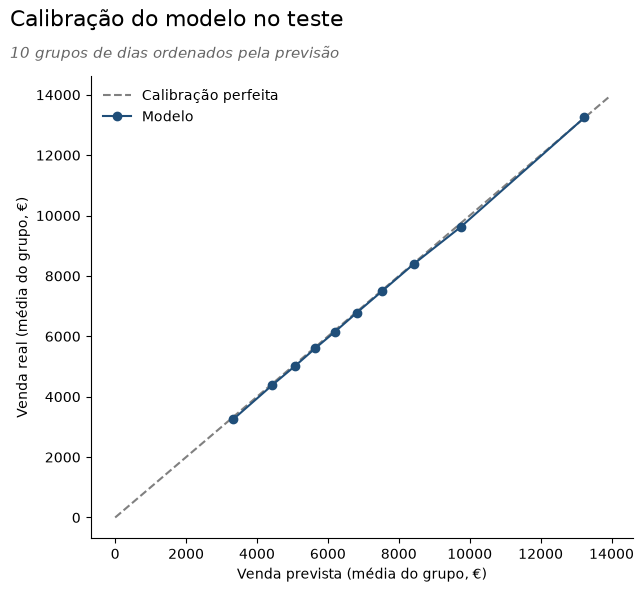

,previsto,real,diferenca
grupo,,,
0,€ 3.329,€ 3.251,-2.3%
1,€ 4.427,€ 4.381,-1.0%
2,€ 5.081,€ 5.025,-1.1%
3,€ 5.649,€ 5.610,-0.7%
4,€ 6.202,€ 6.154,-0.8%
5,€ 6.810,€ 6.778,-0.5%
6,€ 7.523,€ 7.491,-0.4%
7,€ 8.416,€ 8.390,-0.3%
8,€ 9.750,€ 9.625,-1.3%


In [60]:
calibracao = (pd.DataFrame({'previsto': previsto_teste, 'real': y_teste.to_numpy()})
              .assign(grupo=lambda t: pd.qcut(t['previsto'], 10, labels=False))
              .groupby('grupo').mean())

plt.figure(figsize=(7, 6))
limites = [0, calibracao.max().max() * 1.05]
plt.plot(limites, limites, color='gray', ls='--', label='Calibração perfeita')
plt.plot(calibracao['previsto'], calibracao['real'], marker='o', color=COR_PRINCIPAL, label='Modelo')
plt.xlabel('Venda prevista (média do grupo, €)')
plt.ylabel('Venda real (média do grupo, €)')
plt.legend(frameon=False)
sns.despine()
titulo('Calibração do modelo no teste', '10 grupos de dias ordenados pela previsão')
salvar('Calibracao do modelo')
plt.show()
calibracao.assign(diferenca=lambda t: t['real'] / t['previsto'] - 1).style.format(
    {'previsto': euros, 'real': euros, 'diferenca': '{:+.1%}'})

📌 **Nota**
- 🔎 Nos 10 grupos, a venda real fica entre **−2,3%** e **+0,1%** da prevista: o modelo é **bem calibrado**, com uma leve tendência a **superestimar** no teste (o mesmo MPE de **+2,3%** do item 7.3).
- 🔎 O maior desvio está nos dias de **menor** previsão (real **2,3%** abaixo), e o grupo das maiores previsões acerta a média (**+0,1%**).

## 9 - Teste anti-vazamento

Na seção 🛡️ da Fase 02, deixamos de fora os **clientes do dia**. Para mostrar o tamanho do problema que isso evita, fazemos duas comparações na validação:

| Teste | Por que é vazamento |
|---|---|
| **+ clientes**: o mesmo modelo ajustado, recebendo o número de clientes do dia | Os clientes só são conhecidos **depois** que o dia acaba, e a venda é praticamente clientes × gasto médio |
| **Média da loja da v1**: a média calculada nas próprias semanas avaliadas | Usa o **gabarito** para prever o gabarito |

,MAE (€),MAPE,RMSE (€),R²,MPE,Erro do total por loja
Modelo legítimo,673.893,0.095,940.468,0.905,-0.015,0.039
+ clientes do dia,386.954,0.053,545.577,0.968,-0.019,0.028
Média da loja da v1 (usa o gabarito),"1,256.126",0.195,"1,688.302",0.693,0.060,0.000


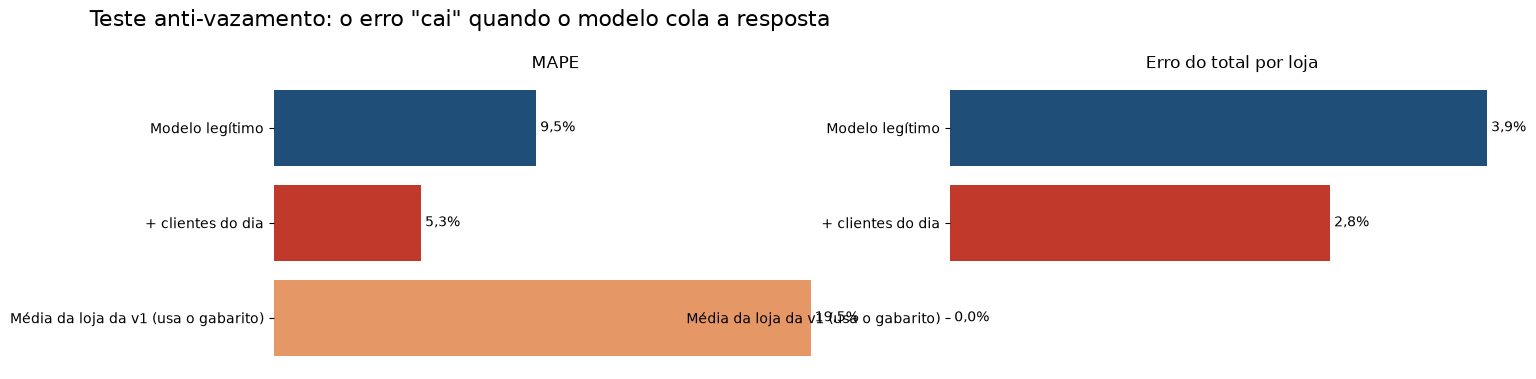

In [61]:
# Reintroduzindo os clientes para evidenciar por que foram excluídos
modelo_vazamento = clone(modelo_ajustado).fit(treino[FEATURES + PROIBIDAS], y_treino)
previsto_vazamento = modelo_vazamento.predict(validacao[FEATURES + PROIBIDAS])
vazamento = {
    'Modelo legítimo': metricas_ajustado.drop(columns='MAE treino (€)').iloc[0],
    '+ clientes do dia': ml_error('+ clientes', y_validacao, previsto_vazamento).assign(
        **{'Erro do total por loja': erro_total_6_semanas(X_validacao['loja'], y_validacao, previsto_vazamento)}).iloc[0],
    'Média da loja da v1 (usa o gabarito)': ml_error('v1', y_validacao, media_com_gabarito).assign(
        **{'Erro do total por loja': erro_total_6_semanas(X_validacao['loja'], y_validacao, media_com_gabarito)}).iloc[0],
}
tabela_vazamento = pd.DataFrame(vazamento).T
display(tabela_vazamento.round(3))

fig, axs = plt.subplots(1, 2, figsize=(16, 3.8))
for ax, metrica in zip(axs, ['MAPE', 'Erro do total por loja']):
    ax.barh(tabela_vazamento.index, tabela_vazamento[metrica], color=[COR_PRINCIPAL, COR_DESTAQUE, '#E59866'])
    ax.bar_label(ax.containers[0], labels=[pct(v, 1) for v in tabela_vazamento[metrica]], padding=3)
    ax.invert_yaxis()
    ax.set(title=metrica, xticks=[])
sns.despine(left=True, bottom=True)
titulo('Teste anti-vazamento: o erro "cai" quando o modelo cola a resposta')
salvar('Teste anti-vazamento')
plt.show()

### 🛡️ Resumo: houve vazamento? Foi resolvido?

| Pergunta | Resposta |
|---|---|
| Havia vazamento na base? | **Sim:** os **clientes do dia**, só conhecidos depois que o dia acaba |
| E na versão original? | **Sim, na régua:** o "modelo da média" usava as semanas avaliadas, e por isso acertava o total com **0,0%** de erro |
| Qual seria o efeito? | Com os clientes, o MAPE cai de **9,5%** para **5,3%** e o R² sobe de **0,905** para **0,968**: um modelo que parece quase perfeito e não pode ser usado |
| Foi resolvido? | ✅ **Sim:** `clientes` está em `PROIBIDAS`, as médias da loja são calculadas só no treino (dentro do `Pipeline`) e a referência usa só o treino |

📌 **Nota**
- 🔎 O erro do total "cai" de **3,9%** para **2,8%** com os clientes, e para **0,0%** na média da v1. Os dois números baixos são **ilusões**: dependem de informação que o CFO não tem quando faz o orçamento.

# FASE 04: AVALIAÇÃO

## 1 - Avaliando a Máquina Preditiva

In [62]:
# As réguas de comparação também são treinadas em treino + validação
referencia_final = MediaPorGrupo(('loja',)).fit(X_treino_val, y_treino_val)
planilha_final = MediaPorGrupo(('loja', 'dia_semana', 'promo')).fit(X_treino_val, y_treino_val)
avaliacao = {}
for nome, previsto in [('Média da loja (referência)', referencia_final.predict(X_teste)),
                       ('Planilha (loja x dia x promoção)', planilha_final.predict(X_teste)),
                       ('Modelo final', previsto_teste)]:
    avaliacao[nome] = ml_error(nome, y_teste, previsto).iloc[0].to_dict() | {
        'Erro do total por loja': erro_total_6_semanas(X_teste['loja'], y_teste, previsto)}
avaliacao = pd.DataFrame(avaliacao).T
# Resultado divulgado pela versão original nas mesmas 6 semanas (XGBoost ajustado)
avaliacao.loc['Versão original (XGBoost)', ['MAE (€)', 'MAPE', 'RMSE (€)', 'MPE']] = [933.19, 0.1332, 1355.21, -0.0112]
display(avaliacao.style.format({'MAE (€)': euros, 'MAPE': '{:.1%}', 'RMSE (€)': euros, 'R²': '{:.3f}', 'MPE': '{:+.1%}',
                                'Erro do total por loja': '{:.1%}'}, na_rep='—'))

,MAE (€),MAPE,RMSE (€),R²,MPE,Erro do total por loja
Média da loja (referência),€ 1.440,22.8%,€ 1.917,0.604,+6.6%,6.0%
Planilha (loja x dia x promoção),€ 739,10.7%,€ 1.101,0.869,+0.4%,6.1%
Modelo final,€ 614,9.2%,€ 904,0.912,+2.3%,3.7%
Versão original (XGBoost),€ 933,13.3%,€ 1.355,—,-1.1%,—


📌 **Nota: o modelo final no teste (as mesmas 6 semanas da versão original)**

| Modelo | MAE | MAPE | Erro do total por loja |
|---|---|---|---|
| Média da loja (referência) | € 1.440 | 22,8% | 6,0% |
| Planilha (loja × dia × promoção) | € 739 | 10,7% | 6,1% |
| Versão original (XGBoost) | € 933 | 13,3% | — |
| **Modelo final (v2)** | **€ 614** | **9,2%** | **3,7%** |

- 🔎 Contra a versão original, nas mesmas semanas, o erro do dia cai **34%** (de **€ 933** para **€ 614**), o MAPE cai de **13,3%** para **9,2%** e o RMSE, de **€ 1.355** para **€ 904**.
- 🔎 No número do CFO, o total de 6 semanas erra **3,7%**, contra **6,0%** da média da loja e **6,1%** da planilha: **39% menos erro** que a referência.
- 🔎 A versão original não media o erro do total por loja.

## 2 - Previsto x observado

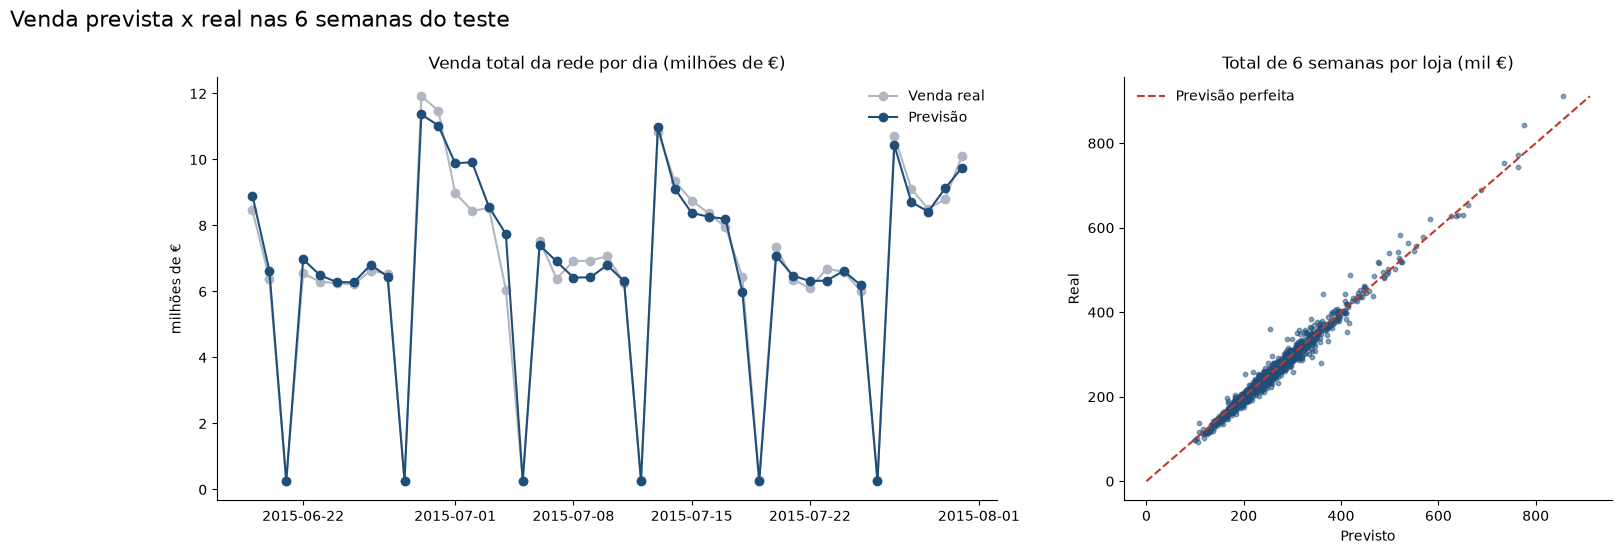

Total da rede no teste: real € 289.571.750 | previsto € 291.528.544 (+0.68%)
Lojas com o total errado em mais de 10%: 5.2% | em mais de 20%: 0.4%


In [63]:
por_dia = pd.DataFrame({'data': teste['data'].to_numpy(), 'real': y_teste.to_numpy(), 'previsto': previsto_teste}).groupby('data').sum()
fig, axs = plt.subplots(1, 2, figsize=(18, 5.5), gridspec_kw={'width_ratios': [1.6, 1]})
axs[0].plot(por_dia.index, por_dia['real'] / 1e6, marker='o', color=COR_NEUTRA, label='Venda real')
axs[0].plot(por_dia.index, por_dia['previsto'] / 1e6, marker='o', color=COR_PRINCIPAL, label='Previsão')
axs[0].set(title='Venda total da rede por dia (milhões de €)', ylabel='milhões de €')
axs[0].legend(frameon=False)
axs[1].scatter(totais_teste['previsto'] / 1e3, totais_teste['real'] / 1e3, s=10, alpha=0.5, color=COR_PRINCIPAL)
limites = [0, totais_teste[['previsto', 'real']].max().max() / 1e3]
axs[1].plot(limites, limites, color=COR_DESTAQUE, ls='--', label='Previsão perfeita')
axs[1].set(title='Total de 6 semanas por loja (mil €)', xlabel='Previsto', ylabel='Real')
axs[1].legend(frameon=False)
sns.despine()
titulo('Venda prevista x real nas 6 semanas do teste')
salvar('Previsto x observado')
plt.show()
print(f"Total da rede no teste: real {euros(por_dia['real'].sum())} | previsto {euros(por_dia['previsto'].sum())} "
      f"({por_dia['previsto'].sum() / por_dia['real'].sum() - 1:+.2%})")
print(f"Lojas com o total errado em mais de 10%: {(totais_teste['erro relativo'].abs() > 0.10).mean():.1%} | "
      f"em mais de 20%: {(totais_teste['erro relativo'].abs() > 0.20).mean():.1%}")

#### As lojas mais difíceis de prever

As lojas em que o total das 6 semanas mais errou, com a venda real e a prevista e o que elas têm de diferente.

,real,previsto,erro relativo,tipo_loja,sortimento,distancia_concorrente,promo2
loja,,,,,,,
909,€ 360.069,€ 254.926,-29.2%,a,estendido,"1,680",1
722,€ 279.296,€ 358.946,+28.5%,a,básico,50,0
292,€ 137.966,€ 108.846,-21.1%,a,básico,"1,100",0
274,€ 253.372,€ 201.703,-20.4%,b,extra,"3,640",1
578,€ 442.839,€ 363.544,-17.9%,d,básico,"12,700",0
604,€ 257.395,€ 301.507,+17.1%,d,básico,"10,950",0
840,€ 231.633,€ 270.475,+16.8%,a,básico,"1,070",0
1066,€ 352.903,€ 411.661,+16.7%,a,básico,"3,350",0


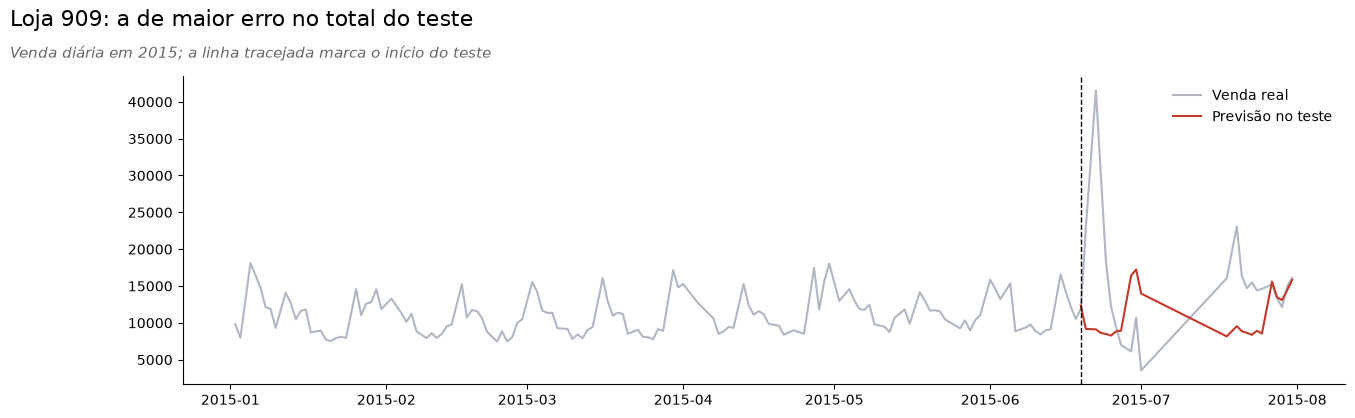

In [64]:
piores = totais_teste.assign(erro_abs=totais_teste['erro relativo'].abs()).nlargest(8, 'erro_abs')
piores = piores.join(lojas.set_index('loja')[['tipo_loja', 'sortimento', 'distancia_concorrente', 'promo2']])
display(piores.drop(columns='erro_abs').style.format({'real': euros, 'previsto': euros, 'erro relativo': '{:+.1%}',
                                                      'distancia_concorrente': '{:,.0f}'}))
# O que aconteceu com a pior loja: a venda diária real e a prevista
pior_loja = piores.index[0]
dias_pior = teste[teste['loja'] == pior_loja].assign(previsto=previsto_teste[(teste['loja'] == pior_loja).to_numpy()])
historico_pior = df[(df['loja'] == pior_loja) & (df['data'] >= '2015-01-01')].set_index('data')[ALVO]
fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(historico_pior.index, historico_pior.values, color=COR_NEUTRA, label='Venda real')
ax.plot(dias_pior['data'], dias_pior['previsto'], color=COR_DESTAQUE, label='Previsão no teste')
ax.axvline(pd.Timestamp(INICIO_TESTE), color='black', ls='--', lw=1)
ax.legend(frameon=False)
sns.despine()
titulo(f'Loja {pior_loja}: a de maior erro no total do teste', 'Venda diária em 2015; a linha tracejada marca o início do teste')
salvar('Loja mais dificil')
plt.show()

📌 **Nota**
- 🔎 Somando a rede inteira, o modelo previu **€ 291,5 milhões** para uma venda real de **€ 289,6 milhões** nas 6 semanas: erro de **+0,68%**. O gráfico diário acompanha os picos de segunda-feira e de promoção.
- 🔎 Loja a loja, só **5,2%** das lojas têm o total errado em mais de 10%, e **0,4%** em mais de 20%.
- 🔎 A pior é a **loja 909** (total **29,2%** abaixo do real). Ela teve o **maior dia da base** (€ 41.551) logo no início do teste, ficou **fechada cerca de duas semanas** em julho e voltou vendendo bem acima do normal, o que parece uma **reinauguração**. Nenhum modelo baseado no histórico prevê um evento assim.
- 💡 Na prática, o CFO deve **revisar à mão** as lojas com reforma, reinauguração ou mudança recente: são elas que concentram os erros grandes.

#### Tradução e interpretação do erro

Para o negócio, "MAPE de X%" é abstrato. Traduzimos o erro **por tipo de loja**, **por sortimento** e **por dia da semana**: a venda média real e prevista, o erro médio do dia (MAE e MAPE) e os cenários de **pior e melhor caso** (previsão ± erro médio do grupo). E, no número que importa ao CFO, o **erro do total de 6 semanas** de cada grupo.

POR TIPO DE LOJA


,casos,venda_real,venda_prevista,MAE,MAPE,pior cenário,melhor cenário,erro do total de 6 semanas
grupo,,,,,,,,
a,"22,295",€ 6.889,€ 6.947,€ 610,9.3%,€ 6.337,€ 7.556,3.9%
c,"5,476",€ 6.901,€ 6.883,€ 613,9.3%,€ 6.271,€ 7.496,3.5%
d,"12,894",€ 7.002,€ 7.079,€ 612,9.1%,€ 6.467,€ 7.690,3.4%
b,731,€ 10.831,€ 10.512,€ 768,7.5%,€ 9.744,€ 11.280,4.7%


POR SORTIMENTO


,casos,venda_real,venda_prevista,MAE,MAPE,pior cenário,melhor cenário,erro do total de 6 semanas
grupo,,,,,,,,
básico,"21,951",€ 6.523,€ 6.610,€ 572,9.4%,€ 6.037,€ 7.182,3.8%
estendido,"19,058",€ 7.484,€ 7.492,€ 660,9.1%,€ 6.832,€ 8.152,3.4%
extra,387,€ 9.706,€ 9.439,€ 644,7.5%,€ 8.794,€ 10.083,5.0%


POR DIA DA SEMANA


,casos,venda_real,venda_prevista,MAE,MAPE,pior cenário,melhor cenário
grupo,,,,,,,
Seg,"6,682",€ 8.216,€ 8.116,€ 642,8.0%,€ 7.474,€ 8.758
Ter,"6,682",€ 7.330,€ 7.294,€ 593,8.4%,€ 6.701,€ 7.886
Qua,"6,682",€ 6.814,€ 6.841,€ 576,8.6%,€ 6.265,€ 7.417
Qui,"6,680",€ 6.805,€ 6.937,€ 668,9.9%,€ 6.269,€ 7.605
Sex,"7,795",€ 7.101,€ 7.139,€ 552,8.0%,€ 6.587,€ 7.691
Sáb,"6,682",€ 5.644,€ 5.884,€ 656,12.6%,€ 5.228,€ 6.540
Dom,193,€ 8.513,€ 7.989,€ 762,10.7%,€ 7.227,€ 8.751


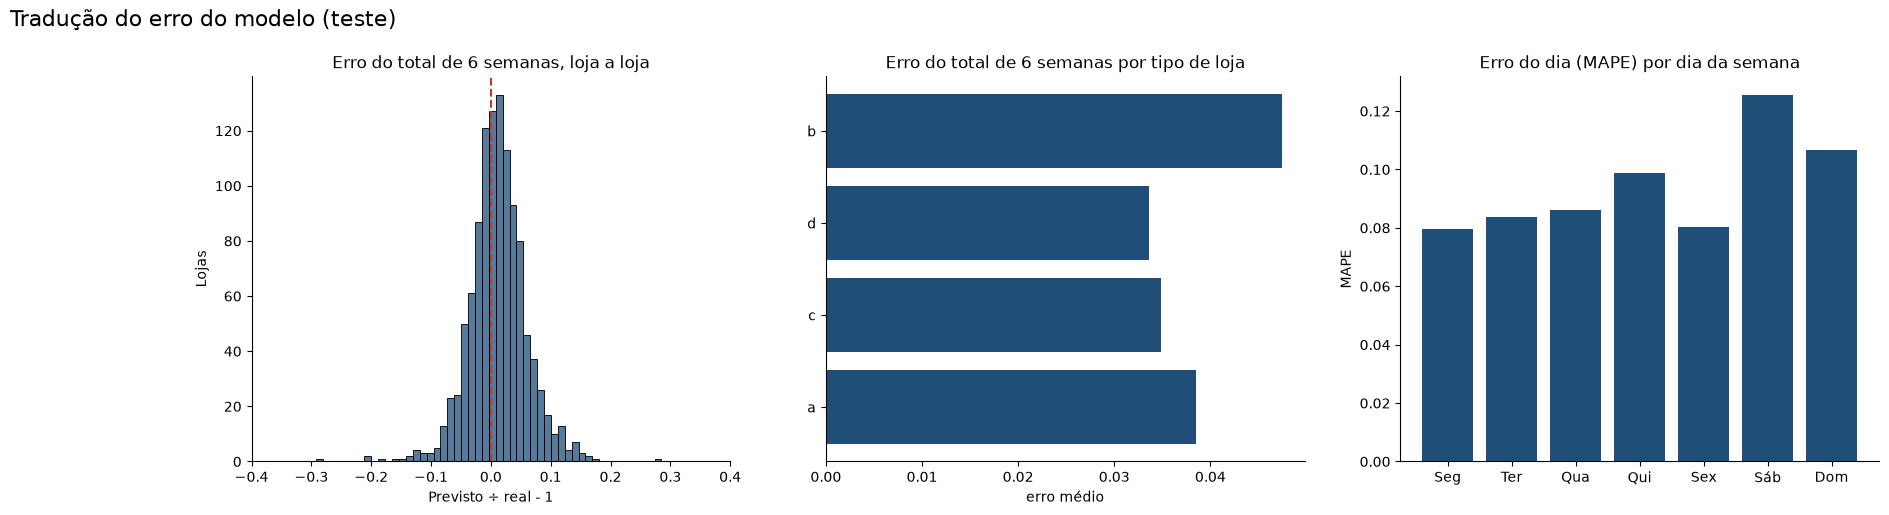

In [65]:
info_teste = teste[['loja', 'tipo_loja', 'sortimento', 'dia_semana']].reset_index(drop=True)
traducao_tipo = erro_por_grupo(y_teste, previsto_teste, info_teste['tipo_loja'])
traducao_sortimento = erro_por_grupo(y_teste, previsto_teste, info_teste['sortimento'])
traducao_dia = erro_por_grupo(y_teste, previsto_teste, info_teste['dia_semana'].map(dict(enumerate(nomes_dias, 1)))).loc[nomes_dias]
totais_com_tipo = totais_teste.join(lojas.set_index('loja')[['tipo_loja', 'sortimento']])
traducao_tipo['erro do total de 6 semanas'] = totais_com_tipo.groupby('tipo_loja')['erro relativo'].apply(lambda e: e.abs().mean())
traducao_sortimento['erro do total de 6 semanas'] = totais_com_tipo.groupby('sortimento')['erro relativo'].apply(lambda e: e.abs().mean())
traducao_tipo.to_csv('../reports/erro_por_tipo_de_loja.csv')
traducao_sortimento.to_csv('../reports/erro_por_sortimento.csv')

formato_traducao = {'venda_real': euros, 'venda_prevista': euros, 'MAE': euros, 'MAPE': '{:.1%}', 'pior cenário': euros,
                    'melhor cenário': euros, 'erro do total de 6 semanas': '{:.1%}', 'casos': '{:,.0f}'}
print('POR TIPO DE LOJA')
display(traducao_tipo.style.format(formato_traducao))
print('POR SORTIMENTO')
display(traducao_sortimento.style.format(formato_traducao))
print('POR DIA DA SEMANA')
display(traducao_dia.style.format(formato_traducao))

fig, axs = plt.subplots(1, 3, figsize=(21, 5))
sns.histplot(totais_teste['erro relativo'], bins=50, color=COR_PRINCIPAL, ax=axs[0])
axs[0].axvline(0, color=COR_DESTAQUE, ls='--')
axs[0].set(title='Erro do total de 6 semanas, loja a loja', xlabel='Previsto ÷ real - 1', ylabel='Lojas', xlim=(-0.4, 0.4))
axs[1].barh(traducao_tipo.index, traducao_tipo['erro do total de 6 semanas'], color=COR_PRINCIPAL)
axs[1].set(title='Erro do total de 6 semanas por tipo de loja', xlabel='erro médio')
axs[2].bar(nomes_dias, traducao_dia['MAPE'], color=COR_PRINCIPAL)
axs[2].set(title='Erro do dia (MAPE) por dia da semana', ylabel='MAPE')
sns.despine()
titulo('Tradução do erro do modelo (teste)')
salvar('Traducao do erro')
plt.show()

In [66]:
# O exemplo da versão original: a loja 286 nas 6 semanas do teste
loja_exemplo = totais_teste.loc[286]
print(f"Loja 286 | total real {euros(loja_exemplo['real'])} | previsto {euros(loja_exemplo['previsto'])} "
      f"({loja_exemplo['erro relativo']:+.1%})")
print(f"Faixa de 80% da v2: {euros(loja_exemplo['previsto'] * faixa[0])} a {euros(loja_exemplo['previsto'] * faixa[1])}")
mape_286 = ml_error('286', y_teste[(X_teste['loja'] == 286).to_numpy()], previsto_teste[(X_teste['loja'] == 286).to_numpy()])['MAPE'].iloc[0]
print(f'Erro médio do dia (MAPE) da loja 286 na v2: {mape_286:.1%}')

Loja 286 | total real € 136.447 | previsto € 157.250 (+15.2%)
Faixa de 80% da v2: € 149.955 a € 170.504
Erro médio do dia (MAPE) da loja 286 na v2: 17.1%


📌 **Nota: o erro, em termos de negócio**
- 🔎 **Por tipo de loja:** o erro do total de 6 semanas vai de **3,4%** (tipo d) a **4,7%** (tipo b). O tipo b tem o menor erro do dia (**7,5%**), mas são só 17 lojas, e uma loja difícil pesa muito na média.
- 🔎 **Por sortimento:** **3,4%** no estendido, **3,8%** no básico e **5,0%** no extra (9 lojas).
- 🔎 **Por dia da semana:** o **sábado** é o dia mais difícil (MAPE de **12,6%**, e o modelo superestima: **€ 5.884** previstos contra **€ 5.644** reais). Segunda e sexta são os mais fáceis (**8,0%**).
- 🔎 **O exemplo da versão original (loja 286):** total real de **€ 136.447** contra **€ 157.250** previstos (**+15,2%**), com erro diário (MAPE) de **17,1%**. O real ficou **abaixo** da faixa de 80% (**€ 149.955** a **€ 170.504**), um dos **18,5%** de lojas abaixo da faixa no item 8.3.
- ⚠️ A versão original apresentava essa loja com "erro de 4%" e MAPE de **44%**. ✅ Na v2, o erro diário cai para **17,1%**, e o erro do total é mostrado como ele é.

## 3 - Quais variáveis mais influenciam o modelo?

Usamos a **importância por permutação**: embaralhamos uma variável de cada vez no teste e medimos **quanto o erro piora**. Quanto mais o erro piora, mais o modelo depende daquela variável. A loja entra pelas suas médias: embaralhar a coluna `loja` troca as médias de uma loja pelas de outra.

loja                             +€ 2.036
promo                              +€ 585
dia_semana                         +€ 456
dia                                +€ 143
distancia_concorrente               +€ 55
semanas_promo2                      +€ 40
meses_concorrente                   +€ 37
feriado_escolar                     +€ 35
tipo_loja                           +€ 29
mes                                 +€ 19
sortimento                          +€ 17
semana_ano                           +€ 9
promo2_mes_ativo                     +€ 9
concorrente_data_desconhecida        +€ 6
promo2                               +€ 5
sem_concorrente                       € 0
feriado                               € 0
ano                                   € 0


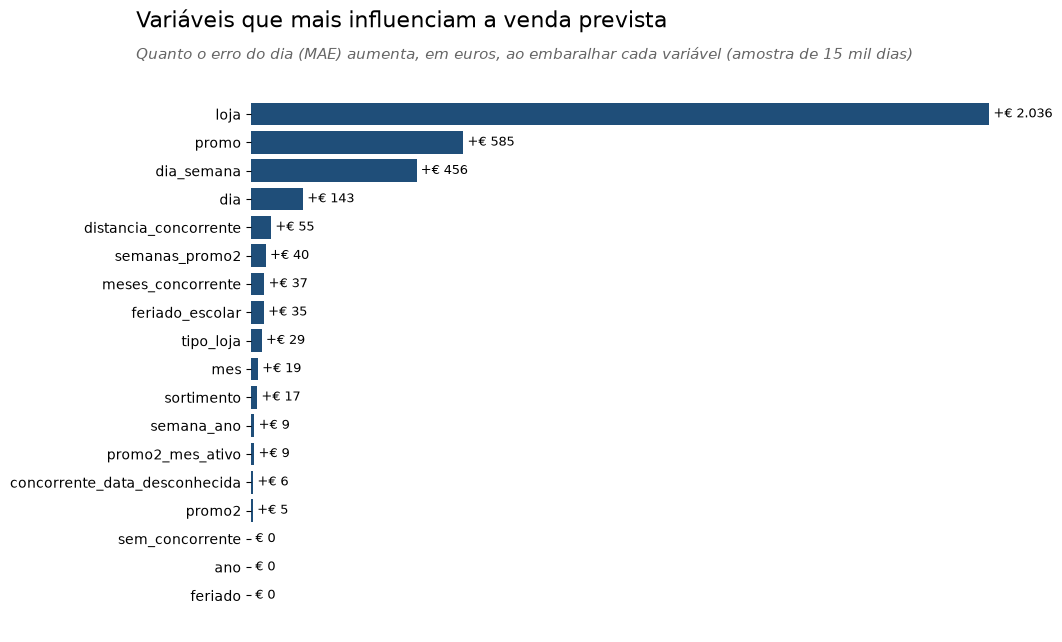

In [67]:
amostra_perm = X_teste.sample(15_000, random_state=SEMENTE).index
importancia = permutation_importance(modelo_final, X_teste.loc[amostra_perm], y_teste.loc[amostra_perm],
                                     scoring='neg_mean_absolute_error', n_repeats=5, random_state=SEMENTE, n_jobs=1)
importancia = pd.Series(importancia.importances_mean, index=X_teste.columns)
com_sinal = lambda v: ('+' if v >= 0.5 else '−' if v <= -0.5 else '') + euros(abs(v))
print(importancia.sort_values(ascending=False).map(com_sinal).to_string())

plot_barras_h(importancia, 'Variáveis que mais influenciam a venda prevista', 'Importancia por permutacao',
              subtitulo='Quanto o erro do dia (MAE) aumenta, em euros, ao embaralhar cada variável (amostra de 15 mil dias)',
              formato=com_sinal)

In [68]:
# Efeito isolado: o mesmo dia de uma loja típica, mudando uma condição de cada vez
dia_tipico = teste[(teste['loja'] == 1) & (teste['dia_semana'] == 3) & (teste['promo'] == 0)].iloc[[0]][FEATURES]
cenarios_efeito = {'Loja 1, quarta-feira sem promoção': dia_tipico,
                   'Com promoção': dia_tipico.assign(promo=1),
                   'Numa segunda-feira': dia_tipico.assign(dia_semana=1),
                   'Em dezembro (semana 51)': dia_tipico.assign(mes=12, semana_ano=51, dia=16),
                   'Com feriado escolar': dia_tipico.assign(feriado_escolar=1),
                   'Concorrente a 100 m': dia_tipico.assign(distancia_concorrente=100.0)}
efeitos = pd.Series({nome: modelo_final.predict(dados)[0] for nome, dados in cenarios_efeito.items()})
efeitos.to_frame('venda prevista').assign(**{'vs dia típico': efeitos / efeitos.iloc[0] - 1}).style.format(
    {'venda prevista': euros, 'vs dia típico': '{:+.0%}'})

,venda prevista,vs dia típico
"Loja 1, quarta-feira sem promoção",€ 3.808,+0%
Com promoção,€ 4.568,+20%
Numa segunda-feira,€ 4.261,+12%
Em dezembro (semana 51),€ 5.705,+50%
Com feriado escolar,€ 3.852,+1%
Concorrente a 100 m,€ 3.799,-0%


📌 **Nota**
- 🔎 A **loja** (pelas suas médias) é de longe a variável mais importante: embaralhá-la aumenta o erro do dia em **€ 2.036**. Depois vêm a **promoção** (**+€ 585**), o **dia da semana** (**+€ 456**) e o **dia do mês** (**+€ 143**).
- 🔎 O **ano**, o **feriado** e o indicador **sem concorrente** têm importância **zero** no teste (que não tem feriados e está todo em 2015).
- 🔎 **Efeito isolado** numa quarta-feira sem promoção da loja 1 (**€ 3.808**): com promoção, **+20%**; numa segunda-feira, **+12%**; na semana antes do Natal, **+50%**; com feriado escolar, **+1%**; com um concorrente a 100 m, **0%** (a distância fixa já está embutida nas médias da loja, H3).
- ✅ O modelo confirma a EDA: promoção (H1), dia da semana (H8) e Natal (H6) movem a venda; feriado escolar (H9) e distância (H3), não.

# FASE 05: IMPLANTAÇÃO

## 1 - Salvando o modelo

Para prever as **6 semanas seguintes** (agosto e setembro de 2015), o modelo de produção é o mesmo modelo final, **retreinado com todos os dias até 31/07/2015** (treino + validação + teste). Assim ele usa as semanas mais recentes, que são as mais parecidas com o futuro. A avaliação honesta já foi feita no teste (Fase 04); a faixa de erro medida lá vale para ele.

In [69]:
modelo_producao = clone(modelo_final)
t0 = time.time()
modelo_producao.fit(df[FEATURES], df[ALVO])
print(f'Modelo de produção treinado em {time.time() - t0:.0f}s com {len(df):,} dias'.replace(',', '.'))

joblib.dump({'modelo': modelo_producao, 'faixa': faixa, 'features': FEATURES}, '../Model/modelo_rossmann_v2.pkl', compress=3)

metricas_teste = avaliacao.loc['Modelo final']
ficha = salvar_ficha_modelo(
    '../Model/modelo_rossmann_v2.json',
    modelo=f'{melhor_modelo} ajustado (Pipeline: médias da loja + one-hot + {melhor_modelo}, alvo em log)',
    arquivo='modelo_rossmann_v2.pkl',
    treinado_com=f'{len(df):,} dias com venda de 1.115 lojas (01/01/2013 a 31/07/2015)'.replace(',', '.'),
    colunas_de_entrada=FEATURES, alvo='venda do dia em euros (dias com a loja aberta)',
    faixa_total_6_semanas=[round(faixa[0], 4), round(faixa[1], 4)],
    cobertura_faixa_teste=round(cobertura_teste, 4),
    metricas_teste={k: round(float(v), 4) for k, v in metricas_teste.items()},
    erro_total_referencia_teste=round(float(avaliacao.loc['Média da loja (referência)', 'Erro do total por loja']), 4),
    hiperparametros=melhores_parametros,
    avisos=['Prevê só dias com a loja ABERTA: dias fechados (domingos, feriados, reformas) devem ser zerados antes da soma.',
            'A faixa de 80% vale para o TOTAL de 6 semanas da loja, não para a venda de um dia.',
            'Não use o número de clientes do dia como entrada: só é conhecido depois do dia (vazamento).',
            'As médias de cada loja vêm do histórico até 31/07/2015: uma loja nova (sem histórico) recebe a média da rede.',
            'Vendas em euros, de 2013 a 2015: valores atuais exigem retreinar com dados recentes.'],
)
ficha

Modelo de produção treinado em 128s com 844.338 dias


{'data_treino': '2026-10-25 00:53',
 'modelo': 'XGBoost ajustado (Pipeline: médias da loja + one-hot + XGBoost, alvo em log)',
 'arquivo': 'modelo_rossmann_v2.pkl',
 'treinado_com': '844.338 dias com venda de 1.115 lojas (01/01/2013 a 31/07/2015)',
 'colunas_de_entrada': ['loja',
  'feriado',
  'tipo_loja',
  'sortimento',
  'dia_semana',
  'promo',
  'feriado_escolar',
  'distancia_concorrente',
  'sem_concorrente',
  'meses_concorrente',
  'concorrente_data_desconhecida',
  'promo2',
  'semanas_promo2',
  'promo2_mes_ativo',
  'ano',
  'mes',
  'dia',
  'semana_ano'],
 'alvo': 'venda do dia em euros (dias com a loja aberta)',
 'faixa_total_6_semanas': [0.9536, 1.0843],
 'cobertura_faixa_teste': 0.7892,
 'metricas_teste': {'MAE (€)': 613.542,
  'MAPE': 0.0921,
  'RMSE (€)': 903.6276,
  'R²': 0.9119,
  'MPE': 0.0231,
  'Erro do total por loja': 0.0367},
 'erro_total_referencia_teste': 0.0604,
 'hiperparametros': {'subsample': 1.0,
  'n_estimators': 500,
  'min_child_weight': 1,
  'max_

📌 **Nota**
- 🔎 O modelo de produção foi retreinado com os **844.338 dias** (até 31/07/2015) e salvo em `Model/modelo_rossmann_v2.pkl` (cerca de **14 MB**), junto com a faixa e a lista de variáveis.
- 🔎 A **ficha** (`Model/modelo_rossmann_v2.json`) guarda o que é preciso para usar o modelo corretamente: as variáveis de entrada, a faixa (**95,4% a 108,4%**) com a **cobertura real no teste (78,9%)**, as métricas no teste, os hiperparâmetros e **5 avisos** (dias fechados, faixa só para o total, vazamento dos clientes, lojas novas e data dos dados).
- 🔎 O `model_rossmann.pkl` da versão original continua na pasta, como histórico.

## 2 - Aplicando uma simulação

A simulação é a previsão de verdade: o arquivo **`test.csv`** do Kaggle traz as **6 semanas seguintes** (01/08 a 17/09/2015) de 856 lojas, com o calendário, as promoções planejadas e se a loja abre, mas **sem as vendas**. O modelo prevê os dias abertos; os dias fechados ficam com venda zero.

In [70]:
modelo_salvo = joblib.load('../Model/modelo_rossmann_v2.pkl')
futuro = carregar_futuro(ARQUIVO_FUTURO, ARQUIVO_LOJAS)
abertos = futuro['aberta'] == 1
futuro['previsao'] = 0.0
futuro.loc[abertos, 'previsao'] = modelo_salvo['modelo'].predict(futuro.loc[abertos, modelo_salvo['features']])
futuro[['loja', 'data', 'dia_semana', 'aberta', 'promo', 'previsao']].to_csv('../reports/previsoes_6_semanas.csv', index=False)

previsao_lojas = futuro.groupby('loja')['previsao'].sum().rename('previsto').to_frame()
previsao_lojas['mínimo provável'] = previsao_lojas['previsto'] * modelo_salvo['faixa'][0]
previsao_lojas['máximo provável'] = previsao_lojas['previsto'] * modelo_salvo['faixa'][1]
print(f"Período: {futuro['data'].min():%d/%m/%Y} a {futuro['data'].max():%d/%m/%Y} | lojas: {futuro['loja'].nunique()} | "
      f"dias abertos: {abertos.sum():,} de {len(futuro):,}".replace(',', '.'))
print(f"Venda prevista da rede (856 lojas): {euros(previsao_lojas['previsto'].sum())} "
      f"(faixa de {euros(previsao_lojas['mínimo provável'].sum())} a {euros(previsao_lojas['máximo provável'].sum())})")
print('💾 Previsões salvas em: reports/previsoes_6_semanas.csv')
print(chr(10) + 'As 5 lojas com maior venda prevista:')
display(previsao_lojas.nlargest(5, 'previsto').style.format(euros))
print('Orçamento de reforma com 5% do faturamento previsto (as 5 primeiras lojas):')
(previsao_lojas['previsto'] * 0.05).rename('verba de reforma (5%)').nlargest(5).to_frame().style.format(euros)

Período: 01/08/2015 a 17/09/2015 | lojas: 856 | dias abertos: 35.104 de 41.088
Venda prevista da rede (856 lojas): € 240.056.873 (faixa de € 228.921.483 a € 260.291.037)
💾 Previsões salvas em: reports/previsoes_6_semanas.csv

As 5 lojas com maior venda prevista:


,previsto,mínimo provável,máximo provável
loja,,,
262,€ 961.162,€ 916.577,€ 1.042.178
1114,€ 884.143,€ 843.131,€ 958.667
562,€ 832.327,€ 793.718,€ 902.483
842,€ 781.856,€ 745.588,€ 847.758
251,€ 772.123,€ 736.307,€ 837.204


Orçamento de reforma com 5% do faturamento previsto (as 5 primeiras lojas):


,verba de reforma (5%)
loja,
262,€ 48.058
1114,€ 44.207
562,€ 41.616
842,€ 39.093
251,€ 38.606


📌 **Nota: a previsão de verdade**
- 🔎 Para as 6 semanas de **01/08 a 17/09/2015**, o modelo previu os **35.104 dias abertos** de **856 lojas** (dos 41.088 dias, os fechados ficam com zero).
- 🔎 A venda prevista da rede é de **€ 240,1 milhões**, com faixa de **€ 228,9 milhões a € 260,3 milhões**.
- 🔎 A loja com maior venda prevista é a **262** (tipo b), com **€ 961.162**. Reservando **5%** do faturamento para reforma, ela receberia **€ 48.058**.
- 🔎 As previsões dia a dia ficam em `reports/previsoes_6_semanas.csv`, que alimenta o app Streamlit.

# ✅ RESPOSTA À PERGUNTA DE NEGÓCIO

| # | Pergunta | Resposta | Onde está |
|---|---|---|---|
| 1 | Quanto cada loja vai vender nas próximas 6 semanas, e com que margem? | O modelo prevê o total de cada loja com erro médio de **3,7%** no teste (contra **6,0%** da média da loja). A faixa de 80%, medida em 5 períodos de 6 semanas, cobriu **78,9%** das lojas no teste (a mesma faixa medida num período só teria coberto **60,4%**) | Fase 03 (itens 7 e 8) e Fase 04 |
| 2 | O que faz uma loja vender mais? | **Promoção** (**+38,8%**), **segunda-feira** e **dezembro** (**+24%**). A chegada de um **concorrente** tira **~6%**. Sortimento, tipo e distância do concorrente têm efeito pequeno: o que diferencia as lojas é o **tamanho** delas | H1 a H12 e Fase 04 (item 3) |
| 3 | Onde a previsão é mais confiável? | No total da rede (**+0,68%**) e na maioria das lojas (só **5,2%** erram o total em mais de 10%). É menos confiável aos **sábados**, nas lojas **tipo b** e **extra** e nas lojas com **eventos fora do padrão** (como a reinauguração da loja 909) | Fase 04 (item 2) |
| 4 | Quanto a rede pode reservar para reforma? | Com **5%** do faturamento previsto para ago–set/2015, a verba total é de cerca de **€ 12 milhões** (5% de € 240,1 milhões), loja a loja no app, com a opção conservadora pelo mínimo provável | Fase 05 e app Streamlit |

### As hipóteses, revisitadas

| # | Hipótese | Na EDA | No modelo |
|---|---|---|---|
| H1 | Promoção vende mais | ✅ **+38,8%** (€ 2.193/dia) | Confirmado: 2ª variável (**+€ 585**); **+20%** num dia típico |
| H6 | Vende mais no fim do ano | ✅ Dezembro **+24%** | Confirmado: a semana antes do Natal soma **+50%** num dia típico |
| H7 | Vende mais depois do dia 10 | ❌ Vende mais **antes** | O dia do mês é a 4ª variável (**+€ 143**) |
| H8 | Vende menos no fim de semana | ✅ Sábado (r −0,27) | Confirmado: 3ª variável (**+€ 456**); segunda **+12%**; sábado é o dia mais difícil (MAPE de 12,6%) |
| H2 / H4 | Sortimento e tipo de loja | ⚠️ Pequeno (ε² 0,028 e 0,011) | Confirmado: **+€ 17** e **+€ 29**; o tamanho da loja já entra pelas médias |
| H3 | Concorrente perto vende menos | ❌ Sem relação (rho −0,03) | Confirmado: concorrente a 100 m muda **0%** |
| H9 | Feriado escolar vende menos | ❌ Desprezível (€ 22/dia) | Confirmado: **+1%** num dia típico |

# 💡 INSIGHTS

| # | Insight | Para quem interessa |
|---|---|---|
| 1 | **Somar em vez de tirar a média inverteu 6 conclusões** da versão original (anos, 2º semestre, dia 10, feriado escolar, sortimento e tipo de loja). Uma soma mistura quanto cada loja vende com quantos dias e lojas o grupo tem | Qualquer analista: **compare médias, ou somas de grupos do mesmo tamanho** |
| 2 | **180 lojas somem da base por 6 meses** (jul–dez/2014). Sem perceber isso, 2014 parece um ano ruim | Qualquer analista: **conte quantas unidades aparecem em cada período** antes de comparar |
| 3 | **A promoção é a maior alavanca da rede: +38,8%** na venda do dia, em 99,9% das lojas. A versão original via só +12% | Marketing e CFO |
| 4 | **Um concorrente novo custa ~6% da venda** e a loja não recupera em 6 meses. A distância de um concorrente antigo não diz nada | Expansão e gerentes |
| 5 | **As lojas tipo b são diferentes:** quase 2 mil clientes por dia, gasto de € 5 por cliente. Parecem lojas de passagem | Operações e marketing |
| 6 | **O total de 6 semanas erra 3,7%, o dia erra 9,2%**: somando os dias, os erros se compensam. Para orçamento, o total é o número certo a acompanhar | CFO |
| 7 | **A régua da versão original colava a resposta:** a "média da loja" calculada nas semanas avaliadas acerta o total com 0,0% de erro | Qualquer analista: **a régua de comparação também precisa ser testada** |
| 8 | **A faixa de erro depende do período em que foi medida:** em maio e junho o modelo errava para baixo e no teste errou para cima. Medida só nesse período, a faixa cobriria **60,4%** em vez de 80%; medida em 5 períodos, cobriu **78,9%** | Quem for usar o modelo: **medir a incerteza em vários períodos** |
| 9 | **Os erros grandes vêm de eventos** (reformas, reinaugurações), não do dia a dia | CFO: **revisar à mão as lojas com mudanças recentes** |

### Os limites, ditos com todas as letras

- **A faixa ainda é um pouco otimista para baixo.** Ela cobriu **78,9%** no teste, mas **18,5%** das lojas venderam menos que o mínimo provável (contra 10% esperados), e nas lojas menores a cobertura cai para **71,3%**. A faixa é a mesma para todas as lojas, e a incerteza de uma loja pequena é maior.
- **Dados de 2013 a 2015.** O modelo não sabe nada de inflação, pandemia ou mudanças da rede depois de julho de 2015. Para usar hoje, é preciso retreinar com dados recentes.
- **Prevê só dias abertos.** O calendário de abertura precisa ser informado; uma loja que fecha para reforma no meio das 6 semanas tem a previsão superestimada se o fechamento não for avisado.
- **Eventos fora do padrão não são previstos:** reinaugurações (loja 909), reformas e a abertura de um concorrente durante as 6 semanas.
- **Lojas novas** (sem histórico) recebem a média da rede: a previsão delas é fraca.
- **Não há dado de causa:** a Promo2 está ligada a vendas menores (H10), mas a base não permite saber se a promoção atrapalha ou se foi dada às lojas mais fracas.
- **Busca de hiperparâmetros enxuta:** 8 combinações, por limite de memória e tempo. Os três modelos de árvores ficaram empatados na validação cruzada, e outro ajuste poderia trocar o vencedor.

# 🚀 PRÓXIMOS PASSOS

1. **Faixa por tamanho de loja:** medir a faixa das 5 janelas separadamente por faixa de venda (ou com intervalos conformes condicionais, *conformal prediction*), porque as lojas menores ficaram com cobertura de **71,3%**. É o que mais afeta a decisão do CFO.
2. **Corrigir a tendência:** acrescentar uma variável de tendência por loja (ex.: crescimento dos últimos 3 meses) para reduzir a troca de viés entre períodos.
3. **Marcar eventos:** usar os períodos em que a loja ficou fechada por vários dias (reformas) como variável, e um aviso no app para lojas com fechamento recente.
4. **Busca de hiperparâmetros maior** e comparação com o LightGBM ajustado, que empatou com o XGBoost e treina em um terço do tempo.
5. **Dados externos:** clima e feriados regionais (os estados alemães têm calendários escolares diferentes), que a competição permitia usar.
6. **Publicar o app** no Streamlit Community Cloud e gravar um GIF para o README.

# 🖥️ Interface com Streamlit

A versão original entregava as previsões por um **bot no Telegram**, com uma API hospedada no Heroku. O plano gratuito do Heroku acabou em 2022 e o bot parou de funcionar; as pastas `rossmann/` e `rossmann-telegram-api/` ficam no repositório como histórico.

Na v2, criamos um app em **Streamlit** com 3 abas:
1. **Loja:** escolhe uma loja e vê o **total previsto das 6 semanas**, com o **mínimo e o máximo prováveis** (faixa de 80%), o cadastro da loja e a venda prevista de cada dia.
2. **Orçamento de reforma:** escolhe a **parcela do faturamento** destinada à reforma e vê a verba de cada loja e da rede, com a opção de um orçamento **conservador** (pelo mínimo provável). A tabela pode ser baixada em CSV.
3. **Sobre o modelo:** erro do total por loja e erro diário no teste, comparados com a média da loja, e os avisos da ficha do modelo.

A célula abaixo grava o arquivo `app.py` na raiz do projeto. Para executar (a partir da raiz):

```bash
pip install -r requirements.txt
streamlit run app.py
```

In [71]:
%%writefile ../app.py
"""App Streamlit: previsão de vendas das próximas 6 semanas por loja e orçamento de reforma da rede Rossmann."""
import json
import sys
from pathlib import Path

import pandas as pd
import plotly.graph_objects as go
import streamlit as st

RAIZ = Path(__file__).resolve().parent
sys.path.append(str(RAIZ))

from src.config import ARQUIVO_LOJAS  # noqa: E402
from src.dados import carregar_lojas  # noqa: E402

st.set_page_config(page_title='Previsão de vendas Rossmann', page_icon='🏪', layout='wide')


@st.cache_data
def carregar_dados():
    previsoes = pd.read_csv(RAIZ / 'reports' / 'previsoes_6_semanas.csv', parse_dates=['data'])
    ficha = json.loads((RAIZ / 'Model' / 'modelo_rossmann_v2.json').read_text(encoding='utf-8'))
    return previsoes, carregar_lojas(ARQUIVO_LOJAS).set_index('loja'), ficha


def euros(valor):
    return '€ ' + f'{valor:,.0f}'.replace(',', '.')


previsoes, lojas, ficha = carregar_dados()
inferior, superior = ficha['faixa_total_6_semanas']
totais = previsoes.groupby('loja')['previsao'].sum().rename('previsto').to_frame()
totais['mínimo provável'] = totais['previsto'] * inferior
totais['máximo provável'] = totais['previsto'] * superior
periodo = f"{previsoes['data'].min():%d/%m/%Y} a {previsoes['data'].max():%d/%m/%Y}"

st.title('🏪 Quanto cada loja vai vender nas próximas 6 semanas?')
st.caption(f'Previsão de {periodo} para as {len(totais)} lojas da base pública Rossmann (Kaggle), em euros. '
           f'A faixa cobre o total real de {ficha["cobertura_faixa_teste"]:.0%} das lojas no teste.')

aba_loja, aba_reforma, aba_modelo = st.tabs(['🏪 Loja', '🧾 Orçamento de reforma', 'ℹ️ Sobre o modelo'])

with aba_loja:
    loja = st.selectbox('Loja', totais.index.tolist(), index=0)
    total = totais.loc[loja]
    col1, col2, col3 = st.columns(3)
    col1.metric('Vendas previstas (6 semanas)', euros(total['previsto']))
    col2.metric('Mínimo provável', euros(total['mínimo provável']))
    col3.metric('Máximo provável', euros(total['máximo provável']))
    cadastro = lojas.loc[loja]
    distancia = ('sem concorrente informado' if pd.isna(cadastro['distancia_concorrente'])
                 else f"concorrente a {cadastro['distancia_concorrente']:,.0f} m".replace(',', '.'))
    st.caption(f"Tipo de loja {cadastro['tipo_loja']} · sortimento {cadastro['sortimento']} · {distancia} · "
               f"{'participa' if cadastro['promo2'] == 1 else 'não participa'} da Promo2")

    diaria = previsoes[previsoes['loja'] == loja].sort_values('data')
    figura = go.Figure(go.Bar(x=diaria['data'], y=diaria['previsao'], marker_color='#1F4E79',
                              hovertemplate='%{x|%d/%m/%Y}: € %{y:,.0f}<extra></extra>'))
    figura.update_layout(height=320, margin=dict(t=10, b=10), yaxis_title='Venda prevista no dia (€)')
    st.plotly_chart(figura, use_container_width=True)
    st.caption(f"Dias fechados (domingos e feriados) aparecem com venda zero. "
               f"Dias com promoção: {int(diaria['promo'].sum())} de {len(diaria)}.")

with aba_reforma:
    st.subheader('Quanto reservar para a reforma de cada loja?')
    percentual = st.slider('Parcela do faturamento das 6 semanas destinada à reforma (%)', 1, 20, 5)
    conservador = st.toggle('Usar o mínimo provável (orçamento conservador)', value=False)
    base_calculo = totais['mínimo provável'] if conservador else totais['previsto']
    orcamento = (base_calculo * percentual / 100).rename('verba de reforma').to_frame()
    orcamento['vendas usadas no cálculo'] = base_calculo
    col1, col2 = st.columns(2)
    col1.metric('Verba total da rede', euros(orcamento['verba de reforma'].sum()))
    col2.metric('Verba média por loja', euros(orcamento['verba de reforma'].mean()))
    ranking = orcamento.sort_values('verba de reforma', ascending=False)
    st.dataframe(ranking.style.format(euros), use_container_width=True, height=420)
    st.download_button('Baixar a tabela (CSV)', ranking.round(2).to_csv().encode('utf-8'), 'orcamento_reforma.csv')

with aba_modelo:
    metricas = ficha['metricas_teste']
    col1, col2, col3, col4 = st.columns(4)
    col1.metric('Erro do total por loja', f"{metricas['Erro do total por loja']:.1%}",
                help='Em média, quanto o total de 6 semanas previsto para uma loja erra o total real (teste)')
    col2.metric('Erro diário (MAPE)', f"{metricas['MAPE']:.1%}", help='Erro médio da venda de um dia, em %')
    col3.metric('Erro diário (MAE)', euros(metricas['MAE (€)']), help='Erro médio da venda de um dia, em euros')
    col4.metric('Referência: média da loja', f"{ficha['erro_total_referencia_teste']:.1%}",
                help='Erro do total por loja se a previsão fosse só a venda média de cada loja')
    st.markdown(f"**Modelo:** {ficha['modelo']}  \n**Treinado com:** {ficha['treinado_com']}")
    st.markdown('**Avisos:**\n' + '\n'.join(f'- {aviso}' for aviso in ficha['avisos']))

Overwriting ../app.py
